# BCI Motor-Imagery EEG — End-to-End Data Preparation Pipeline

**Task:** Left vs Right Motor Imagery (MI) · **Channels:** FZ, C3, CZ, C4 · **Source:** ~2160 CSV recordings + `labels.csv`

> **Revised working copy:** code has been reviewed and adjusted, but all previous outputs were cleared to prevent stale results from being mistaken for results of the revised pipeline. Run the notebook from the first cell on your dataset to regenerate reports and files.

---
## Section 1 — Project introduction

### 1.1 Objective
Produce a scientifically defensible, leakage-safe, model-ready dataset for Left-vs-Right MI classification — **or**, when essential metadata is missing, produce everything that can be prepared validly and state exactly what blocks supervised training.

### 1.2 Evidence-status convention (used throughout)
| Status | Meaning |
|---|---|
| **CONFIRMED** | Directly verified from the files, or documented by an authoritative source you supply |
| **INFERRED** | Estimated from the data with stated uncertainty. Used as a *working assumption*, never silently promoted to confirmed |
| **UNKNOWN** | Not available. Steps that depend on it are skipped or run in a metadata-free form |

### 1.3 Hard rules enforced by this notebook
1. Raw CSVs and `labels.csv` are never modified (fingerprinted at start, re-verified at the end).
2. Labels are aligned by row order **because the user confirmed this dataset rule**: sort EEG files by numeric file ID, pair them with the first N label rows, and ignore trailing excess labels. The generated filename→label mapping is saved and audited.
3. No subject / session / event information is invented.
4. No recording is removed silently: every exclusion is logged with stage and reason.
5. Label-blind QC: exclusion rules are decided **before** labels are looked at.
6. All fitted objects (scaler, feature pruning) are fitted on the **training split only**.
7. No random recording-level split. Splits are contiguous file-ID blocks separated by an embargo gap.

### 1.4 Workflow
```text
Raw CSVs (read-only) ──► §2 discovery + integrity ──► §3 label audit ──┐
                                   │                                    │ mapping verified?
                                   ▼                                    │
              §4.0 single-pass scan (stats · repeats · timestamps · PSD · cache)
                                   ▼
      §4 EDA ─► §5 sampling-rate inference + quality assessment ─► §6 spectral analysis
                                   ▼
        §7 preprocessing: detrend → [notch only if evidenced] → band-pass → trim edges
                                   ▼
          §8 features ─► §9 feature QC ─► §10 dataset construction
                                   ▼
   §11 block + embargo split ─► train-only scaling/pruning ─► §12 save ─► §13 validation + verdict
```

### 1.5 Dependencies
`numpy, pandas, scipy, scikit-learn, matplotlib, seaborn, tqdm` (+ `IPython`). No MNE required.

**Confirmed label rule (reported by the dataset supervisor):** pair the EEG files sorted by numeric file ID with `labels.csv` rows in their existing order. When labels outnumber recordings, use only the first N labels and ignore the trailing excess rows. For the current counts, that means 2160 paired rows and 240 ignored rows. The original `labels.csv` remains unchanged.


In [5]:
import os, re, json, math, hashlib, platform, sys, time, warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats, ndimage
from scipy.integrate import trapezoid
from tqdm.auto import tqdm

import sklearn
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", __import__("scipy").__version__, "| sklearn", sklearn.__version__)

numpy 2.5.5 | pandas 3.1.1 | scipy 1.18.1 | sklearn 1.9.1


---
## Section 2 — Configuration and dataset loading

### 2.1 Centralised configuration
Every tunable value lives in `CFG`. Paths can be overridden with environment variables (`BCI_DATA_ROOT`, `BCI_LABEL_PATH`, `BCI_OUT_DIR`) so the same notebook runs unchanged on another machine.

Values that encode a **decision** (thresholds, band edges) carry a short rationale; those that are heuristics are subjected to a **sensitivity analysis** later rather than trusted blindly.

**Metadata you may supply (leave `None` if you do not have a source):**
* `FS_CONFIRMED_HZ` + `FS_CONFIRMED_SOURCE` — official acquisition sampling rate.

**Label mapping:** the user-confirmed numeric-file-order rule is applied automatically; no separate mapping CSV is required. Its provenance is recorded in `CFG.MAPPING_SOURCE`.

In [6]:
CFG = SimpleNamespace(
    # ---------------- paths ----------------
    DATA_ROOT=Path(os.environ.get("BCI_DATA_ROOT", "..")).resolve(),
    NAME_PATTERN=re.compile(r"^cellula_MI_data_(\d+)$", re.IGNORECASE),
    # ---------------- recording format ----------------
    CHANNELS=["FZ", "C3", "CZ", "C4"],
    TIME_COL="Time",
    EXPECTED_ROWS=2500,
    # ---------------- metadata you may supply (None = unknown) ----------------
    FS_CONFIRMED_HZ=None,            # e.g. 250.0 ONLY if an authoritative source says so
    FS_CONFIRMED_SOURCE=None,        # e.g. "dataset README / supervisor e-mail 2026-xx-xx"
    ALLOW_INFERRED_FS=(os.environ.get("BCI_ALLOW_INFERRED_FS", "1") != "0"),          # True: use data-derived fs as a *labelled working assumption*; False: metadata-free analyses only
    MAPPING_PATH=None,  # not required: mapping is generated from the supervisor-confirmed row-order rule
    MAPPING_SOURCE=(os.environ.get("BCI_LABEL_ALIGNMENT_SOURCE") or "User confirmed in chat (2026-11-15): labels.csv rows correspond to EEG files sorted by ascending numeric file ID; keep the first N rows for the N files and exclude trailing excess rows."),
    # ---------------- reproducibility / runtime ----------------
    RANDOM_STATE=42,
    FORCE_RESCAN=False,              # True: ignore the on-disk scan cache
    MAX_FILES=int(os.environ["BCI_MAX_FILES"]) if os.environ.get("BCI_MAX_FILES") else None,  # debugging only
    # ---------------- spectral settings ----------------
    NPERSEG=512,                     # Welch segment (≈2 s at ~250 Hz → ~0.5 Hz resolution)
    BANDS={"theta": (4.0, 8.0), "mu": (8.0, 13.0), "beta": (13.0, 30.0)},
    TOTAL_BAND=(4.0, 40.0),          # denominator for relative power / spectral entropy
    PEAK_BAND=(4.0, 30.0),           # range searched for the peak-frequency feature
    PEAK_RATIO=10.0,                 # narrow-peak detection: PSD / local-median PSD  (10× = 10 dB)
    # ---------------- preprocessing (one pipeline for everything) ----------------
    BANDPASS_HZ=(3.0, 40.0),         # keeps 4–30 Hz bands inside the pass-band (edge roll-off kept outside them)
    FILTER_ORDER=4,                  # Butterworth, applied zero-phase (sosfiltfilt)
    NOTCH_HZ_OVERRIDE="auto",        # "auto" = only if spectral evidence supports it · None = never · float = force
    NOTCH_Q=30.0,
    NOTCH_SUPPORT_MIN=0.5,           # share of retained files showing a narrow peak at mains before a notch is justified
    EDGE_TRIM_S=0.5,                 # seconds discarded at both ends before feature extraction (filter edge effects)
    PER_RECORDING_ZSCORE=False,      # amplitude units are unknown → keep absolute scale; scale-free features are provided too
    ARTIFACT_Z=6.0,                  # robust-z for transient-sample counting (flag-only)
    # ---------------- quality assessment ----------------
    AMP_MODZ=3.5,                    # modified z-score cut-off (Iglewicz & Hoaglin) for population outlier flags
    FLAT_RUN_MIN=25,                 # partial flat-line run (samples) — heuristic, sensitivity analysed
    RATE_DEV_TOL=0.02,               # per-file sampling-rate deviation from the population (2 %)
    REPEAT_TOLERANCE=0.10,           # tolerated median |Δ log band-power| caused by repeated samples → derives review threshold
    EXCLUDE_HIGH_REPEAT=False,        # Repeated samples are QC flags only; never exclude a recording for duplicates
    SIM_FILES=40,
    SIM_FRACTIONS=[0.002, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.40],
    SIM_TOLERANCES=[0.05, 0.10, 0.20, 0.30],
    # ---------------- splitting ----------------
    SPLIT_FRACTIONS=(0.70, 0.15, 0.15),   # train / validation / test (by number of recordings)
    BLOCK_SIZE=None,                 # None = derive from autocorrelation of neighbouring files (min BLOCK_SIZE_MIN)
    BLOCK_SIZE_MIN=30,
    EMBARGO=None,                    # None = derive (files dropped on the lower-priority side of every split boundary)
    EMBARGO_MAX=20,
    ACF_THRESHOLD=0.2,
    CORR_PRUNE=0.95,                 # |Spearman| above which the lower-priority twin is dropped (train rows only)
)
CFG.LABEL_PATH = Path(os.environ.get("BCI_LABEL_PATH", CFG.DATA_ROOT / "labels.csv"))
CFG.OUT_DIR = Path(os.environ.get("BCI_OUT_DIR", CFG.DATA_ROOT / "bci_prepared"))

DIRS = {k: CFG.OUT_DIR / v for k, v in dict(
    config="00_config", audit="01_audit", cache="cache", preprocessed="02_preprocessed",
    features="03_features", labels="04_labels", splits="05_splits", reports="06_reports", figures="figures").items()}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

CH = CFG.CHANNELS
def seeded(offset=0):
    """Fresh deterministic RNG — results do not depend on cell execution order."""
    return np.random.default_rng(CFG.RANDOM_STATE + offset)

def show(fig, name=None):
    """Tight-layout, optionally save to figures/, then display."""
    fig.tight_layout()
    if name:
        fig.savefig(DIRS["figures"] / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ---- evidence registry: what is CONFIRMED / INFERRED / UNKNOWN --------------------------------------
META = []
def register(item, value, status, evidence=""):
    assert status in {"CONFIRMED", "INFERRED", "UNKNOWN"}
    META[:] = [m for m in META if m["item"] != item]
    META.append(dict(item=item, value=value, status=status, evidence=evidence))
def show_registry():
    display(pd.DataFrame(META))

ISSUES = []   # unresolved issues, reported again in the final verdict
register("Channel order", ", ".join(CH), "CONFIRMED", "column names in every file are validated in the scan")
register("Sampling frequency", None, "UNKNOWN", "no authoritative source supplied")
register("Label ↔ file mapping", None, "UNKNOWN", "awaiting construction from supervisor-confirmed sorted-file order")
register("What one CSV represents (trial / continuous)", None, "UNKNOWN", "no event markers or cue timing supplied")
register("Subject / session IDs", None, "UNKNOWN", "none supplied; none invented")
register("Signal units / reference", None, "UNKNOWN", "none supplied")
print("Output directory:", CFG.OUT_DIR)

Output directory: /home/iroh/Documents/task7/Task7/bci_prepared


### 2.2 Automatic file discovery, ID extraction and integrity checks
* Only files named `cellula_MI_data_<integer>.csv` are treated as EEG. The output folder is excluded so the notebook's own reports can never be mistaken for data.
* IDs are extracted numerically (not alphabetically) and checked for duplicates and gaps.
* A **fingerprint** (size + modification time) of all inputs is stored; §13 re-checks it to prove the raw data were not touched.

In [7]:
def discover_eeg_files(root: Path, pattern, exclude_dir: Path):
    """Recursively find EEG CSVs by filename pattern; returns a DataFrame sorted by numeric ID."""
    if not root.exists():
        raise FileNotFoundError(f"DATA_ROOT not found: {root}")
    eeg, other = [], 0
    for p in root.rglob("*.csv"):
        if exclude_dir in p.parents:
            continue
        m = pattern.fullmatch(p.stem)
        if m:
            eeg.append(dict(file_id=int(m.group(1)), filename=p.name, path=str(p)))
        else:
            other += 1
    if not eeg:
        raise FileNotFoundError(f"No files matching {pattern.pattern!r} under {root}")
    df = pd.DataFrame(eeg).sort_values(["file_id", "filename"]).reset_index(drop=True)
    return df, other

def fingerprint(paths):
    rows = []
    for p in paths:
        s = Path(p).stat()
        rows.append(dict(path=str(p), size=s.st_size, mtime_ns=s.st_mtime_ns))
    return pd.DataFrame(rows)

files_df, n_other_csv = discover_eeg_files(CFG.DATA_ROOT, CFG.NAME_PATTERN, CFG.OUT_DIR)
if CFG.MAX_FILES:                                   # debugging aid only
    files_df = files_df.head(CFG.MAX_FILES).reset_index(drop=True)
    print(f"!! DEBUG: restricted to first {CFG.MAX_FILES} files")

# --- integrity checks -------------------------------------------------------------------------------
dup_ids = files_df.loc[files_df.file_id.duplicated(keep=False), "file_id"].unique().tolist()
if dup_ids:
    raise ValueError(f"Duplicate file IDs would make labels ambiguous: {dup_ids[:20]}")
ids = files_df.file_id.to_numpy()
missing_ids = sorted(set(range(ids.min(), ids.max() + 1)) - set(ids.tolist()))

RAW_FP = pd.concat([fingerprint(files_df.path), fingerprint([CFG.LABEL_PATH]) if CFG.LABEL_PATH.exists() else None])
FP_HASH = hashlib.sha256(RAW_FP.to_csv(index=False).encode()).hexdigest()

print(f"EEG files found      : {len(files_df)}")
print(f"ID range             : {ids.min()} – {ids.max()}   (missing IDs inside range: {len(missing_ids)})")
print(f"Other CSVs (ignored) : {n_other_csv}   (includes labels.csv)")
print(f"labels file present  : {CFG.LABEL_PATH.exists()}")
if missing_ids:
    ISSUES.append(f"{len(missing_ids)} gaps in the file-ID sequence (first: {missing_ids[:10]})")
display(files_df.head())

EEG files found      : 2160
ID range             : 1 – 2160   (missing IDs inside range: 0)
Other CSVs (ignored) : 49   (includes labels.csv)
labels file present  : True


,file_id,filename,path
0,1,cellula_MI_data_1.csv,/home/iroh/Documents/task7/Task7/raw_data/cell...
1,2,cellula_MI_data_2.csv,/home/iroh/Documents/task7/Task7/raw_data/cell...
2,3,cellula_MI_data_3.csv,/home/iroh/Documents/task7/Task7/raw_data/cell...
3,4,cellula_MI_data_4.csv,/home/iroh/Documents/task7/Task7/raw_data/cell...
4,5,cellula_MI_data_5.csv,/home/iroh/Documents/task7/Task7/raw_data/cell...


---
## Section 3 — Dataset structure and label audit

This section audits the label file and applies the user-confirmed numeric-file-order pairing rule.
Column/row validation of the EEG files themselves happens in the single-pass scan (§4.0) so each CSV is only read once.

Tests performed here:
1. label file structure, invalid / missing values, class balance;
2. pairing the first N label rows to N EEG files sorted by numeric file ID;
3. recording any trailing excess label rows for audit (without modifying labels.csv);
4. structure of the paired label **sequence** (runs test, block balance) — informative for split design;
5. one-to-one validation of the generated filename→label mapping.

> The label file has only a `label` column. Its row order is used because the user explicitly confirmed that it matches the ascending numeric EEG file order.

In [8]:
def load_labels(path: Path):
    if not path.exists():
        return None
    df = pd.read_csv(path)
    if "label" not in df.columns:
        raise ValueError(f"'label' column not found in {path.name}; columns = {list(df.columns)}")
    df["label"] = df["label"].astype("string").str.strip()
    return df

labels_df = load_labels(CFG.LABEL_PATH)
VALID_LABELS = {"Left", "Right"}
labels_used_df = None
labels_excess_df = None
LABEL_ORDER_INPUT_VALID = False
if labels_df is None:
    print("labels.csv not found → the pipeline will produce an UNLABELED dataset.")
    ISSUES.append("labels.csv not found")
else:
    n_files, n_lab = len(files_df), len(labels_df)
    print(f"EEG files discovered: {n_files} | labels in source file: {n_lab}")
    if n_lab < n_files:
        ISSUES.append(f"Insufficient labels: {n_lab} labels for {n_files} EEG files; ordered mapping cannot cover every file")
        print("ERROR: labels are fewer than EEG files; ordered mapping cannot be completed.")
    else:
        # Keep the original labels.csv untouched. The user confirmed that row order
        # matches files sorted by numeric file ID, so only the first N labels are paired.
        labels_used_df = labels_df.iloc[:n_files].copy().reset_index(drop=True)
        labels_used_df["label_row_1based"] = np.arange(1, n_files + 1)
        labels_excess_df = labels_df.iloc[n_files:].copy().reset_index(drop=True)
        if len(labels_excess_df):
            labels_excess_df.insert(0, "original_label_row", np.arange(n_files + 1, n_lab + 1))
        n_missing = int(labels_used_df.label.isna().sum())
        n_invalid = int((~labels_used_df.label.isin(VALID_LABELS) & labels_used_df.label.notna()).sum())
        LABEL_ORDER_INPUT_VALID = (n_missing == 0 and n_invalid == 0)
        counts = labels_used_df.label.value_counts(dropna=False)
        print(f"Labels used: {len(labels_used_df)} | missing: {n_missing} | invalid: {n_invalid}")
        print(f"Trailing labels ignored: {len(labels_excess_df)} (source rows {n_files + 1}–{n_lab})")
        display(counts.to_frame("count").assign(percent=lambda d: (100 * d["count"] / len(labels_used_df)).round(2)))
        if not LABEL_ORDER_INPUT_VALID:
            ISSUES.append(f"The first {n_files} label rows contain {n_missing} missing and {n_invalid} invalid labels; supervised mapping disabled")
        print("Pairing rule: files_df sorted by ascending numeric file_id ↔ labels_used_df in original row order.")


EEG files discovered: 2160 | labels in source file: 2400
Labels used: 2160 | missing: 0 | invalid: 0
Trailing labels ignored: 240 (source rows 2161–2400)


,count,percent
label,,
Left,1082,50.09
Right,1078,49.91


Pairing rule: files_df sorted by ascending numeric file_id ↔ labels_used_df in original row order.


Label sequence: 1108 runs, longest run = 9; runs-test z = +1.16 (p = 0.245)
  → sequence looks random-order (no block structure detected)


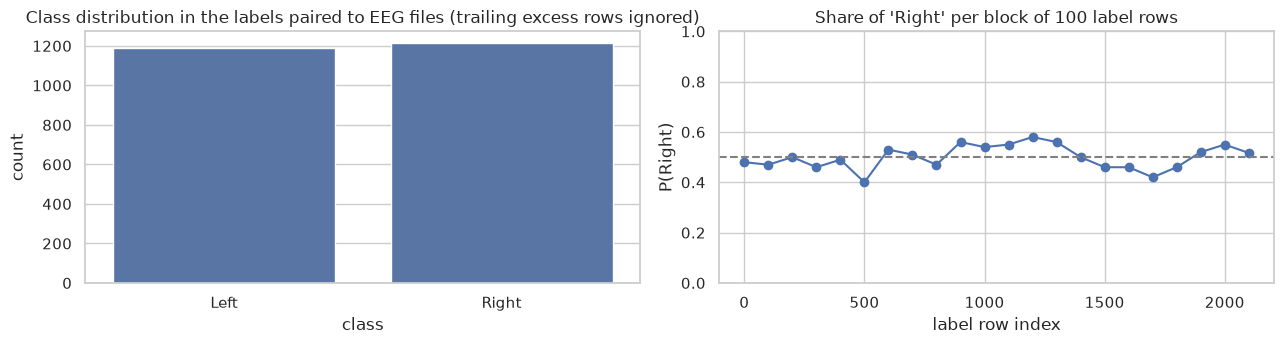

In [9]:
def runs_test(binary):
    """Wald–Wolfowitz runs test for randomness of a 0/1 sequence → (n_runs, z, p)."""
    s = np.asarray(binary, int)
    n1, n0 = int(s.sum()), int((1 - s).sum()); n = n1 + n0
    runs = 1 + int((np.diff(s) != 0).sum())
    mu = 2 * n1 * n0 / n + 1
    var = 2 * n1 * n0 * (2 * n1 * n0 - n) / (n ** 2 * (n - 1))
    z = (runs - mu) / math.sqrt(var)
    return runs, z, 2 * (1 - stats.norm.cdf(abs(z)))

if labels_used_df is not None and labels_used_df.label.isin(VALID_LABELS).all():
    y_seq = (labels_used_df.label == "Right").astype(int).to_numpy()
    runs, z, p = runs_test(y_seq)
    longest = max((len(list(g)) for _, g in __import__("itertools").groupby(y_seq)), default=0)
    print(f"Label sequence: {runs} runs, longest run = {longest}; runs-test z = {z:+.2f} (p = {p:.3g})")
    print("  → " + ("sequence looks random-order (no block structure detected)" if p > 0.01
          else "NON-random ordering (blocks/alternation) — relevant for split design and for any positional alignment argument"))

    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    sns.countplot(x=labels_df.label.astype(str), order=["Left", "Right"], ax=ax[0])
    ax[0].set(title="Class distribution in the labels paired to EEG files (trailing excess rows ignored)", xlabel="class")
    w = 100
    share = pd.Series(y_seq).groupby(np.arange(len(y_seq)) // w).mean()
    ax[1].plot(share.index * w, share.values, marker="o")
    ax[1].axhline(y_seq.mean(), ls="--", c="gray")
    ax[1].set(title=f"Share of 'Right' per block of {w} label rows", xlabel="label row index", ylabel="P(Right)", ylim=(0, 1))
    show(fig, "03_label_audit")

### 3.1 Confirmed label-to-file ordering and excess rows

The user confirmed that **each EEG CSV corresponds to the label at the same numeric file position**.

1. Sort EEG files by ascending numeric `file_id` (not alphabetically).
2. Pair file IDs 1–2160 with rows 1–2160 of `labels.csv`.
3. Exclude rows 2161–2400 (240 extra labels) from the working dataset only.
4. Preserve the original `labels.csv` unchanged and save the used/excluded label rows separately.

This is the agreed dataset-order rule. The notebook validates that file IDs are exactly 1..N and that every paired label is `Left` or `Right`. The mapping is not inferred from signal similarity.


In [10]:
# Build a filename→label table using the user-confirmed numeric file order.
# Rule: file_id 1..N maps to labels.csv rows 1..N. Any trailing label rows are excluded.
mapping_df = None
expected_ids = np.arange(1, len(files_df) + 1, dtype=int)
ids_are_complete_and_ordered = np.array_equal(
    files_df["file_id"].to_numpy(dtype=int), expected_ids
)
mapping_report = dict(
    method="user_confirmed_numeric_file_order_first_N_labels",
    structurally_valid=False,
    n_files=len(files_df),
    n_source_labels=0 if labels_df is None else len(labels_df),
    n_labels_used=0 if labels_used_df is None else len(labels_used_df),
    n_trailing_labels_ignored=0 if labels_excess_df is None else len(labels_excess_df),
    file_ids_are_exactly_1_to_N=bool(ids_are_complete_and_ordered),
    source=CFG.MAPPING_SOURCE,
    problems=[]
)

if labels_used_df is None:
    mapping_report["problems"].append("labels.csv is missing or contains fewer rows than EEG files")
elif not ids_are_complete_and_ordered:
    mapping_report["problems"].append("EEG file IDs are not exactly 1..N in numeric order")
elif not LABEL_ORDER_INPUT_VALID:
    mapping_report["problems"].append("one or more paired labels are missing or not Left/Right")
elif len(labels_used_df) != len(files_df):
    mapping_report["problems"].append("paired label count does not equal EEG file count")
else:
    mapping_df = files_df[["file_id", "filename"]].reset_index(drop=True).copy()
    mapping_df["file_order_index"] = np.arange(len(mapping_df))
    mapping_df["label_row_1based"] = labels_used_df["label_row_1based"].to_numpy()
    mapping_df["label"] = labels_used_df["label"].astype(str).to_numpy()
    mapping_report["structurally_valid"] = bool(
        mapping_df.filename.is_unique
        and mapping_df.file_id.is_unique
        and len(mapping_df) == len(files_df)
        and mapping_df.label.isin(VALID_LABELS).all()
        and mapping_df.label_row_1based.is_unique
        and np.array_equal(mapping_df.file_id.to_numpy(), mapping_df.label_row_1based.to_numpy())
    )
    if not mapping_report["structurally_valid"]:
        mapping_report["problems"].append("generated ordered mapping failed one-to-one validation")

LABELS_VERIFIED = bool(mapping_report["structurally_valid"] and CFG.MAPPING_SOURCE)
if LABELS_VERIFIED:
    mapping_report["coverage"] = f"{mapping_df.filename.nunique()}/{len(files_df)} EEG files mapped"
    register("Label ↔ file mapping", mapping_report["coverage"], "CONFIRMED", CFG.MAPPING_SOURCE)
else:
    ISSUES.append("Label↔file mapping failed validation: " + "; ".join(mapping_report["problems"] or ["mapping source is empty"]))

print("Ordered mapping report:", json.dumps(mapping_report, indent=2, default=str))
print("LABELS_VERIFIED:", LABELS_VERIFIED)
if LABELS_VERIFIED:
    print("✓ First N labels mapped to files with IDs 1..N in ascending numeric order.")
    print(f"✓ Trailing excess labels excluded: {len(labels_excess_df)}")
else:
    print("→ Supervised outputs are blocked until the mapping assertions pass.")


Ordered mapping report: {
  "method": "user_confirmed_numeric_file_order_first_N_labels",
  "structurally_valid": true,
  "n_files": 2160,
  "n_source_labels": 2400,
  "n_labels_used": 2160,
  "n_trailing_labels_ignored": 240,
  "file_ids_are_exactly_1_to_N": true,
  "source": "User confirmed in chat (2026-11-15): labels.csv rows correspond to EEG files sorted by ascending numeric file ID; keep the first N rows for the N files and exclude trailing excess rows.",
  "problems": [],
  "coverage": "2160/2160 EEG files mapped"
}
LABELS_VERIFIED: True
✓ First N labels mapped to files with IDs 1..N in ascending numeric order.
✓ Trailing excess labels excluded: 240


---
## Section 4 — Comprehensive EDA

### 4.0 Single-pass file scan (cached)
Each CSV is read **once**. For every file the scan computes, in one pass:
* structure validation (columns, row count, missing / non-numeric / infinite cells);
* per-channel descriptive statistics and first/last samples (used later to test continuity between neighbouring files);
* **repeated-sample metrics** — consecutive *full-row* repeats (all 4 channels identical to the previous row), run lengths, partial (single-channel) flat runs, non-adjacent duplicate rows;
* **timestamp metrics** — duration, sampling-rate estimates, arrival-time jitter, zero/tiny intervals;
* robust discontinuity metrics;
* a **normalised-frequency** Welch PSD (cycles/sample — needs **no** sampling-rate assumption).

The raw signals are copied once into a disk-backed memory-map (`cache/raw_cache.npy`) so later stages do not re-parse CSVs and do not hold the dataset in RAM. This is a *copy*; the originals are untouched. The cache is keyed on the input fingerprint and rebuilt automatically if any input changes.

In [11]:
def _runs(b):
    """Lengths of consecutive True runs in a 1-D boolean array."""
    if b.size == 0 or not b.any():
        return np.zeros(0, dtype=int)
    d = np.diff(np.concatenate(([0], b.astype(np.int8), [0])))
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def scan_file(path: Path):
    """Read one CSV and return (record dict, payload | None). Never raises for data problems."""
    rec = dict(read_ok=False, structure_ok=False, error="")
    try:
        df = pd.read_csv(path)
    except Exception as exc:
        rec["error"] = f"{type(exc).__name__}: {exc}"
        return rec, None
    need = [CFG.TIME_COL] + CH
    miss = [c for c in need if c not in df.columns]
    rec.update(read_ok=True, rows=len(df), cols=df.shape[1],
               missing_columns=",".join(miss), extra_columns=",".join(c for c in df.columns if c not in need))
    if miss:
        return rec, None
    sub = df[need]
    num = sub.apply(pd.to_numeric, errors="coerce")
    arr = num.to_numpy(dtype=float)
    rec.update(missing_cells=int(sub.isna().sum().sum()),
               nonnumeric_cells=int((sub.notna() & num.isna()).sum().sum()),
               infinite_cells=int(np.isinf(arr).sum()), nonfinite_cells=int((~np.isfinite(arr)).sum()))
    if len(df) != CFG.EXPECTED_ROWS or rec["nonfinite_cells"] > 0:
        return rec, None
    rec["structure_ok"] = True
    t, x = arr[:, 0], arr[:, 1:]
    n = len(x)

    # ---- per-channel descriptive statistics ----
    for j, ch in enumerate(CH):
        v = x[:, j]; med = np.median(v)
        rec.update({f"{ch}_mean": v.mean(), f"{ch}_median": med, f"{ch}_std": v.std(ddof=1),
                    f"{ch}_min": v.min(), f"{ch}_max": v.max(), f"{ch}_p2p": np.ptp(v),
                    f"{ch}_mad": np.median(np.abs(v - med)), f"{ch}_nunique": len(np.unique(v)),
                    f"{ch}_first": v[0], f"{ch}_last": v[-1]})

    # ---- repeated samples ----
    eq_ch = x[1:] == x[:-1]                        # (n-1, 4) per-channel equality with previous row
    eq_all = eq_ch.all(axis=1)                     # full-row repeat
    runs = _runs(eq_all)
    dup_members = int(pd.DataFrame(x).duplicated(keep=False).sum())   # all members of any duplicated row group
    partial = eq_ch & ~eq_all[:, None]             # a channel repeats while the others change
    rec.update(rep_n=int(eq_all.sum()), rep_frac=float(eq_all.mean()), rep_runs=int(len(runs)),
               rep_longest=int(runs.max()) if len(runs) else 0, rep_mean_run=float(runs.mean()) if len(runs) else 0.0,
               dup_members=dup_members,
               nonadj_dup_members=dup_members - int(eq_all.sum()) - int(len(runs)),   # >0 ⇒ equal rows that are NOT adjacent
               partial_flat_run_max=int(max((_runs(partial[:, j]).max() if partial[:, j].any() else 0) for j in range(4))),
               partial_repeat_frac=float(partial.any(axis=1).mean()))

    # ---- robust discontinuity metrics on non-repeated first differences ----
    d = np.diff(x, axis=0)[~eq_all]
    if len(d) > 20:
        zs = []
        for j in range(4):
            med = np.median(d[:, j]); s = 1.4826 * np.median(np.abs(d[:, j] - med))
            s = s if s > 0 else (d[:, j].std() or 1.0)
            zs.append(np.abs(d[:, j] - med) / s)
            rec[f"{CH[j]}_step"] = float(np.median(np.abs(d[:, j])))
        zs = np.stack(zs, axis=1)
        rec["jump_frac"] = float((zs > 8).mean()); rec["jump_max_z"] = float(zs.max())

    # ---- timestamps (assumed seconds; checked via plausible duration) ----
    dt = np.diff(t); dur = float(t[-1] - t[0])
    slope, icpt = np.polyfit(np.arange(n), t, 1)
    resid = t - (slope * np.arange(n) + icpt)
    rec.update(t_first=float(t[0]), t_last=float(t[-1]), duration_s=dur,
               rate_nd=(n - 1) / dur if dur > 0 else np.nan, rate_reg=1 / slope if slope > 0 else np.nan,
               t_resid_max_s=float(np.abs(resid).max()), t_resid_std_s=float(resid.std()),
               dt_neg=int((dt < 0).sum()), dt_zero=int((dt == 0).sum()),
               dt_lt1ms_frac=float((dt < 1e-3).mean()), dt_max_s=float(dt.max()))

    # ---- normalised-frequency PSD (cycles/sample): no sampling-rate assumption ----
    _, P = signal.welch(x, fs=1.0, window="hann", nperseg=CFG.NPERSEG, noverlap=CFG.NPERSEG // 2, detrend="linear", axis=0)
    return rec, dict(x=x, t=t, psd=P.T, runs=runs)

def scan_all(files_df, force=False):
    n, R = len(files_df), CFG.EXPECTED_ROWS
    cache = DIRS["cache"]
    key = hashlib.sha256(f"{n}|{FP_HASH}|{R}|{CFG.NPERSEG}|v1".encode()).hexdigest()
    names = ["qc_scan.csv", "psd_norm.npy", "raw_cache.npy", "time_cache.npy", "run_hist.npy"]
    kp = cache / "scan_key.json"
    if not force and kp.exists() and json.loads(kp.read_text())["key"] == key and all((cache / f).exists() for f in names):
        print("Loaded scan cache (inputs unchanged).")
    else:
        RAWm = np.lib.format.open_memmap(cache / "raw_cache.npy", mode="w+", dtype=np.float64, shape=(n, R, 4))
        TIMEm = np.lib.format.open_memmap(cache / "time_cache.npy", mode="w+", dtype=np.float64, shape=(n, R))
        PSDa = np.zeros((n, 4, CFG.NPERSEG // 2 + 1)); hist = np.zeros(201, dtype=np.int64); recs = []
        for i, p in enumerate(tqdm(files_df.path, desc="Scanning EEG files")):
            rec, pay = scan_file(Path(p)); rec["row_index"] = i; recs.append(rec)
            if pay is not None:
                RAWm[i] = pay["x"]; TIMEm[i] = pay["t"]; PSDa[i] = pay["psd"]
                np.add.at(hist, np.minimum(pay["runs"], 200), 1)
        RAWm.flush(); TIMEm.flush(); del RAWm, TIMEm
        np.save(cache / "psd_norm.npy", PSDa); np.save(cache / "run_hist.npy", hist)
        q = pd.DataFrame(recs); q.insert(0, "file_id", files_df.file_id.values); q.insert(1, "filename", files_df.filename.values)
        q.to_csv(cache / "qc_scan.csv", index=False)
        kp.write_text(json.dumps({"key": key}))
    q = pd.read_csv(cache / "qc_scan.csv")
    for c in ("missing_columns", "extra_columns", "error"):
        if c in q: q[c] = q[c].fillna("")
    q["structure_ok"] = q["structure_ok"].astype(bool)
    return (q, np.load(cache / "raw_cache.npy", mmap_mode="r"), np.load(cache / "time_cache.npy", mmap_mode="r"),
            np.load(cache / "psd_norm.npy"), np.load(cache / "run_hist.npy"))

qc, RAW, TIME, PSD_NORM, RUN_HIST = scan_all(files_df, force=CFG.FORCE_RESCAN)
F_NORM = np.arange(CFG.NPERSEG // 2 + 1) / CFG.NPERSEG        # cycles / sample
N_OK = int(qc.structure_ok.sum())
print(f"\nStructure-valid recordings: {N_OK}/{len(qc)}   |   read errors: {int((~qc.read_ok).sum())}")
bad = qc[~qc.structure_ok]
if len(bad):
    display(bad[["file_id", "filename", "rows", "cols", "missing_columns", "nonfinite_cells", "error"]].head(20))
    ISSUES.append(f"{len(bad)} recordings fail structure validation (excluded, logged)")
register("Samples per recording", CFG.EXPECTED_ROWS, "CONFIRMED" if (qc.rows == CFG.EXPECTED_ROWS).all() else "INFERRED",
         f"{int((qc.rows == CFG.EXPECTED_ROWS).sum())}/{len(qc)} files have exactly {CFG.EXPECTED_ROWS} rows")

Scanning EEG files:   0%|          | 0/2160 [00:00<?, ?it/s]


Structure-valid recordings: 2160/2160   |   read errors: 0


/tmp/ipykernel_192617/464695552.py:105: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  if c in q: q[c] = q[c].fillna("")


### 4.1 Signal statistics (per channel, across recordings)
Mean, median, standard deviation, minimum and maximum are computed **per recording and channel**, then summarised across recordings. Absolute values carry **unknown units** and a large DC offset, so they are descriptive only; amplitude comparisons between recordings use robust, log-scaled quantities.

In [12]:
ok = qc[qc.structure_ok].copy()
rows = []
for ch in CH:
    for st in ["mean", "median", "std", "min", "max", "p2p"]:
        v = ok[f"{ch}_{st}"]
        rows.append(dict(channel=ch, statistic=st, median_over_files=v.median(), q25=v.quantile(.25), q75=v.quantile(.75),
                         min_over_files=v.min(), max_over_files=v.max()))
summary_stats = pd.DataFrame(rows)
display(summary_stats.pivot(index="statistic", columns="channel", values="median_over_files")[CH].round(2)
        .rename_axis("median across recordings"))
display(summary_stats.round(2))
dc_range = {ch: (ok[f"{ch}_mean"].min(), ok[f"{ch}_mean"].max()) for ch in CH}
print("Per-file DC level ranges (min, max):", {k: (round(a), round(b)) for k, (a, b) in dc_range.items()})
print("→ DC offsets are large relative to within-file std; raw DC level is NOT used as a feature (it would encode session/drift, not brain activity).")

channel,FZ,C3,CZ,C4
median across recordings,,,,
max,297310.50,304524.66,323497.08,314282.44
mean,296499.34,302166.31,320670.05,312669.46
median,296435.66,302177.54,320647.79,312628.81
min,295586.95,301629.47,318571.83,309818.70
p2p,1568.68,1730.12,3231.58,2779.84
std,419.19,503.47,920.15,806.09


,channel,statistic,median_over_files,q25,q75,min_over_files,max_over_files
0,FZ,mean,296499.34,284512.69,311525.42,229802.87,439496.36
1,FZ,median,296435.66,284507.97,311525.56,229848.59,439426.91
2,FZ,std,419.19,230.56,1457.24,26.90,12043.98
3,FZ,min,295586.95,282125.09,310365.07,225946.38,420346.12
4,FZ,max,297310.50,284978.24,312569.80,232948.11,456689.25
5,FZ,p2p,1568.68,823.48,4611.64,137.25,41466.88
6,C3,mean,302166.31,284025.25,317175.57,229664.52,372623.05
7,C3,median,302177.54,283996.43,317193.55,229558.41,373380.06
8,C3,std,503.47,188.80,1318.76,15.60,22813.11
9,C3,min,301629.47,283383.96,315523.15,222394.41,359209.00


Per-file DC level ranges (min, max): {'FZ': (229803, 439496), 'C3': (229665, 372623), 'CZ': (272370, 694949), 'C4': (205977, 685171)}
→ DC offsets are large relative to within-file std; raw DC level is NOT used as a feature (it would encode session/drift, not brain activity).


### 4.2 Raw signal visualisation (FZ, C3, CZ, C4)
Three recordings are chosen **automatically by their metrics** (not hand-picked): the cleanest recording near the median amplitude, a recording with a moderate repeat fraction, and the recording with the highest repeat fraction. Each is shown over the full 2500 samples and in a 2-second zoom.
**What to look for:** held (flat) segments, step discontinuities, dominant regular oscillations, drift, and whether channels move together.

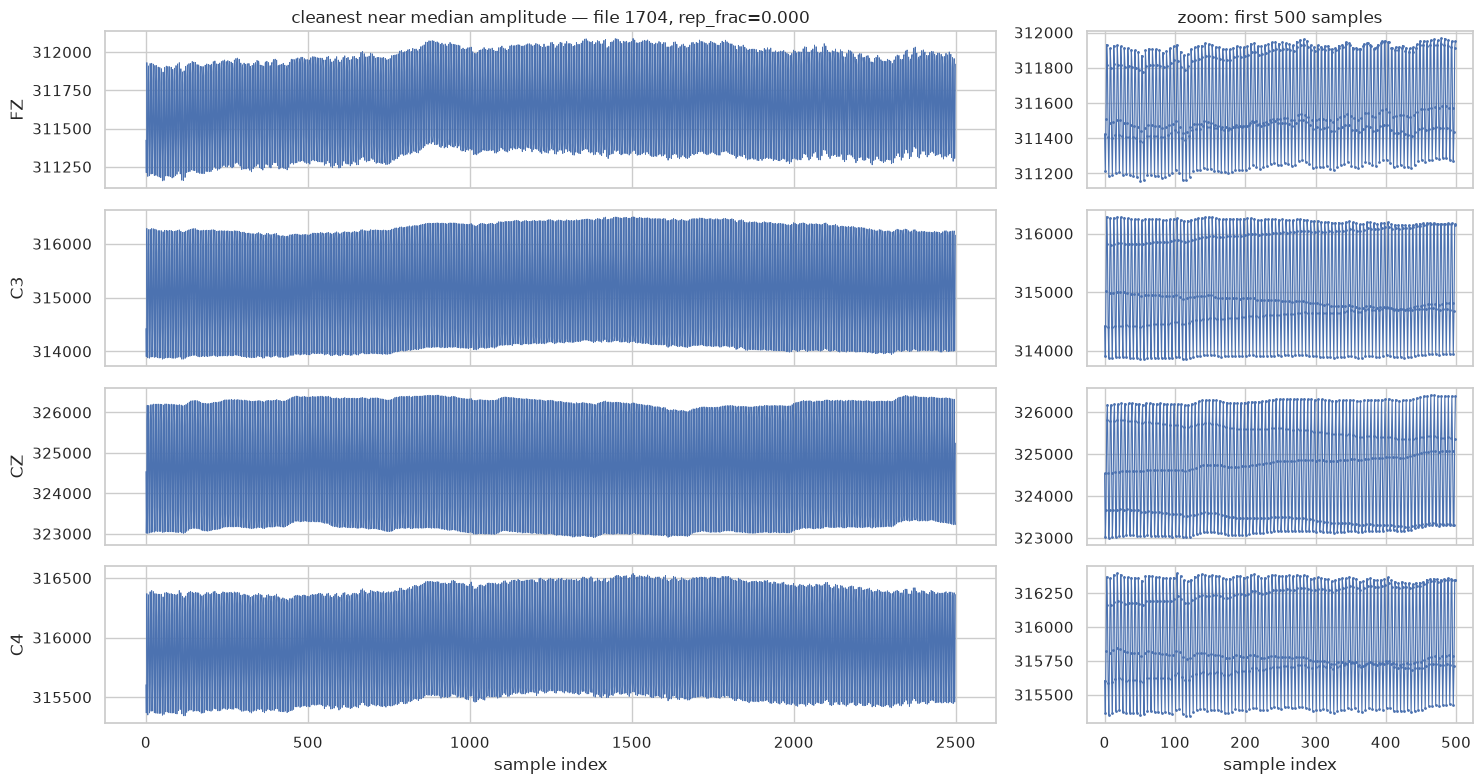

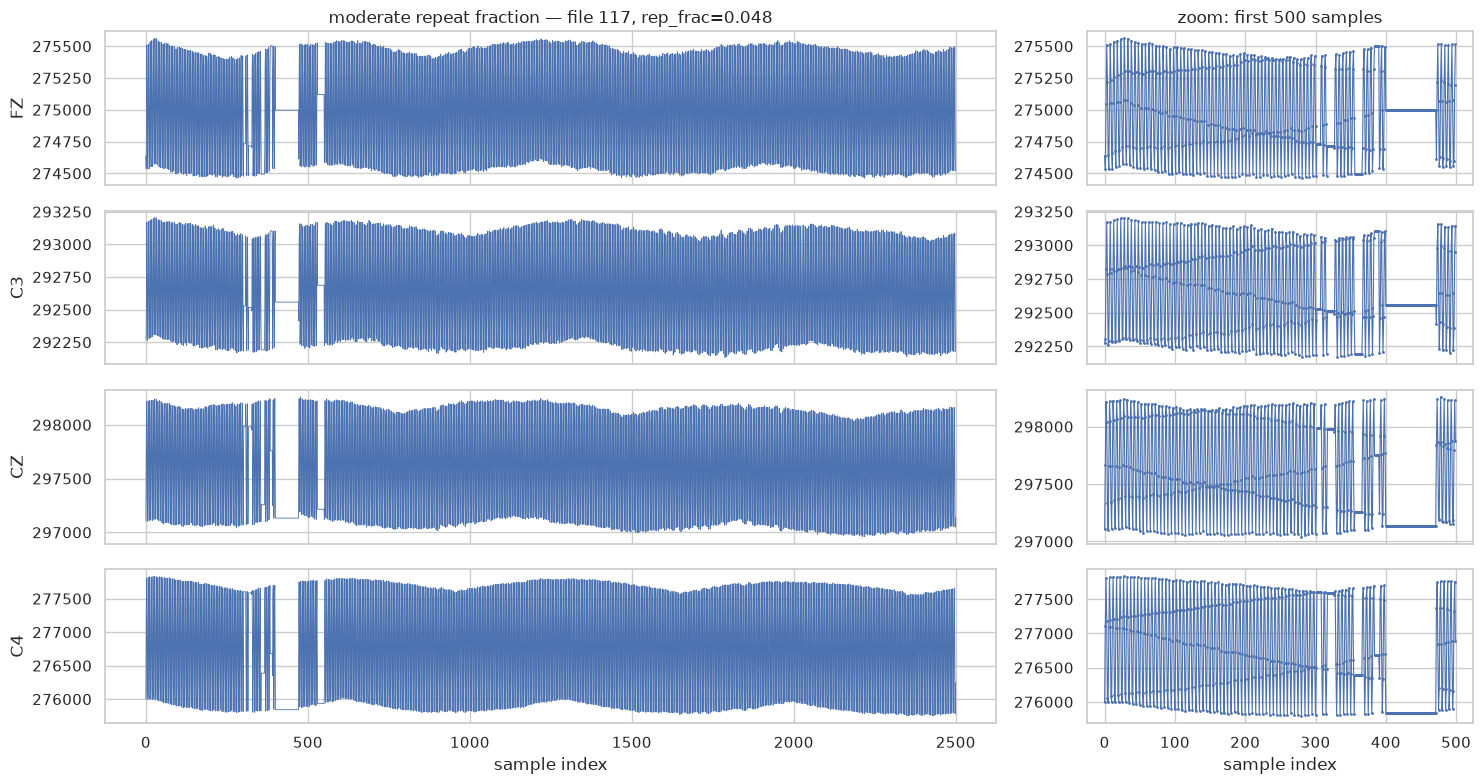

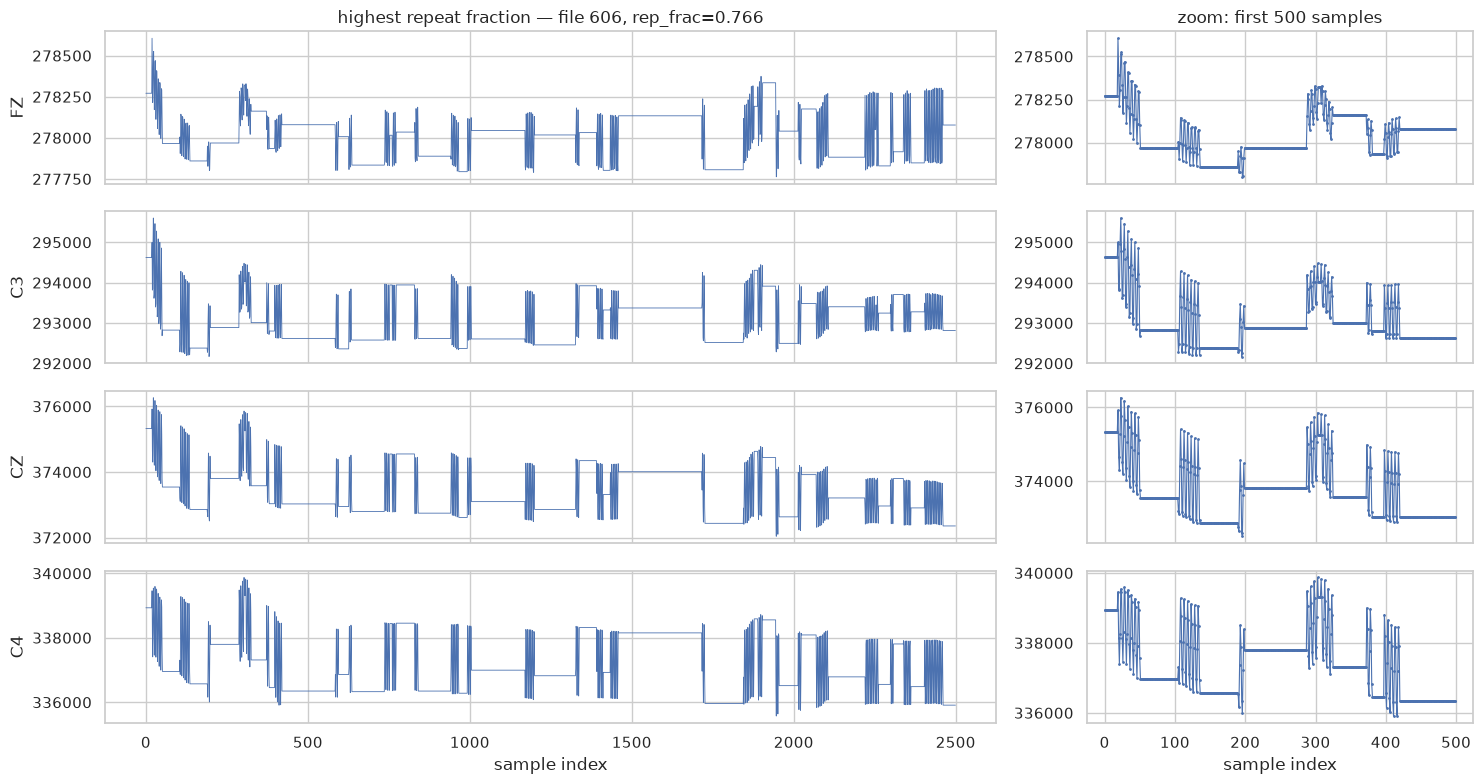

In [13]:
def pick_examples(ok):
    med_std = ok[[f"{c}_std" for c in CH]].median(axis=1).median()
    clean = ok[ok.rep_n == 0].copy()
    clean["d"] = (clean[[f"{c}_std" for c in CH]].median(axis=1) - med_std).abs()
    ex = {"cleanest near median amplitude": int(clean.sort_values("d").iloc[0].row_index)} if len(clean) else {}
    rep = ok[ok.rep_frac > 0].sort_values("rep_frac")
    if len(rep):
        ex["moderate repeat fraction"] = int(rep.iloc[len(rep) // 2].row_index)
        ex["highest repeat fraction"] = int(rep.iloc[-1].row_index)
    return ex

def plot_recording(i, title, zoom=500):
    x = np.asarray(RAW[i]); fid = int(qc.loc[i, "file_id"])
    fig, axes = plt.subplots(4, 2, figsize=(15, 8), sharex="col", gridspec_kw={"width_ratios": [3, 1.3]})
    for j, ch in enumerate(CH):
        axes[j, 0].plot(x[:, j], lw=0.6); axes[j, 0].set_ylabel(ch)
        axes[j, 1].plot(np.arange(zoom), x[:zoom, j], lw=0.8, marker=".", ms=2)
    axes[0, 0].set_title(f"{title} — file {fid}, rep_frac={qc.loc[i, 'rep_frac']:.3f}")
    axes[0, 1].set_title(f"zoom: first {zoom} samples"); axes[-1, 0].set_xlabel("sample index"); axes[-1, 1].set_xlabel("sample index")
    show(fig, f"04_raw_{fid}")

EXAMPLES = pick_examples(ok)
for label, i in EXAMPLES.items():
    plot_recording(i, label)

### 4.3 Amplitude distribution and outlier analysis
* **Pooled amplitude distribution:** DC-removed samples from a random subset of recordings, per channel (log-count axis so heavy tails remain visible).
* **Per-recording spread:** `log10(std)` per channel. Population outliers are identified with the **modified z-score** (median/MAD based, robust to the outliers themselves); the conventional cut-off is 3.5. Because any cut-off is a convention, counts at several cut-offs are tabulated (sensitivity analysis).

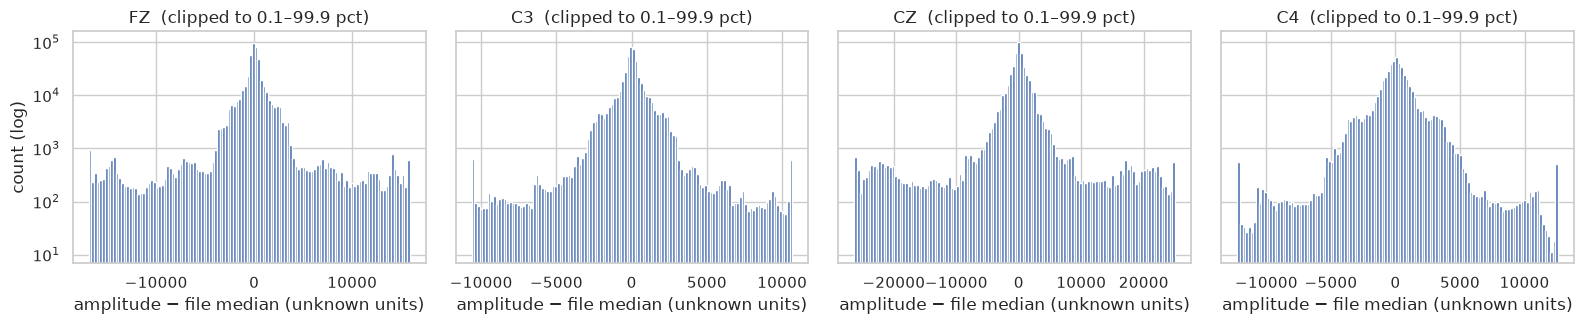

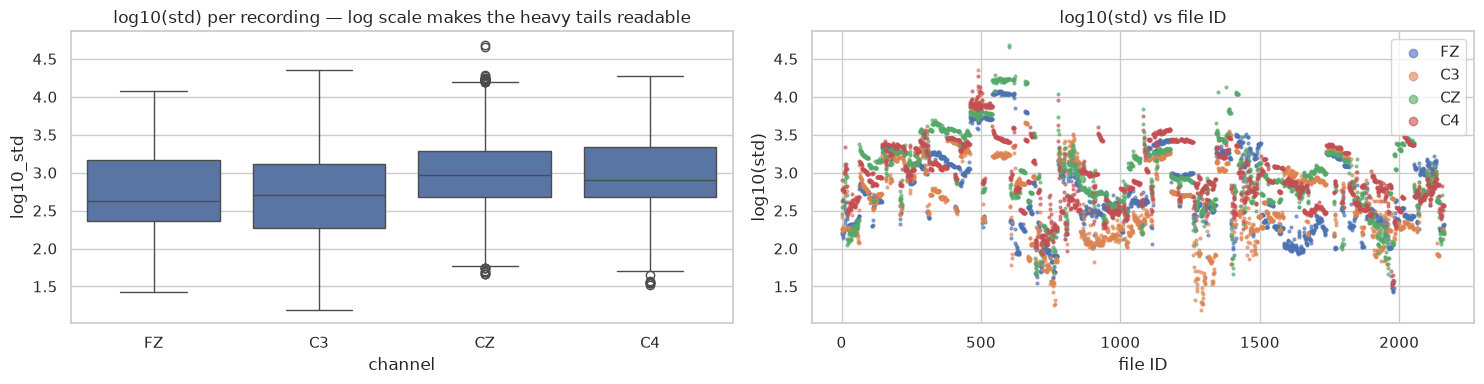

,modz>3.0,modz>3.5,modz>5.0,modz>8.0
files flagged by channel (two-sided),,,,
FZ,0,0,0,0
C3,0,0,0,0
CZ,2,2,0,0
C4,0,0,0,0


Recordings with ≥1 channel above modz 3.5: 2


In [14]:
def mod_z(v):
    """Modified z-score (Iglewicz & Hoaglin). NaN when MAD is zero (cannot be estimated)."""
    v = np.asarray(v, float); med = np.nanmedian(v); mad = np.nanmedian(np.abs(v - med))
    return np.full_like(v, np.nan) if (not np.isfinite(mad) or mad == 0) else 0.6745 * (v - med) / mad

for ch in CH:
    qc[f"log10_std_{ch}"] = np.log10(qc[f"{ch}_std"])
    qc[f"amp_modz_{ch}"] = np.nan
    qc.loc[qc.structure_ok, f"amp_modz_{ch}"] = mod_z(qc.loc[qc.structure_ok, f"log10_std_{ch}"])
qc["amp_modz_max"] = qc[[f"amp_modz_{c}" for c in CH]].abs().max(axis=1).fillna(0.0)

# --- pooled amplitude distribution (DC removed) from a random subset ---
sub = seeded(1).choice(qc.index[qc.structure_ok], size=min(200, N_OK), replace=False)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for j, ch in enumerate(CH):
    v = np.concatenate([np.asarray(RAW[i][:, j]) - np.median(RAW[i][:, j]) for i in sub])
    lo, hi = np.percentile(v, [0.1, 99.9])
    axes[j].hist(np.clip(v, lo, hi), bins=120); axes[j].set_yscale("log"); axes[j].set_title(f"{ch}  (clipped to 0.1–99.9 pct)")
    axes[j].set_xlabel("amplitude − file median (unknown units)")
axes[0].set_ylabel("count (log)")
show(fig, "04_amplitude_distribution")

# --- per-recording spread & outliers ---
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
long = qc[qc.structure_ok].melt(id_vars="file_id", value_vars=[f"log10_std_{c}" for c in CH], var_name="channel", value_name="log10_std")
long["channel"] = long.channel.str.replace("log10_std_", "")
sns.boxplot(data=long, x="channel", y="log10_std", order=CH, ax=ax[0]); ax[0].set_title("log10(std) per recording — log scale makes the heavy tails readable")
for ch in CH:
    ax[1].scatter(qc.file_id, qc[f"log10_std_{ch}"], s=4, label=ch, alpha=.6)
ax[1].set(title="log10(std) vs file ID", xlabel="file ID", ylabel="log10(std)"); ax[1].legend(markerscale=3)
show(fig, "04_std_distribution")

sens = pd.DataFrame({f"modz>{t}": [(qc[f"amp_modz_{c}"].abs() > t).sum() for c in CH] for t in (3.0, 3.5, 5.0, 8.0)}, index=CH)
display(sens.rename_axis("files flagged by channel (two-sided)"))
print(f"Recordings with ≥1 channel above modz {CFG.AMP_MODZ}: {(qc.amp_modz_max > CFG.AMP_MODZ).sum()}")

### 4.4 Signal behaviour across file IDs
File IDs may reflect acquisition order. Plotting per-recording summaries against ID reveals **slow drifts, abrupt level changes (possible session/recording boundaries) and clusters of problematic files** — structure that matters for both quality control and the split design in §11.
The "level-jump" statistic below normalises the change in DC level between consecutive IDs by the within-file spread, so a large value means "the signal level changed by many standard deviations between neighbouring files".

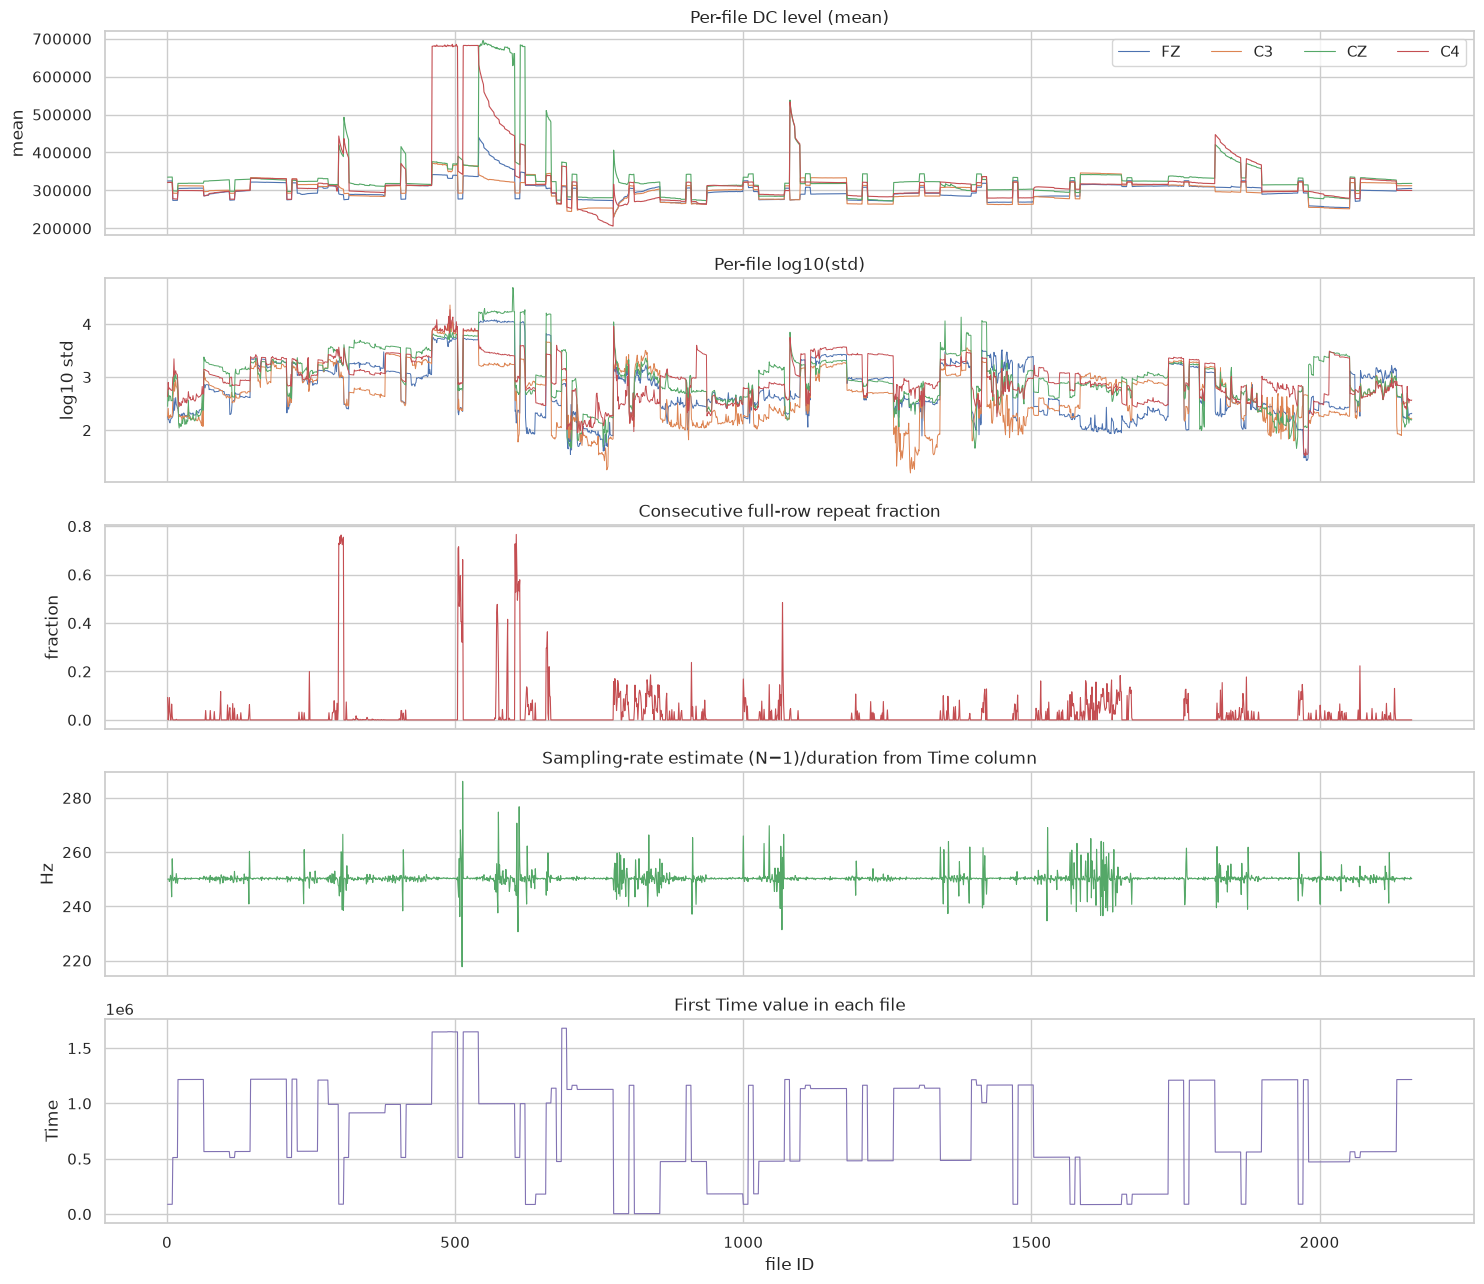

Distribution of level jumps between consecutive IDs (in within-file std units):


,level_jump
count,2159.00
mean,4.71
std,28.99
min,0.01
50%,0.26
90%,2.57
99%,135.60
max,567.78


{'>3': 173, '>5': 103, '>8': 93, '>12': 85}


,file_id,level_jump_next
701,702,567.8
1475,1476,451.1
1970,1971,403.7
1466,1467,393.4
1961,1962,316.0
935,936,288.1
8,9,287.4
710,711,250.8


In [15]:
fig, axes = plt.subplots(5, 1, figsize=(15, 13), sharex=True)
for ch in CH:
    axes[0].plot(qc.file_id, qc[f"{ch}_mean"], lw=0.8, label=ch)
axes[0].set(title="Per-file DC level (mean)", ylabel="mean"); axes[0].legend(ncol=4)
for ch in CH:
    axes[1].plot(qc.file_id, qc[f"log10_std_{ch}"], lw=0.7, label=ch)
axes[1].set(title="Per-file log10(std)", ylabel="log10 std")
axes[2].plot(qc.file_id, qc.rep_frac, lw=0.8, c="C3"); axes[2].set(title="Consecutive full-row repeat fraction", ylabel="fraction")
axes[3].plot(qc.file_id, qc.rate_nd, lw=0.8, c="C2"); axes[3].set(title="Sampling-rate estimate (N−1)/duration from Time column", ylabel="Hz")
axes[4].plot(qc.file_id, qc.t_first, lw=0.8, c="C4"); axes[4].set(title="First Time value in each file", ylabel="Time", xlabel="file ID")
show(fig, "04_behaviour_across_ids")

# ---- level jumps between consecutive IDs ----
mean = qc[[f"{c}_mean" for c in CH]].to_numpy(); std = qc[[f"{c}_std" for c in CH]].to_numpy()
adjacent = (np.diff(qc.file_id.to_numpy()) == 1) & qc.structure_ok.to_numpy()[:-1] & qc.structure_ok.to_numpy()[1:]
u = (np.abs(np.diff(mean, axis=0)) / np.sqrt(0.5 * (std[:-1] ** 2 + std[1:] ** 2))).max(axis=1)
u[~adjacent] = np.nan
qc["level_jump_next"] = np.append(u, np.nan)            # jump between this file and the next ID
print("Distribution of level jumps between consecutive IDs (in within-file std units):")
display(pd.Series(u).describe(percentiles=[.5, .9, .99]).round(2).to_frame("level_jump"))
print({f">{t}": int(np.nansum(u > t)) for t in (3, 5, 8, 12)})
display(qc.loc[qc.level_jump_next.sort_values(ascending=False).head(8).index, ["file_id", "level_jump_next"]].round(1))

### 4.5 Comparison between channels
Within-file correlation of the (linearly detrended) channels, summarised as the median over recordings, shows whether channels share strong common-mode activity. Correlation of per-recording `log10(std)` across channels shows whether amplitude changes affect all channels together (e.g. gain/impedance/recording-wide problems) or individual channels.

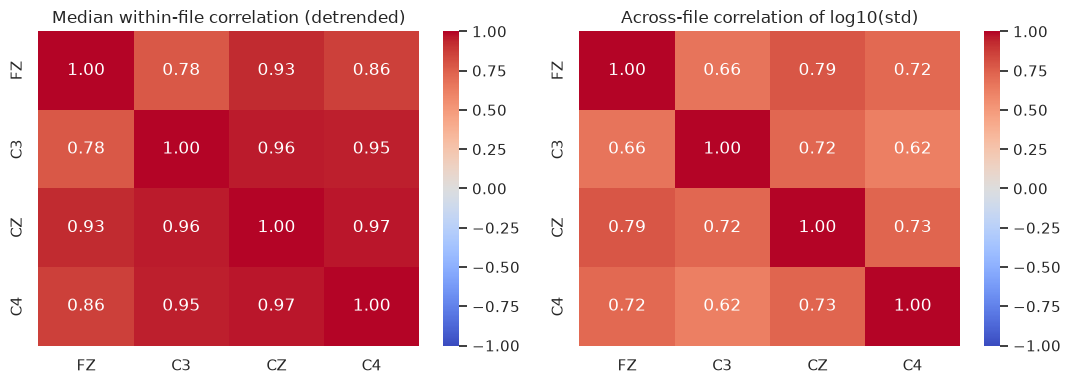

In [16]:
sub = seeded(2).choice(qc.index[qc.structure_ok], size=min(300, N_OK), replace=False)
C = np.stack([np.corrcoef(signal.detrend(np.asarray(RAW[i]), axis=0).T) for i in sub])
Cmed = pd.DataFrame(np.nanmedian(C, axis=0), index=CH, columns=CH)
Cstd = pd.DataFrame(qc.loc[qc.structure_ok, [f"log10_std_{c}" for c in CH]].corr().to_numpy(), index=CH, columns=CH)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(Cmed, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax[0]); ax[0].set_title("Median within-file correlation (detrended)")
sns.heatmap(Cstd, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax[1]); ax[1].set_title("Across-file correlation of log10(std)")
show(fig, "04_channel_comparison")

### 4.6 Class distribution (only after labels are verified)
Class balance **of the EEG files** can only be reported if a verified mapping exists. The label-file distribution in §3 describes `labels.csv`, not the files.

In [17]:
if LABELS_VERIFIED:
    lab = mapping_df.set_index("filename")["label"]
    cls = files_df.filename.map(lab)
    display(cls.value_counts(dropna=False).to_frame("EEG files"))
else:
    print("SKIPPED: labels are not verified, so no class distribution of the EEG files is reported.")

,EEG files
filename,
Left,1082
Right,1078


---
## Section 5 — Signal quality assessment

### 5.1 Sampling-rate estimation and uncertainty
The `Time` column holds **arrival-style timestamps**: intervals are very non-uniform (bursts of near-zero intervals followed by gaps), so the *median* interval is meaningless as a rate estimator. The robust long-run estimators are
* `rate_nd = (N−1) / (t_last − t_first)` per file, and
* `rate_reg = 1 / slope` of a straight-line fit of time vs sample index.

The population of per-file estimates is summarised (median, IQR, bootstrap CI). Jitter of the timestamps around the fitted line bounds the per-file error.

**Decision rule (explicit, not hidden):**
1. If you supplied `FS_CONFIRMED_HZ` **and** a source → status **CONFIRMED**.
2. Else, if `ALLOW_INFERRED_FS` and the population median is within 1 % of a standard nominal rate and ≥ 90 % of files lie within 2 % of it → that nominal rate becomes the **working** sampling rate with status **INFERRED**. Every downstream artefact records this status, and a sensitivity analysis (§7.4) shows how much a 2 % error would matter.
3. Otherwise no sampling rate is assumed: only normalised-frequency analyses are performed and preprocessing is skipped.

,value
median rate_nd (Hz),250.273105
IQR,250.02 – 250.51
95% bootstrap CI of median,250.265 – 250.296
nearest nominal (Hz),250
median deviation from nominal,0.11 %
files within ±1 %,90.2 %
files within ±2 %,93.6 %
median |rate_nd − rate_reg|,0.280335
median duration (s),9.985092
median max timestamp jitter (ms),58.290227


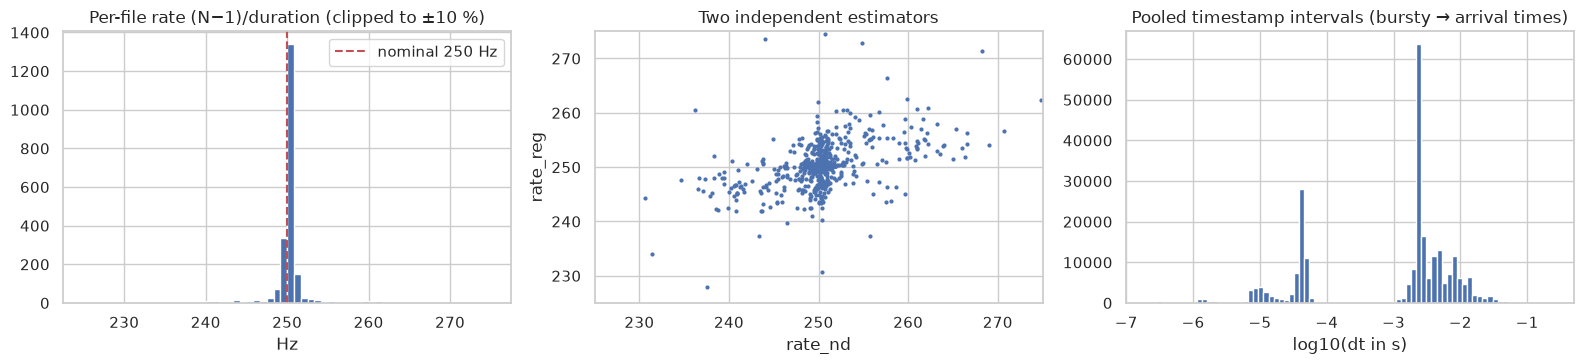


WORKING SAMPLING RATE: 250.0 Hz   status = INFERRED
evidence: median (N−1)/duration = 250.27 Hz (95% CI 250.27–250.30); 93.6% of files within ±2% of 250 Hz; 2500 rows ≈ 9.99 s


,item,value,status,evidence
0,Channel order,"FZ, C3, CZ, C4",CONFIRMED,column names in every file are validated in th...
1,What one CSV represents (trial / continuous),None,UNKNOWN,no event markers or cue timing supplied
2,Subject / session IDs,None,UNKNOWN,none supplied; none invented
3,Signal units / reference,None,UNKNOWN,none supplied
4,Label ↔ file mapping,2160/2160 EEG files mapped,CONFIRMED,User confirmed in chat (2026-11-15): labels.cs...
5,Samples per recording,2500,CONFIRMED,2160/2160 files have exactly 2500 rows
6,Sampling frequency,250.0,INFERRED,median (N−1)/duration = 250.27 Hz (95% CI 250....


Files whose own rate deviates > 2% from the population median: 141


In [18]:
NOMINAL_RATES = [100, 125, 128, 200, 250, 256, 500, 512, 1000]
okd = qc[qc.structure_ok & (qc.duration_s > 0)]
r_nd, r_reg = okd.rate_nd.to_numpy(), okd.rate_reg.to_numpy()
fs_med = float(np.median(r_nd)); q25, q75 = np.percentile(r_nd, [25, 75])
boot = np.median(seeded(3).choice(r_nd, size=(2000, len(r_nd)), replace=True), axis=1)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
nominal = min(NOMINAL_RATES, key=lambda r: abs(math.log(fs_med / r)))
dev = abs(fs_med - nominal) / nominal
within1 = float((np.abs(r_nd - nominal) / nominal <= 0.01).mean()); within2 = float((np.abs(r_nd - nominal) / nominal <= 0.02).mean())

sr_table = pd.DataFrame({
    "median rate_nd (Hz)": [fs_med], "IQR": [f"{q25:.2f} – {q75:.2f}"], "95% bootstrap CI of median": [f"{ci_lo:.3f} – {ci_hi:.3f}"],
    "nearest nominal (Hz)": [nominal], "median deviation from nominal": [f"{100*dev:.2f} %"],
    "files within ±1 %": [f"{100*within1:.1f} %"], "files within ±2 %": [f"{100*within2:.1f} %"],
    "median |rate_nd − rate_reg|": [float(np.median(np.abs(r_nd - r_reg)))],
    "median duration (s)": [float(okd.duration_s.median())],
    "median max timestamp jitter (ms)": [1e3 * float(okd.t_resid_max_s.median())],
    "median share of intervals < 1 ms": [float(okd.dt_lt1ms_frac.median())]}).T.rename(columns={0: "value"})
display(sr_table)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
lo_, hi_ = nominal * 0.9, nominal * 1.1
ax[0].hist(np.clip(r_nd, lo_, hi_), bins=60); ax[0].axvline(nominal, c="r", ls="--", label=f"nominal {nominal} Hz"); ax[0].legend()
ax[0].set(title="Per-file rate (N−1)/duration (clipped to ±10 %)", xlabel="Hz")
ax[1].scatter(r_nd, r_reg, s=4); ax[1].set(title="Two independent estimators", xlabel="rate_nd", ylabel="rate_reg", xlim=(lo_, hi_), ylim=(lo_, hi_))
pooled_dt = np.concatenate([np.diff(np.asarray(TIME[i])) for i in seeded(4).choice(okd.row_index.to_numpy(), size=min(100, len(okd)), replace=False)])
ax[2].hist(np.log10(pooled_dt[pooled_dt > 0]), bins=80); ax[2].set(title="Pooled timestamp intervals (bursty → arrival times)", xlabel="log10(dt in s)")
show(fig, "05_sampling_rate")

# ---- apply the decision rule ----
FS_WORK, FS_STATUS, FS_EVIDENCE = None, "UNKNOWN", "not determined"
if CFG.FS_CONFIRMED_HZ is not None and CFG.FS_CONFIRMED_SOURCE:
    FS_WORK, FS_STATUS, FS_EVIDENCE = float(CFG.FS_CONFIRMED_HZ), "CONFIRMED", f"source: {CFG.FS_CONFIRMED_SOURCE}"
elif CFG.FS_CONFIRMED_HZ is not None:
    print("FS_CONFIRMED_HZ was given without FS_CONFIRMED_SOURCE → ignored (cannot be called confirmed).")
if FS_WORK is None and CFG.ALLOW_INFERRED_FS and dev <= 0.01 and within2 >= 0.90:
    FS_WORK, FS_STATUS = float(nominal), "INFERRED"
    FS_EVIDENCE = (f"median (N−1)/duration = {fs_med:.2f} Hz (95% CI {ci_lo:.2f}–{ci_hi:.2f}); {100*within2:.1f}% of files within ±2% of {nominal} Hz; "
                   f"{CFG.EXPECTED_ROWS} rows ≈ {okd.duration_s.median():.2f} s")
register("Sampling frequency", FS_WORK, FS_STATUS, FS_EVIDENCE)
if FS_STATUS != "CONFIRMED":
    ISSUES.append(f"Sampling frequency is {FS_STATUS} ({FS_WORK} Hz). Ask the dataset owner to confirm.")
PIPELINE_OK = FS_WORK is not None
print(f"\nWORKING SAMPLING RATE: {FS_WORK} Hz   status = {FS_STATUS}\nevidence: {FS_EVIDENCE}")
if not PIPELINE_OK:
    print("→ No sampling rate can be justified: preprocessing/feature sections will be SKIPPED (normalised-frequency analysis continues).")
show_registry()

# per-file rate outliers (timestamp anomalies relative to the population)
qc["rate_dev_rel"] = (qc.rate_nd - fs_med).abs() / fs_med
print("Files whose own rate deviates >", f"{100*CFG.RATE_DEV_TOL:.0f}% from the population median:", int((qc.rate_dev_rel > CFG.RATE_DEV_TOL).sum()))

### 5.2 Repeated samples — what they are and where they occur
A **full-row repeat** means all four channels equal the previous row to the stored precision. For continuous-valued multichannel EEG this is essentially impossible physiologically, so *at the sample level* a repeated row is treated as an **acquisition artefact** (e.g. hold/duplicate fill after dropped packets). At the **recording level**, whether a file is still usable depends on how much of it is affected — that is quantified in §5.3, not assumed.

Reported here: how common repeats are, run-length distribution, whether equal rows also occur non-adjacently, and how repeated rows relate to timestamp behaviour.

,files with rep_frac > t,% of valid
> 0,461,21.34
> 0.001,448,20.74
> 0.005,423,19.58
> 0.01,413,19.12
> 0.02,389,18.01
> 0.05,229,10.60
> 0.1,124,5.74
> 0.2,40,1.85
> 0.5,22,1.02


Primary policy: repeated samples are reported and flagged only. No recording or source file is excluded, removed, or deleted because it contains duplicate/repeated samples. The repeated rows remain in the signal; downstream users can decide whether to handle them.
Files with non-adjacent duplicate rows (equal rows that are not consecutive): 0
Longest repeated run in any file: 306 transitions  (1.22 s at the working rate)


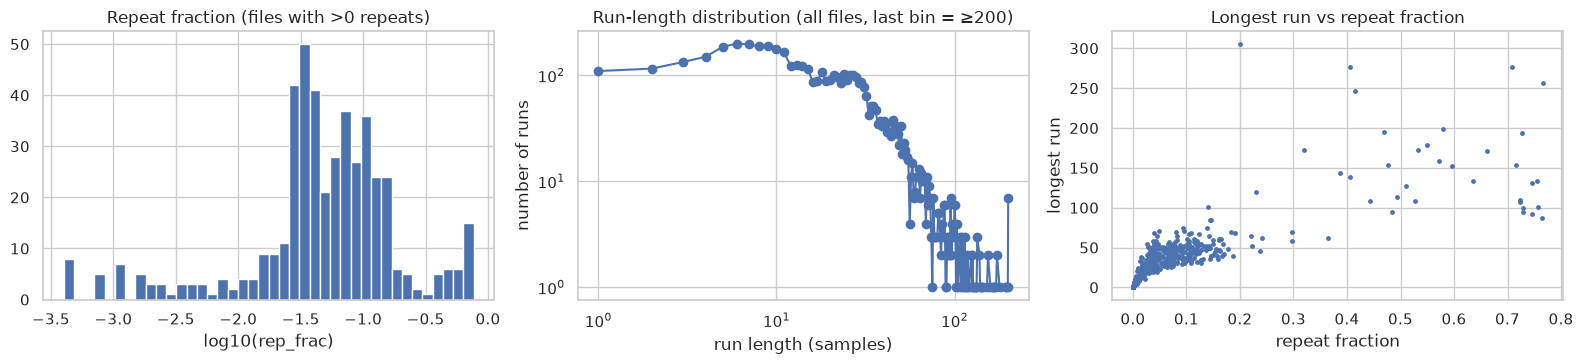

,repeated transitions,non-repeated transitions
count,49983.0000,449817.0000
share dt < 1 ms,0.9856,0.3181
share dt > 10 ms,0.0032,0.0788
median dt (ms),0.0013,2.4454


Read: a clear difference between columns indicates repeats are tied to the timestamp/packet structure (acquisition-side cause).


In [19]:
ths = [0, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
tab = pd.DataFrame({"files with rep_frac > t": [int((qc.rep_frac > t).sum()) for t in ths]}, index=[f"> {t:g}" for t in ths])
tab["% of valid"] = (100 * tab.iloc[:, 0] / N_OK).round(2)
display(tab)
print("Primary policy: repeated samples are reported and flagged only. No recording or source file is excluded, removed, or deleted because it contains duplicate/repeated samples. The repeated rows remain in the signal; downstream users can decide whether to handle them.")
print(f"Files with non-adjacent duplicate rows (equal rows that are not consecutive): {(qc.nonadj_dup_members > 0).sum()}")
print(f"Longest repeated run in any file: {int(qc.rep_longest.max())} transitions  ({qc.rep_longest.max() / FS_WORK:.2f} s at the working rate)" if FS_WORK else
      f"Longest repeated run in any file: {int(qc.rep_longest.max())} transitions")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
rp = qc.rep_frac[qc.rep_frac > 0]
ax[0].hist(np.log10(rp), bins=40) if len(rp) else None; ax[0].set(title="Repeat fraction (files with >0 repeats)", xlabel="log10(rep_frac)")
nz = RUN_HIST[1:] > 0
ax[1].loglog(np.arange(1, 201)[nz], RUN_HIST[1:][nz], "o-"); ax[1].set(title="Run-length distribution (all files, last bin = ≥200)", xlabel="run length (samples)", ylabel="number of runs")
ax[2].scatter(qc.rep_frac, qc.rep_longest, s=6); ax[2].set(title="Longest run vs repeat fraction", xlabel="repeat fraction", ylabel="longest run")
show(fig, "05_repeats")

# --- do repeated rows coincide with specific timestamp behaviour? (≤200 affected files) ---
aff = qc.index[qc.structure_ok & (qc.rep_n > 0)].to_numpy()
if len(aff):
    aff = seeded(5).choice(aff, size=min(200, len(aff)), replace=False)
    dr, dn = [], []
    for i in aff:
        x, t = np.asarray(RAW[i]), np.asarray(TIME[i]); eq = (x[1:] == x[:-1]).all(axis=1); dt = np.diff(t)
        dr.append(dt[eq]); dn.append(dt[~eq])
    dr, dn = np.concatenate(dr), np.concatenate(dn)
    link = pd.DataFrame({"repeated transitions": [len(dr), (dr < 1e-3).mean(), (dr > 1e-2).mean(), 1e3 * np.median(dr)],
                         "non-repeated transitions": [len(dn), (dn < 1e-3).mean(), (dn > 1e-2).mean(), 1e3 * np.median(dn)]},
                        index=["count", "share dt < 1 ms", "share dt > 10 ms", "median dt (ms)"])
    display(link.round(4))
    print("Read: a clear difference between columns indicates repeats are tied to the timestamp/packet structure (acquisition-side cause).")

### 5.3 How much do repeats distort MI-relevant features? (dose–response sensitivity analysis)

Choosing a repeat-fraction threshold without evidence is arbitrary. This simulation:
1. selects recordings with no full-row repeats and no strong amplitude outlier;
2. injects repeated-sample hold runs using the empirical run-length distribution;
3. measures changes in theta/mu/beta band power after the same signal-processing pipeline;
4. reports the repeat fractions associated with several distortion tolerances.

The resulting threshold is a **quality-review flag**, not an automatic exclusion rule. By default, high-repeat recordings remain in the prepared dataset with their QC status recorded. This avoids discarding hundreds of recordings solely because of one heuristic threshold. The pipeline's primary policy is flag-only: repeated samples never exclude a recording. Keep this diagnostic threshold for downstream sensitivity analysis; any later filtering decision belongs to the next analyst and must be explicit.

The shared signal-processing functions used here and in §7–§8 are defined first, so there is exactly **one** pipeline.


,rep_frac,theta_median,mu_median,beta_median,worst_band_median,p90_all
0,0.002,0.5651,0.7576,2.1490,2.1490,5.1637
1,0.005,1.8414,2.0694,2.5913,2.5913,5.6019
2,0.010,2.5101,1.7942,2.8981,2.8981,6.6000
3,0.020,3.6285,3.2203,4.1178,4.1178,7.0587
4,0.050,4.0740,3.8474,4.5530,4.5530,7.5332
5,0.100,5.4440,4.9871,5.6195,5.6195,8.2420
6,0.200,5.9283,5.6620,6.1846,6.1846,8.8081
7,0.400,6.6906,6.5234,6.9877,6.9877,9.6205


,tolerance,exclusion_limit_rep_frac,real_files_above_limit
0,0.05,0.002,436
1,0.10,0.002,436
2,0.20,0.002,436
3,0.30,0.002,436


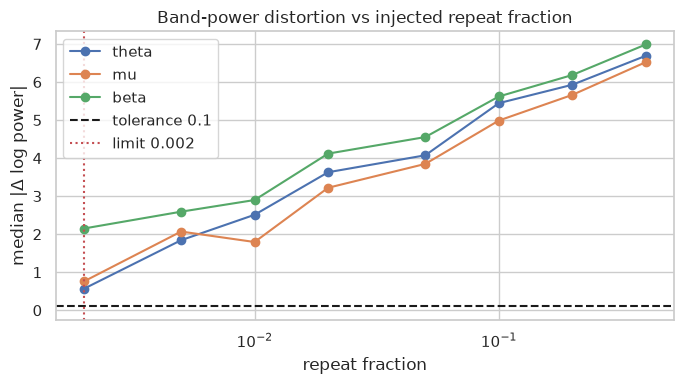

Simulation diagnostic limit (tolerance 0.1): 0.0020; the primary policy remains flag-only; this threshold is diagnostic only.
\nPRIMARY REPEAT POLICY: FLAG ONLY — no recording or source file is excluded because of repeated samples. Files with any full-row repeated transition: 461


In [20]:
# ======================= shared signal-processing functions (single pipeline) =======================
def welch_psd(x, fs, nperseg=None):
    nperseg = nperseg or CFG.NPERSEG
    return signal.welch(x, fs=fs, window="hann", nperseg=nperseg, noverlap=nperseg // 2, detrend=False, axis=0)

def band_power(f, P, lo, hi):
    """Integrated PSD in [lo, hi) Hz — absolute power in (signal units)²."""
    m = (f >= lo) & (f < hi)
    return trapezoid(P[m], f[m], axis=0)

def preprocess_recording(x, fs, notch_hz=None):
    """DC/linear-drift removal → optional notch → zero-phase Butterworth band-pass. Input/Output: (samples, channels)."""
    x = np.asarray(x, dtype=float)
    if x.ndim != 2 or x.shape[1] != len(CH):
        raise ValueError(f"expected (samples, {len(CH)}), got {x.shape}")
    if not np.isfinite(x).all():
        raise ValueError("non-finite values (no imputation is performed)")
    lo, hi = CFG.BANDPASS_HZ
    if not (0 < lo < hi < fs / 2):
        raise ValueError(f"band-pass {CFG.BANDPASS_HZ} incompatible with fs={fs}")
    y = signal.detrend(x, axis=0, type="linear")                     # removes the huge DC offset and slow drift
    if notch_hz is not None:
        if not (0 < notch_hz < fs / 2):
            raise ValueError("notch frequency must be below Nyquist")
        b, a = signal.iirnotch(notch_hz, CFG.NOTCH_Q, fs=fs)
        y = signal.filtfilt(b, a, y, axis=0)
    sos = signal.butter(CFG.FILTER_ORDER, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, y, axis=0)

def trim_edges(y, fs):
    k = int(round(CFG.EDGE_TRIM_S * fs))
    return y[k: len(y) - k] if k > 0 else y

def log_band_powers(x, fs, notch_hz=None):
    """(n_bands, n_channels) log absolute band power of the preprocessed, trimmed recording."""
    y = trim_edges(preprocess_recording(x, fs, notch_hz), fs)
    f, P = welch_psd(y, fs)
    return np.log(np.stack([band_power(f, P, *CFG.BANDS[b]) for b in CFG.BANDS]))

def inject_holds(x, frac, pool, rng):
    """Copy sample s-1 over the next L rows (all channels) until ≈frac of transitions are repeats."""
    y = x.copy(); n = len(y); target = int(round(frac * (n - 1))); done = 0; mask = np.zeros(n, bool); guard = 0
    while done < target and guard < 20000:
        guard += 1
        L = min(int(rng.choice(pool)), target - done); s = int(rng.integers(1, n - L))
        if mask[s:s + L].any():
            continue
        y[s:s + L] = y[s - 1]; mask[s:s + L] = True; done += L
    return y, done / (n - 1)

REPEAT_EXCLUDE_FRAC = None
if PIPELINE_OK:
    pool = np.repeat(np.arange(len(RUN_HIST)), np.where(np.arange(len(RUN_HIST)) == 0, 0, RUN_HIST)).clip(1, 200)
    pool = pool if len(pool) else np.array([1, 2, 5, 10, 20, 40])
    base = qc[qc.structure_ok & (qc.rep_n == 0) & (qc.amp_modz_max <= CFG.AMP_MODZ)].row_index.to_numpy()
    base = seeded(6).choice(base, size=min(CFG.SIM_FILES, len(base)), replace=False) if len(base) else base
    if len(base) < 5:
        print("Too few clean recordings for the simulation → no repeat-based exclusion limit can be derived.")
    else:
        rng = seeded(7); orig = {i: log_band_powers(RAW[i], FS_WORK) for i in base}
        rows = []
        for frac in CFG.SIM_FRACTIONS:
            dist = []
            for i in base:
                ysim, realised = inject_holds(np.asarray(RAW[i]), frac, pool, rng)
                dist.append(np.abs(log_band_powers(ysim, FS_WORK) - orig[i]))          # (bands, channels)
            dist = np.stack(dist)                                                       # (files, bands, channels)
            rows.append(dict(rep_frac=frac, **{f"{b}_median": float(np.median(dist[:, k])) for k, b in enumerate(CFG.BANDS)},
                             worst_band_median=float(max(np.median(dist[:, k]) for k in range(len(CFG.BANDS)))),
                             p90_all=float(np.percentile(dist, 90))))
        dose = pd.DataFrame(rows); display(dose.round(4))

        def limit_for(tol):
            fr, d = dose.rep_frac.to_numpy(), dose.worst_band_median.to_numpy()
            if d[0] > tol: return float(fr[0])
            for k in range(1, len(fr)):
                if d[k] > tol:                                                          # log-linear interpolation
                    w = (tol - d[k - 1]) / (d[k] - d[k - 1]); return float(np.exp(np.log(fr[k - 1]) + w * (np.log(fr[k]) - np.log(fr[k - 1]))))
            return float(fr[-1])
        sens = pd.DataFrame([dict(tolerance=t, exclusion_limit_rep_frac=limit_for(t),
                                  real_files_above_limit=int((qc.rep_frac > limit_for(t)).sum())) for t in CFG.SIM_TOLERANCES])
        display(sens.round(4))
        REPEAT_EXCLUDE_FRAC = limit_for(CFG.REPEAT_TOLERANCE)
        fig, ax = plt.subplots(figsize=(7, 4))
        for b in CFG.BANDS: ax.plot(dose.rep_frac, dose[f"{b}_median"], marker="o", label=b)
        ax.axhline(CFG.REPEAT_TOLERANCE, c="k", ls="--", label=f"tolerance {CFG.REPEAT_TOLERANCE}"); ax.axvline(REPEAT_EXCLUDE_FRAC, c="r", ls=":", label=f"limit {REPEAT_EXCLUDE_FRAC:.3f}")
        ax.set(xscale="log", title="Band-power distortion vs injected repeat fraction", xlabel="repeat fraction", ylabel="median |Δ log power|"); ax.legend()
        show(fig, "05_repeat_dose_response")
        print(f"Simulation diagnostic limit (tolerance {CFG.REPEAT_TOLERANCE}): {REPEAT_EXCLUDE_FRAC:.4f}; the primary policy remains flag-only; this threshold is diagnostic only.")
else:
    print("SKIPPED: requires a working sampling rate.")

# FINAL PRIMARY-DATASET POLICY:
# Repeated samples are diagnostic metadata only. They are never a reason to
# exclude a recording, remove rows, or delete/modify any original data file.
# Keep the simulated threshold as a sensitivity-analysis result, not an exclusion cutoff.
REPEAT_EXCLUDE_FRAC = None
CFG.EXCLUDE_HIGH_REPEAT = False
print(
    "\\nPRIMARY REPEAT POLICY: FLAG ONLY — no recording or source file is excluded "
    "because of repeated samples. "
    f"Files with any full-row repeated transition: {int((qc.rep_frac > 0).sum())}"
)


### 5.4 Other quality indicators and their sensitivity
| Indicator | Definition | Threshold basis |
|---|---|---|
| Amplitude outlier | modified z of `log10(std)` per channel, two-sided (very low std ⇒ near-flat) | 3.5 (literature convention) — counts tabulated at 3 / 3.5 / 5 / 8 in §4.3 |
| Partial flat-line | a channel stays *exactly* constant for ≥ `FLAT_RUN_MIN` samples while the other channels change | heuristic — sensitivity below |
| Discontinuities | share of non-repeated first-differences with robust z > 8; flagged by modified z of `log10(share)` across files | population-relative |
| Timestamp rate deviation | per-file rate differs > 2 % from the population median | explicit tolerance |
| Timestamp order | any negative interval | exact |

In [21]:
sens_flat = pd.DataFrame({"min run (samples)": [10, 25, 50, 100]})
sens_flat["files flagged"] = [int((qc.partial_flat_run_max >= r).sum()) for r in sens_flat["min run (samples)"]]
display(sens_flat)
qc["jump_modz"] = np.nan
m_ = qc.structure_ok & qc.jump_frac.notna()
qc.loc[m_, "jump_modz"] = mod_z(np.log10(qc.loc[m_, "jump_frac"] + 1e-4))
print("jump_modz computable:", qc.jump_modz.notna().sum(), "of", N_OK, "(NaN ⇒ MAD = 0 ⇒ flag not evaluated)")
display(pd.DataFrame({"files": [int((qc.jump_modz > t).sum()) for t in (3.0, 3.5, 5.0)]}, index=["jump_modz>3", ">3.5", ">5"]))
display(pd.DataFrame({"files": [int((qc.rate_dev_rel > t).sum()) for t in (0.01, 0.02, 0.05, 0.10)]}, index=["rate dev >1%", ">2%", ">5%", ">10%"]))

,min run (samples),files flagged
0,10,0
1,25,0
2,50,0
3,100,0


jump_modz computable: 0 of 2160 (NaN ⇒ MAD = 0 ⇒ flag not evaluated)


,files
jump_modz>3,0
>3.5,0
>5,0


,files
rate dev >1%,207
>2%,141
>5%,28
>10%,3


### 5.5 Quality report and categories
Every recording receives **flags** and exactly one category:

| Category | Rule | Fate |
|---|---|---|
| `EXCLUDED` | structural invalidity (columns/rows/non-finite values) or preprocessing failure | not used; logged with reason |
| `RETAINED_FLAGGED` | any QC flag (including any amount of repeated samples, amplitude outlier, partial flat-line, discontinuities, rate deviation, order, artefact review) | kept; flags carried into metadata for downstream review |
| `CLEAN` | no flag | kept |

No label is consulted during QC. Nothing is deleted from disk. Repeated/duplicate samples never trigger file or recording exclusion. Split-boundary embargo removes recordings from the current train/validation/test splits only; it does not delete source files.


In [22]:
# Only structural invalidity excludes a recording at the QC stage.
# Repeated samples are always flags, never an exclusion criterion.
EXCLUDING_FLAGS = {"STRUCTURE_INVALID"}

def assign_quality(qc, extra_flags=None):
    ok_ = qc.structure_ok
    lim = REPEAT_EXCLUDE_FRAC
    above = (qc.rep_frac > lim) if lim is not None else pd.Series(False, index=qc.index)
    flag_masks = {
        "STRUCTURE_INVALID": ~ok_,
        "REPEATS_ABOVE_LIMIT": ok_ & above.fillna(False),
        "REPEATS_MINOR": ok_ & (qc.rep_frac > 0) & ~above.fillna(False),
        "AMPLITUDE_OUTLIER": ok_ & (qc.amp_modz_max > CFG.AMP_MODZ),
        "PARTIAL_FLATLINE": ok_ & (qc.partial_flat_run_max >= CFG.FLAT_RUN_MIN),
        "DISCONTINUITIES": ok_ & (qc.jump_modz > CFG.AMP_MODZ),
        "TIMESTAMP_RATE_DEVIATION": ok_ & (qc.rate_dev_rel > CFG.RATE_DEV_TOL),
        "TIMESTAMP_ORDER": ok_ & (qc.dt_neg > 0),
    }
    if extra_flags:
        flag_masks.update(extra_flags)
    flags = pd.DataFrame(flag_masks).fillna(False).astype(bool)
    flag_txt = flags.apply(lambda r: ";".join(flags.columns[r.to_numpy()]), axis=1)
    cat = np.where(flags[[c for c in flags.columns if c in EXCLUDING_FLAGS]].any(axis=1), "EXCLUDED",
                   np.where(flags.any(axis=1), "RETAINED_FLAGGED", "CLEAN"))
    return flags, flag_txt, cat

flags, flag_txt, cat = assign_quality(qc)
qc_report = qc[["file_id", "filename", "row_index", "structure_ok", "rep_frac", "rep_longest", "partial_flat_run_max",
                "amp_modz_max", "jump_frac", "rate_nd", "rate_dev_rel", "duration_s"]].copy()
qc_report["quality_flags"], qc_report["quality_category"] = flag_txt.values, cat
display(qc_report.quality_category.value_counts().to_frame("recordings"))
display(flags.sum().to_frame("recordings flagged").query("`recordings flagged` > 0"))

print("\nQuality comparison — median of key metrics by category (suspicious vs normal):")
cmp_cols = ["rep_frac", "rep_longest", "amp_modz_max", "jump_frac", "rate_dev_rel", "partial_flat_run_max"]
display(qc_report[qc_report.structure_ok].groupby("quality_category")[cmp_cols].median().round(4))
print("Repeated-sample policy: FLAG ONLY — duplicate/repeated samples never exclude recordings or delete source files.")
print(
    "Recordings above simulated repeat threshold:",
    int(qc_report["quality_flags"].str.contains("REPEATS_ABOVE_LIMIT", na=False).sum())
)
display(qc_report[qc_report.quality_flags.str.contains("REPEATS_ABOVE_LIMIT", na=False)].sort_values("rep_frac", ascending=False).head(15))

,recordings
quality_category,
CLEAN,1694
RETAINED_FLAGGED,466


,recordings flagged
REPEATS_MINOR,461
AMPLITUDE_OUTLIER,2
TIMESTAMP_RATE_DEVIATION,141



Quality comparison — median of key metrics by category (suspicious vs normal):


,rep_frac,rep_longest,amp_modz_max,jump_frac,rate_dev_rel,partial_flat_run_max
quality_category,,,,,,
CLEAN,0.0000,0.0,1.1296,0.0,0.0007,0.0
RETAINED_FLAGGED,0.0472,38.0,0.9884,0.0,0.0061,0.0


Repeated-sample policy: FLAG ONLY — duplicate/repeated samples never exclude recordings or delete source files.
Recordings above simulated repeat threshold: 0


,file_id,filename,row_index,structure_ok,rep_frac,rep_longest,partial_flat_run_max,amp_modz_max,jump_frac,rate_nd,rate_dev_rel,duration_s,quality_flags,quality_category


---
## Section 6 — Spectral analysis

### 6.1 Normalised-frequency PSD (no sampling-rate assumption)
`PSD_NORM` was computed in the scan with `fs = 1`, i.e. frequency in **cycles per sample** (Nyquist = 0.5). A secondary axis converts to Hz **only if** a working sampling rate exists, and is labelled with its status.
**What to look for:** the 1/f-like background, narrow lines (interference), broad bumps in the mu/beta region, and differences between channels or between clean and suspicious recordings.

recordings used for the 'reference' spectra → clean: 1694 | retained (clean+flagged): 2160


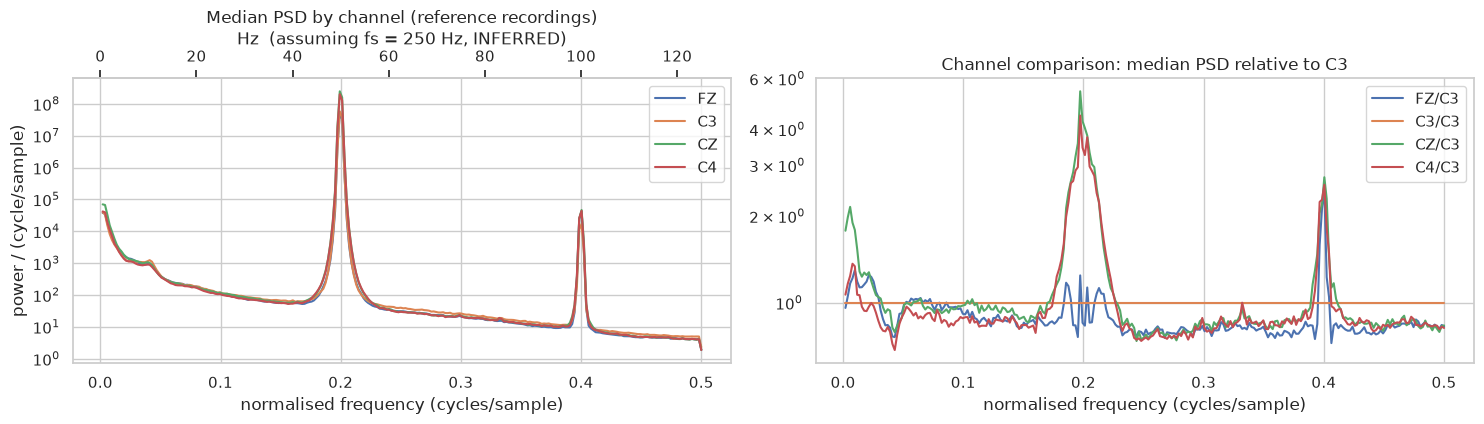

In [23]:
def hz_axis(ax, fs=FS_WORK):
    """Add a Hz axis on top (only meaningful if a working rate exists; label states its status)."""
    if fs is None:
        return
    sec = ax.secondary_xaxis("top", functions=(lambda f: f * fs, lambda h: h / fs))
    sec.set_xlabel(f"Hz  (assuming fs = {fs:g} Hz, {FS_STATUS})")

valid_rows = qc.index[qc.structure_ok].to_numpy()
cat_arr = qc_report.quality_category.to_numpy()
sel_clean = valid_rows[cat_arr[valid_rows] == "CLEAN"]
sel_ret = valid_rows[cat_arr[valid_rows] != "EXCLUDED"]
print("recordings used for the 'reference' spectra → clean:", len(sel_clean), "| retained (clean+flagged):", len(sel_ret))
ref = sel_clean if len(sel_clean) >= 10 else sel_ret

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for j, ch in enumerate(CH):
    ax[0].semilogy(F_NORM[1:], np.median(PSD_NORM[ref][:, j, 1:], axis=0), label=ch)
ax[0].set(title="Median PSD by channel (reference recordings)", xlabel="normalised frequency (cycles/sample)", ylabel="power / (cycle/sample)"); ax[0].legend(); hz_axis(ax[0])
ratio = np.median(PSD_NORM[ref], axis=0)
for j, ch in enumerate(CH):
    ax[1].semilogy(F_NORM[1:], ratio[j, 1:] / ratio[1, 1:], label=f"{ch}/C3")
ax[1].set(title="Channel comparison: median PSD relative to C3", xlabel="normalised frequency (cycles/sample)"); ax[1].legend()
show(fig, "06_psd_channels")

### 6.2 Clean vs suspicious recordings
Median PSD of each quality category (C3 and C4 shown; the same code runs for all channels). Differences in **broadband level, staircase-like spectral slope, or narrow lines** between categories indicate how the artefacts manifest spectrally.

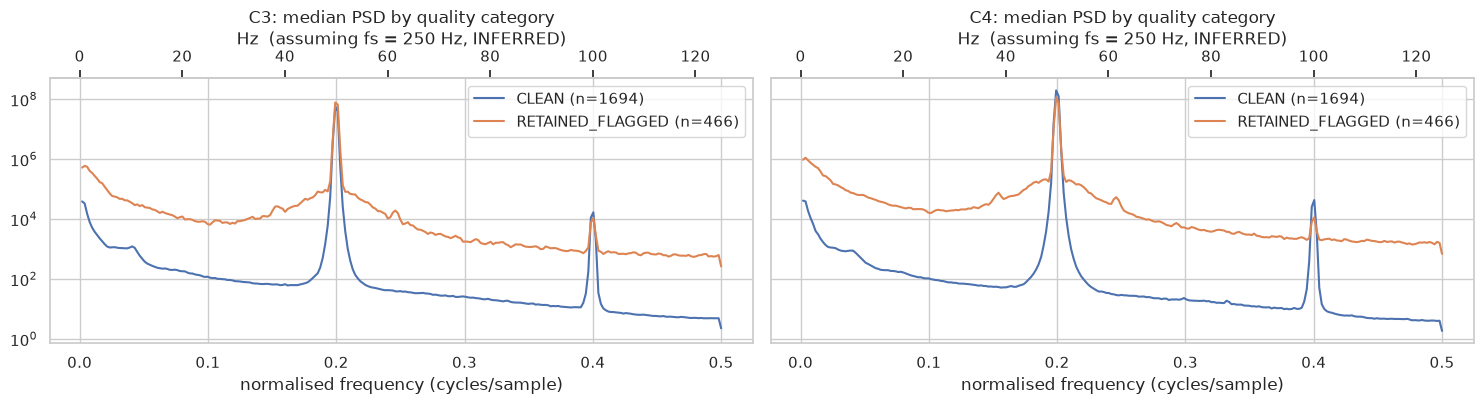

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for k, ch in enumerate(["C3", "C4"]):
    j = CH.index(ch)
    for name in ["CLEAN", "RETAINED_FLAGGED", "EXCLUDED"]:
        idx = valid_rows[cat_arr[valid_rows] == name]
        if len(idx):
            axes[k].semilogy(F_NORM[1:], np.median(PSD_NORM[idx][:, j, 1:], axis=0), label=f"{name} (n={len(idx)})")
    axes[k].set(title=f"{ch}: median PSD by quality category", xlabel="normalised frequency (cycles/sample)"); axes[k].legend(); hz_axis(axes[k])
show(fig, "06_psd_by_category")

### 6.3 Narrow-line detection and power-line interference investigation
For each recording and channel, a bin is a **narrow peak** if its power exceeds `PEAK_RATIO` × the median of its 17 neighbouring bins. The share of recordings with a narrow peak at each frequency is plotted.

**Power-line test.** Mains is 50 Hz or 60 Hz; in normalised frequency it sits at `mains / fs`. Because `fs` is not confirmed, several candidate rates are tested: for each (fs, mains) pair we report the share of retained recordings with a narrow peak at `mains/fs` (± 1 bin). This is a **consistency check**, not proof — different (fs, mains) pairs can coincide (e.g. 50 Hz @ 250 Hz = 60 Hz @ 300 Hz) — but a strong peak at the location predicted by the *working* fs is independent evidence for it. A **notch filter is applied only if the working-fs prediction is supported** by at least `NOTCH_SUPPORT_MIN` of retained recordings.

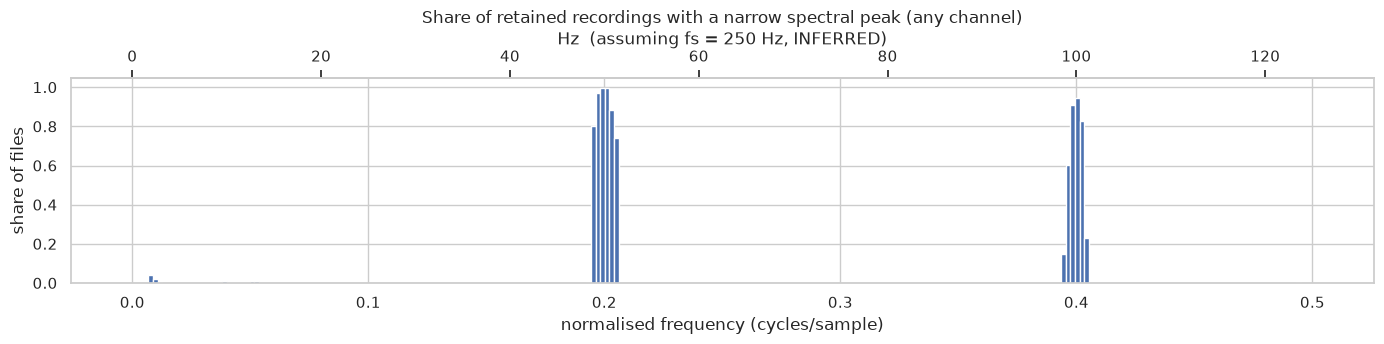

,normalised freq,share of files,Hz @ 250
0,0.1992,0.9954,49.8047
1,0.4004,0.9435,100.0977
2,0.2051,0.7407,51.2695
3,0.3945,0.1486,98.6328
4,0.0078,0.0412,1.9531
5,0.0508,0.0102,12.6953
6,0.0391,0.0083,9.7656
7,0.1934,0.0069,48.3398


,candidate_fs,mains_hz,norm_freq,share_with_peak
2,250,50,0.200,0.995
4,256,50,0.195,0.968
0,200,50,0.250,0.001
6,500,50,0.100,0.001
1,200,60,0.300,0.000
3,250,60,0.240,0.000
5,256,60,0.234,0.000
7,500,60,0.120,0.000



NOTCH DECISION: 50.0 — 100% of retained recordings show a narrow peak at 50 Hz (= 0.2 cycles/sample at fs=250)
Narrow peaks INSIDE the 4–30 Hz range (share>20%; may be genuine mu/alpha rhythm OR interference — the PSD alone cannot tell): none


In [25]:
R = np.ones_like(PSD_NORM)
R[valid_rows] = PSD_NORM[valid_rows] / ndimage.median_filter(PSD_NORM[valid_rows], size=(1, 1, 17), mode="nearest")
R[..., :4] = 0                                                  # ignore lowest bins (drift region)
PEAK = (R > CFG.PEAK_RATIO).any(axis=1)                         # (files, bins): peak in ANY channel
share_bin = PEAK[sel_ret].mean(axis=0) if len(sel_ret) else np.zeros(len(F_NORM))

fig, ax = plt.subplots(figsize=(14, 3.6))
ax.bar(F_NORM, share_bin, width=1 / CFG.NPERSEG); ax.set(title="Share of retained recordings with a narrow spectral peak (any channel)", xlabel="normalised frequency (cycles/sample)", ylabel="share of files"); hz_axis(ax)
show(fig, "06_narrow_peaks")

def top_peaks(share, k=8, min_sep=3):
    order = np.argsort(share)[::-1]; out = []
    for b in order:
        if share[b] <= 0: break
        if all(abs(b - o) >= min_sep for o in out): out.append(b)
        if len(out) == k: break
    return out
tp = top_peaks(share_bin)
peaks_tbl = pd.DataFrame({"normalised freq": F_NORM[tp], "share of files": share_bin[tp]})
if FS_WORK: peaks_tbl[f"Hz @ {FS_WORK:g}"] = F_NORM[tp] * FS_WORK
display(peaks_tbl.round(4))

cands = []
for fs_c in (200, 250, 256, 500):
    for mains in (50, 60):
        if mains < fs_c / 2:
            k = int(round(mains / fs_c * CFG.NPERSEG))
            cands.append(dict(candidate_fs=fs_c, mains_hz=mains, norm_freq=round(mains / fs_c, 4),
                              share_with_peak=float(PEAK[sel_ret][:, max(k - 1, 0):k + 2].any(axis=1).mean()) if len(sel_ret) else np.nan))
mains_tbl = pd.DataFrame(cands).sort_values("share_with_peak", ascending=False); display(mains_tbl.round(3))

NOTCH_HZ, NOTCH_EVIDENCE = None, "no notch (no sufficient spectral evidence)"
if CFG.NOTCH_HZ_OVERRIDE == "auto":
    if FS_WORK:
        best = mains_tbl[mains_tbl.candidate_fs == int(FS_WORK)] if int(FS_WORK) == FS_WORK else mains_tbl.iloc[0:0]
        best = best.sort_values("share_with_peak", ascending=False)
        if len(best) and best.iloc[0].share_with_peak >= CFG.NOTCH_SUPPORT_MIN:
            NOTCH_HZ = float(best.iloc[0].mains_hz)
            NOTCH_EVIDENCE = f"{100*best.iloc[0].share_with_peak:.0f}% of retained recordings show a narrow peak at {NOTCH_HZ:g} Hz (= {best.iloc[0].norm_freq} cycles/sample at fs={FS_WORK:g})"
else:
    NOTCH_HZ = CFG.NOTCH_HZ_OVERRIDE; NOTCH_EVIDENCE = "manual override in CFG"
print("\nNOTCH DECISION:", NOTCH_HZ, "—", NOTCH_EVIDENCE)

if FS_WORK:
    inband = [(F_NORM[b] * FS_WORK, share_bin[b]) for b in range(len(F_NORM)) if CFG.PEAK_BAND[0] <= F_NORM[b] * FS_WORK <= CFG.PEAK_BAND[1] and share_bin[b] > 0.2]
    print("Narrow peaks INSIDE the 4–30 Hz range (share>20%; may be genuine mu/alpha rhythm OR interference — the PSD alone cannot tell):", [(round(float(h), 1), round(float(s), 2)) for h, s in inband] or "none")
    if inband:
        ISSUES.append("Narrow spectral peaks inside 4–30 Hz in many recordings: may be genuine rhythms (mu/alpha) or interference — not removed automatically; inspect §6.3")

---
## Section 7 — EEG preprocessing (one pipeline, used everywhere)

### 7.1 What is applied and why
| Step | Applied? | Justification |
|---|---|---|
| Invalid values | **Exclude** the recording (logged) | none are expected; no imputation, because inventing samples in 4-channel EEG would distort spectra |
| Linear detrend (DC + drift) | **Yes** | raw DC offsets are ~10⁵ and drift between files; they are not neural and would dominate time-domain features |
| Notch | **Only if §6.3 provides evidence** | a notch at an unsupported frequency removes real signal; decision stored with its evidence |
| Band-pass 3–40 Hz, Butterworth order 4, zero-phase | **Yes** | MI information lives in μ (8–13 Hz) and β (13–30 Hz); θ (4–8 Hz) is kept for completeness. The 3 Hz lower edge keeps the 4 Hz θ edge on the flat part of the response; zero-phase (`sosfiltfilt`) avoids phase distortion between channels |
| Edge trimming (0.5 s) | **Yes (features only)** | removes filter edge effects |
| Event-related baseline correction | **No** | requires known cue/event timing — **UNKNOWN**; only whole-recording DC removal is justified |
| Artefact repair (ICA/interpolation/regression) | **No** | 4 channels, unknown reference, no EOG: ICA is not identifiable and interpolation would fabricate data |
| Artefact **detection** | **Yes, flag-only** | transient samples (|robust z| > `ARTIFACT_Z`) are counted; recordings with an unusually high share are flagged for review, not altered |
| Amplitude normalisation | **Not on the signal** (`PER_RECORDING_ZSCORE=False`) | units unknown; scale-free features (relative power, Hjorth mobility/complexity, asymmetry) are provided, and train-only robust scaling is applied to features in §11 |

In [26]:
EXCLUSIONS = []        # every exclusion, with stage and reason (never silent)
def log_exclusion(file_id, filename, stage, reason):
    EXCLUSIONS.append(dict(file_id=int(file_id), filename=filename, stage=stage, reason=reason))

for r in qc_report[qc_report.quality_category == "EXCLUDED"].itertuples():
    log_exclusion(r.file_id, r.filename, "QC", r.quality_flags)

def artifact_fraction(y, z=None):
    """Per-channel share of samples with robust |z| > z (flag-only metric)."""
    z = z or CFG.ARTIFACT_Z
    med = np.median(y, axis=0); mad = 1.4826 * np.median(np.abs(y - med), axis=0)
    mad = np.where(mad > 0, mad, np.nan)
    return np.nan_to_num((np.abs(y - med) / mad > z).mean(axis=0), nan=0.0)

XF = None; proc_rows = np.array([], dtype=int); prep_df = pd.DataFrame()
if PIPELINE_OK:
    todo = qc_report.index[qc_report.quality_category != "EXCLUDED"].to_numpy()
    out, ok_rows, recs = [], [], []
    for i in tqdm(todo, desc="Preprocessing"):
        try:
            y = trim_edges(preprocess_recording(RAW[i], FS_WORK, NOTCH_HZ), FS_WORK)
            af = artifact_fraction(y)
            out.append(y.astype(np.float32)); ok_rows.append(i)
            recs.append(dict(row_index=i, artifact_frac_max=float(af.max()), artifact_frac_mean=float(af.mean())))
        except Exception as exc:
            log_exclusion(qc.file_id[i], qc.filename[i], "PREPROCESS", f"{type(exc).__name__}: {exc}")
            recs.append(dict(row_index=i, artifact_frac_max=np.nan, artifact_frac_mean=np.nan, error=str(exc)))
    prep_df = pd.DataFrame(recs)
    failed = set(todo) - set(ok_rows)
    # --- artefact review flag (population-relative, flag-only) and preprocessing-failure exclusion ---
    EXCLUDING_FLAGS.add("PREPROCESS_ERROR")
    art = pd.Series(False, index=qc.index); pe = pd.Series(False, index=qc.index); pe.loc[list(failed)] = True
    good = prep_df.dropna(subset=["artifact_frac_max"])
    z_art = pd.Series(mod_z(np.log10(good.artifact_frac_max.to_numpy() + 1e-4)), index=good.row_index.to_numpy())
    art.loc[z_art.index[z_art > CFG.AMP_MODZ]] = True
    flags, flag_txt, cat = assign_quality(qc, {"ARTIFACT_REVIEW": art, "PREPROCESS_ERROR": pe})
    qc_report["quality_flags"], qc_report["quality_category"] = flag_txt.values, cat
    proc_rows = qc_report.index[qc_report.quality_category != "EXCLUDED"].to_numpy()
    assert set(proc_rows) == set(ok_rows), "processed set and non-excluded set must coincide"
    XF = np.stack([o for o, r in zip(out, ok_rows)]) if out else np.zeros((0, CFG.EXPECTED_ROWS, 4), np.float32)
    print(f"Preprocessed + edge-cropped {len(proc_rows)} recordings → XF{XF.shape} float32 | notch: {NOTCH_HZ} Hz | fs = {FS_WORK:g} Hz ({FS_STATUS})")
    display(qc_report.quality_category.value_counts().to_frame("recordings (final categories)"))
    if len(prep_df.dropna(subset=['artifact_frac_max'])):
        print("Artefact-sample share (max over channels): median =", f"{good.artifact_frac_max.median():.4f}", "| p99 =", f"{good.artifact_frac_max.quantile(.99):.4f}")
else:
    print("SKIPPED: no working sampling rate → no preprocessing.")

Preprocessing:   0%|          | 0/2160 [00:00<?, ?it/s]

Preprocessed + edge-cropped 2160 recordings → XF(2160, 2250, 4) float32 | notch: 50.0 Hz | fs = 250 Hz (INFERRED)


,recordings (final categories)
quality_category,
CLEAN,1694
RETAINED_FLAGGED,466


Artefact-sample share (max over channels): median = 0.0067 | p99 = 0.2625


### 7.2 Before / after (raw vs preprocessed)
Time course (first 4 s) and PSD in Hz (**assuming the working sampling rate**, status shown on the axis) for a clean and, if present, a flagged recording.

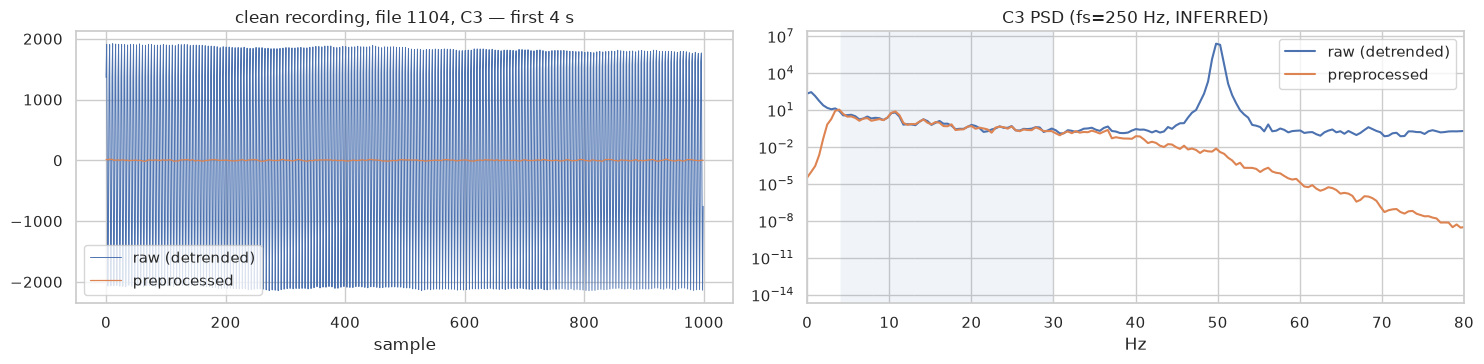

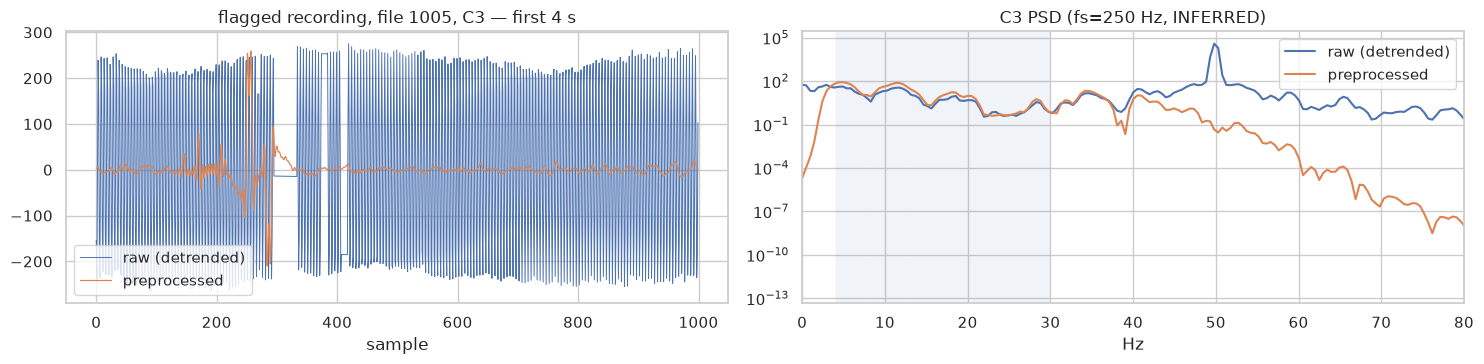

In [27]:
if PIPELINE_OK and len(proc_rows):
    ex_rows = []
    cl = [r for r in proc_rows if qc_report.quality_category[r] == "CLEAN"]
    fl = [r for r in proc_rows if qc_report.quality_category[r] == "RETAINED_FLAGGED"]
    if cl: ex_rows.append(("clean", cl[len(cl) // 2]))
    if fl: ex_rows.append(("flagged", fl[len(fl) // 2]))
    pos = {r: k for k, r in enumerate(proc_rows)}
    for name, r in ex_rows:
        raw = np.asarray(RAW[r]); y = XF[pos[r]].astype(float); n4 = int(4 * FS_WORK)
        fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
        j = CH.index("C3")
        ax[0].plot(signal.detrend(raw[:n4, j]), lw=0.7, label="raw (detrended)"); ax[0].plot(y[:n4, j], lw=0.9, label="preprocessed"); ax[0].legend()
        ax[0].set(title=f"{name} recording, file {int(qc.file_id[r])}, C3 — first 4 s", xlabel="sample")
        f0, P0 = welch_psd(signal.detrend(raw, axis=0), FS_WORK); f1, P1 = welch_psd(y, FS_WORK)
        ax[1].semilogy(f0, P0[:, j], label="raw (detrended)"); ax[1].semilogy(f1, P1[:, j], label="preprocessed")
        for b, (lo, hi) in CFG.BANDS.items(): ax[1].axvspan(lo, hi, alpha=0.08)
        ax[1].set(title=f"C3 PSD (fs={FS_WORK:g} Hz, {FS_STATUS})", xlabel="Hz", xlim=(0, min(80, FS_WORK / 2))); ax[1].legend()
        show(fig, f"07_before_after_{name}")
else:
    print("SKIPPED")

### 7.3 Is the filter doing what we claim?
Magnitude response of the exact filter used, and residual attenuation at 50 / 60 Hz for the zero-phase (forward-backward) implementation. This is a property of the design given the working sampling rate, independent of the data.

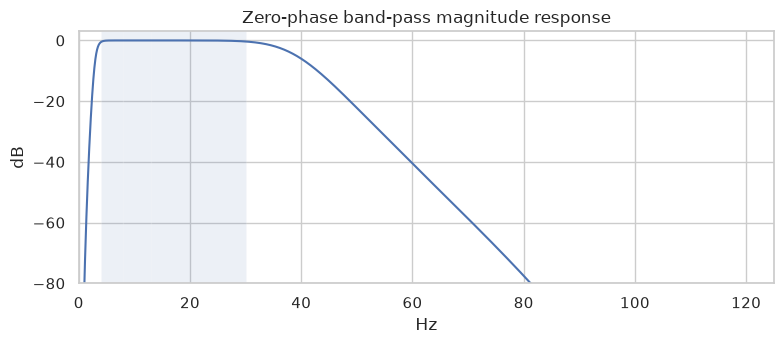

Attenuation at mains: {'50 Hz': '-22.2 dB', '60 Hz': '-40.6 dB'} | gain inside analysis bands: {'4 Hz': '-0.52 dB', '8 Hz': '-0.00 dB', '13 Hz': '-0.00 dB', '30 Hz': '-0.35 dB'}


In [28]:
if PIPELINE_OK:
    sos = signal.butter(CFG.FILTER_ORDER, list(CFG.BANDPASS_HZ), btype="bandpass", fs=FS_WORK, output="sos")
    w, h = signal.sosfreqz(sos, worN=4096, fs=FS_WORK)
    H = np.abs(h) ** 2                                              # forward-backward ⇒ |H|²
    fig, ax = plt.subplots(figsize=(8, 3.6)); ax.plot(w, 20 * np.log10(np.maximum(H, 1e-12))); ax.set(ylim=(-80, 3), xlim=(0, FS_WORK / 2), title="Zero-phase band-pass magnitude response", xlabel="Hz", ylabel="dB")
    for b, (lo, hi) in CFG.BANDS.items(): ax.axvspan(lo, hi, alpha=0.1)
    show(fig, "07_filter_response")
    att = {f"{m} Hz": f"{20*np.log10(np.interp(m, w, H)):.1f} dB" for m in (50, 60) if m < FS_WORK / 2}
    inb = {k: f"{20*np.log10(np.interp(v, w, H)):.2f} dB" for k, v in {"4 Hz": 4, "8 Hz": 8, "13 Hz": 13, "30 Hz": 30}.items()}
    print("Attenuation at mains:", att, "| gain inside analysis bands:", inb)

### 7.4 Sensitivity to the (inferred) sampling rate
If the true rate differs from the working rate by a few percent, filter edges and band edges shift. This analysis recomputes band powers with a deliberately wrong rate and reports the typical change, so you can see whether the *inferred* status matters in practice.

In [29]:
if PIPELINE_OK and len(proc_rows):
    ref_rows = [r for r in proc_rows if qc_report.quality_category[r] == "CLEAN"] or list(proc_rows)
    ref_rows = seeded(8).choice(ref_rows, size=min(30, len(ref_rows)), replace=False)
    base_lp = {r: log_band_powers(RAW[r], FS_WORK, NOTCH_HZ) for r in ref_rows}
    rows = []
    for sc in (0.95, 0.98, 0.99, 1.01, 1.02, 1.05):
        d = np.stack([np.abs(log_band_powers(RAW[r], FS_WORK * sc, NOTCH_HZ) - base_lp[r]) for r in ref_rows])
        rows.append(dict(assumed_fs_error=f"{100*(sc-1):+.0f}%", **{f"{b}_median|Δlog P|": float(np.median(d[:, k])) for k, b in enumerate(CFG.BANDS)}))
    display(pd.DataFrame(rows).round(4))
    print("Read: values ≲ 0.05 mean a ±2 % rate error changes band power by <≈5 % — small compared with between-trial variability.")

,assumed_fs_error,theta_median|Δlog P|,mu_median|Δlog P|,beta_median|Δlog P|
0,-5%,0.0740,0.0581,0.0591
1,-2%,0.0054,0.0478,0.0324
2,-1%,0.0021,0.0009,0.0162
3,+1%,0.0020,0.0009,0.0165
4,+2%,0.0047,0.0027,0.0175
5,+5%,0.1338,0.0715,0.0322


Read: values ≲ 0.05 mean a ±2 % rate error changes band power by <≈5 % — small compared with between-trial variability.


---
## Section 8 — Feature extraction

Computed on the **preprocessed, edge-trimmed** signal. Edge trimming is applied once in Section 7 and is shared by saved EEG arrays and feature extraction. Per channel (FZ, C3, CZ, C4):

| Family | Features |
|---|---|
| Time domain | mean, std, variance, RMS, peak-to-peak, skewness, excess kurtosis, Hjorth activity / mobility / complexity |
| Frequency domain | total power (4–40 Hz), absolute power θ / μ / β (valid because rate is working-assumed — scale depends on unknown units), **log** absolute power, **relative** power θ / μ / β, spectral entropy (4–40 Hz), peak frequency (4–30 Hz) |

**Cross-channel (sensorimotor asymmetry), μ and β:** contralateral ERD makes C3-vs-C4 power differences the classical lateralisation marker of left/right MI (Pfurtscheller & Lopes da Silva, 1999).
`asym_<band>_LI = (P_C4 − P_C3)/(P_C4 + P_C3)`, `asym_<band>_logratio = log P_C3 − log P_C4`, `asym_<band>_rel_diff = rel_C3 − rel_C4`. Positive LI ⇒ more power at C4.

Raw DC level and any file/ID information are **deliberately not features**.

In [30]:
def hjorth(v):
    """Hjorth activity, mobility, complexity."""
    d1, d2 = np.diff(v), np.diff(np.diff(v)); var0, var1, var2 = np.var(v), np.var(d1), np.var(d2)
    mob = math.sqrt(var1 / var0) if var0 > 0 else np.nan
    comp = (math.sqrt(var2 / var1) / mob) if (var1 > 0 and mob and np.isfinite(mob) and mob > 0) else np.nan
    return var0, mob, comp

TINY = np.finfo(float).tiny
def extract_features(xf, fs):
    """One feature row (dict) from a preprocessed recording (samples × 4)."""
    y = np.asarray(xf, dtype=float)  # edge transients were already removed in the preprocessing stage
    if CFG.PER_RECORDING_ZSCORE:
        y = (y - y.mean(0)) / y.std(0)
    f, P = welch_psd(y, fs)
    tot_m = (f >= CFG.TOTAL_BAND[0]) & (f < CFG.TOTAL_BAND[1]); pk_m = (f >= CFG.PEAK_BAND[0]) & (f <= CFG.PEAK_BAND[1])
    feats = {}
    for j, ch in enumerate(CH):
        v = y[:, j]; act, mob, comp = hjorth(v)
        total = float(trapezoid(P[tot_m, j], f[tot_m]))
        feats.update({f"{ch}_mean": float(v.mean()), f"{ch}_std": float(v.std(ddof=1)), f"{ch}_variance": float(np.var(v)),
                      f"{ch}_rms": float(np.sqrt(np.mean(v ** 2))), f"{ch}_ptp": float(np.ptp(v)),
                      f"{ch}_skewness": float(stats.skew(v, bias=False)), f"{ch}_kurtosis": float(stats.kurtosis(v, fisher=True, bias=False)),
                      f"{ch}_hjorth_activity": float(act), f"{ch}_hjorth_mobility": float(mob), f"{ch}_hjorth_complexity": float(comp),
                      f"{ch}_total_power": total})
        for b, (lo, hi) in CFG.BANDS.items():
            bp = float(band_power(f, P[:, j], lo, hi))
            feats[f"{ch}_{b}_power"] = bp; feats[f"{ch}_log_{b}_power"] = float(np.log(max(bp, TINY)))
            feats[f"{ch}_rel_{b}"] = bp / total if total > 0 else np.nan
        p = P[tot_m, j]; p = p / p.sum() if p.sum() > 0 else p
        feats[f"{ch}_spectral_entropy"] = float(-(p * np.log(p + TINY)).sum() / np.log(len(p)))
        feats[f"{ch}_peak_freq"] = float(f[pk_m][np.argmax(P[pk_m, j])])
    for b in ("mu", "beta"):                                          # sensorimotor asymmetry
        p3, p4 = feats[f"C3_{b}_power"], feats[f"C4_{b}_power"]
        feats[f"asym_{b}_LI"] = (p4 - p3) / (p4 + p3) if (p4 + p3) > 0 else np.nan
        feats[f"asym_{b}_logratio"] = float(np.log(max(p3, TINY)) - np.log(max(p4, TINY)))
        feats[f"asym_{b}_rel_diff"] = feats[f"C3_rel_{b}"] - feats[f"C4_rel_{b}"]
    return feats

FEATURE_DESC = {
 "mean": "mean of preprocessed signal", "std": "standard deviation", "variance": "variance", "rms": "root mean square",
 "ptp": "peak-to-peak amplitude", "skewness": "skewness", "kurtosis": "excess kurtosis", "hjorth_activity": "Hjorth activity (= variance)",
 "hjorth_mobility": "Hjorth mobility (≈ mean frequency)", "hjorth_complexity": "Hjorth complexity", "total_power": "integrated PSD 4–40 Hz",
 "theta_power": "absolute θ power 4–8 Hz", "mu_power": "absolute μ power 8–13 Hz", "beta_power": "absolute β power 13–30 Hz",
 "log_theta_power": "log θ power", "log_mu_power": "log μ power", "log_beta_power": "log β power",
 "rel_theta": "θ / total power", "rel_mu": "μ / total power", "rel_beta": "β / total power",
 "spectral_entropy": "normalised Shannon entropy of PSD 4–40 Hz", "peak_freq": "frequency of PSD maximum in 4–30 Hz"}
SCALE_DEPENDENT = {"std", "variance", "rms", "ptp", "hjorth_activity", "total_power", "theta_power", "mu_power", "beta_power", "mean"}

features_df = None; FEATURE_META = None
if PIPELINE_OK and len(proc_rows):
    rows = [extract_features(XF[k], FS_WORK) for k in tqdm(range(len(proc_rows)), desc="Extracting features")]
    features_df = pd.DataFrame(rows)
    metas = []
    for name in features_df.columns:
        if name.startswith("asym_"):
            metas.append(dict(name=name, channel="C3-C4", family="asymmetry", description=f"sensorimotor asymmetry: {name[5:]}", depends_on_fs=True, scale_dependent=False))
        else:
            ch, base = name.split("_", 1)
            metas.append(dict(name=name, channel=ch, family="time" if base in {"mean","std","variance","rms","ptp","skewness","kurtosis","hjorth_activity","hjorth_mobility","hjorth_complexity"} else "frequency",
                              description=FEATURE_DESC[base], depends_on_fs=base not in {"mean","std","variance","rms","ptp","skewness","kurtosis","hjorth_activity","hjorth_mobility","hjorth_complexity"},
                              scale_dependent=base in SCALE_DEPENDENT))
    FEATURE_META = pd.DataFrame(metas)
    print("Feature table:", features_df.shape, "|", FEATURE_META.family.value_counts().to_dict())
    display(features_df.iloc[:3, :10])
else:
    print("SKIPPED: no preprocessed recordings.")

Extracting features:   0%|          | 0/2160 [00:00<?, ?it/s]

Feature table: (2160, 94) | {'frequency': 48, 'time': 40, 'asymmetry': 6}


,FZ_mean,FZ_std,FZ_variance,FZ_rms,FZ_ptp,FZ_skewness,FZ_kurtosis,FZ_hjorth_activity,FZ_hjorth_mobility,FZ_hjorth_complexity
0,0.020958,41.364553,1710.265798,41.355365,420.264526,-0.914026,7.199768,1710.265798,0.449957,1.747268
1,0.056638,12.976141,168.305405,12.973381,110.764679,-0.778109,4.107274,168.305405,0.229332,2.155405
2,0.032051,16.826731,283.013043,16.823022,265.712044,-0.262599,19.886191,283.013043,0.397918,1.998415


### 8.1 Reproducibility check of the extraction
Re-running extraction on random recordings must give bit-identical features (no hidden randomness, no dependence on execution order).

In [31]:
if features_df is not None:
    chk = seeded(9).choice(len(features_df), size=min(8, len(features_df)), replace=False)
    again = pd.DataFrame([extract_features(XF[k], FS_WORK) for k in chk])
    FEATURE_REPRODUCIBLE = bool(np.allclose(again.to_numpy(), features_df.iloc[chk].to_numpy(), rtol=0, atol=0, equal_nan=True))
    print("Feature extraction deterministic:", FEATURE_REPRODUCIBLE)
else:
    FEATURE_REPRODUCIBLE = None

Feature extraction deterministic: True


---
## Section 9 — Feature quality and analysis

1. **Missing / infinite / constant** features.
2. **Exact redundancies** are verified numerically and removed *only if the identity holds in this data*:
   * `hjorth_activity` is by definition the signal variance → duplicate of `variance`;
   * `mean` of a detrended, band-passed signal is ≈ 0 (numerical noise) → no information.
3. **Correlation analysis** (Spearman) is shown for exploration. Data-driven pruning of correlated features is **not** done here: it must use **training rows only**, so it is performed in §11.
4. Distributions, including by quality category. Supervised importance is deferred until after the split and only with verified labels.

Features with missing/inf/constant values:


,result
0,none


Recordings with any non-finite feature: 0
Removed with verified justification: ['FZ_hjorth_activity', 'C3_hjorth_activity', 'CZ_hjorth_activity', 'C4_hjorth_activity']


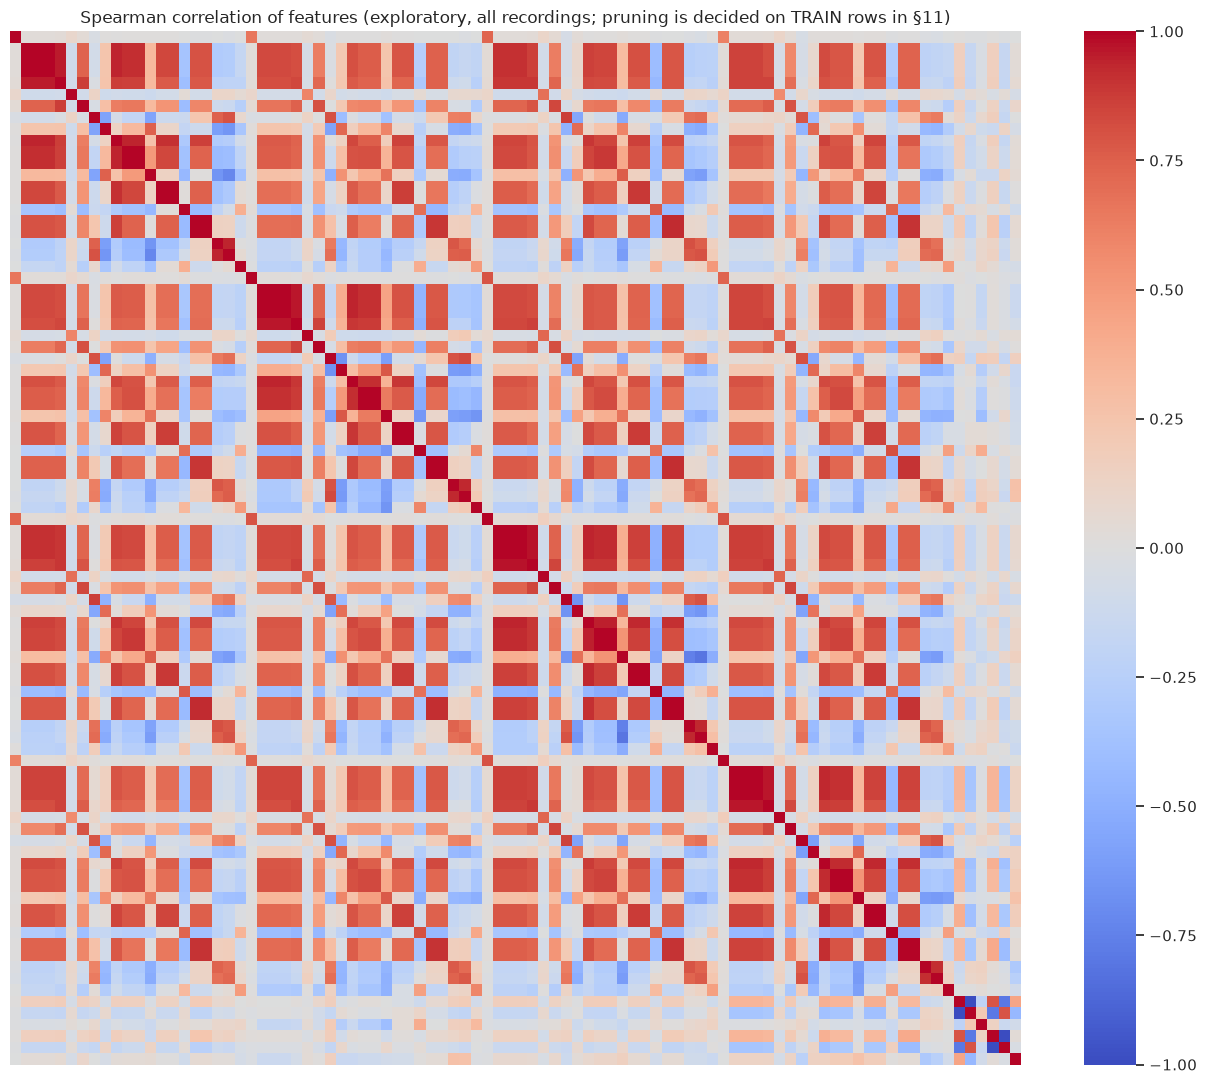

Number of feature pairs with |rho| ≥ 0.95 / 0.90 / 0.80: [(0.95, 40), (0.9, 125), (0.8, 487)]


,a,b,rho,abs_rho
3914,C4_mu_power,C4_log_mu_power,1.0,1.0
3950,C4_beta_power,C4_log_beta_power,1.0,1.0
3990,asym_mu_LI,asym_mu_logratio,-1.0,1.0
4002,asym_beta_LI,asym_beta_logratio,-1.0,1.0
3410,CZ_mu_power,CZ_log_mu_power,1.0,1.0
2924,CZ_std,CZ_variance,1.0,1.0
89,FZ_std,FZ_variance,1.0,1.0
2627,C3_beta_power,C3_log_beta_power,1.0,1.0
3869,C4_theta_power,C4_log_theta_power,1.0,1.0
1079,FZ_mu_power,FZ_log_mu_power,1.0,1.0


In [32]:
DROP_EXACT, PRUNING_LOG = [], []
if features_df is not None:
    Xf = features_df.copy()
    miss = Xf.isna().sum(); inf_ = np.isinf(Xf).sum(); const = Xf.nunique(dropna=True) <= 1
    qual = pd.DataFrame({"missing": miss, "infinite": inf_, "constant": const})
    print("Features with missing/inf/constant values:"); display(qual[(qual != 0).any(axis=1)] if (qual != 0).any().any() else pd.DataFrame({"result": ["none"]}))
    print("Recordings with any non-finite feature:", int((~np.isfinite(Xf.to_numpy())).any(axis=1).sum()))

    for ch in CH:                                        # exact duplicates by definition
        if np.allclose(Xf[f"{ch}_variance"], Xf[f"{ch}_hjorth_activity"], rtol=1e-9, atol=0):
            DROP_EXACT.append(f"{ch}_hjorth_activity"); PRUNING_LOG.append((f"{ch}_hjorth_activity", "identical to variance (verified numerically)"))
    for ch in CH:                                        # analytically ~0 after detrend+band-pass
        r = (Xf[f"{ch}_mean"].abs() / Xf[f"{ch}_std"]).max()
        if r < 1e-6:
            DROP_EXACT.append(f"{ch}_mean"); PRUNING_LOG.append((f"{ch}_mean", f"max |mean|/std = {r:.1e} (numerically zero after detrend + band-pass)"))
    print("Removed with verified justification:", DROP_EXACT)
    FEATURE_COLS_S9 = [c for c in Xf.columns if c not in DROP_EXACT]

    corr = Xf[FEATURE_COLS_S9].corr(method="spearman")
    fig, ax = plt.subplots(figsize=(13, 11)); sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, ax=ax, xticklabels=False, yticklabels=False)
    ax.set_title("Spearman correlation of features (exploratory, all recordings; pruning is decided on TRAIN rows in §11)"); show(fig, "09_correlation")
    iu = np.triu_indices(len(corr), 1)
    pairs = pd.DataFrame({"a": corr.index[iu[0]], "b": corr.columns[iu[1]], "rho": corr.to_numpy()[iu]})
    pairs["abs_rho"] = pairs.rho.abs()
    print("Number of feature pairs with |rho| ≥ 0.95 / 0.90 / 0.80:", [(t, int((pairs.abs_rho >= t).sum())) for t in (0.95, 0.90, 0.80)])
    display(pairs.sort_values("abs_rho", ascending=False).head(12).round(3))
else:
    FEATURE_COLS_S9 = []
    print("SKIPPED")

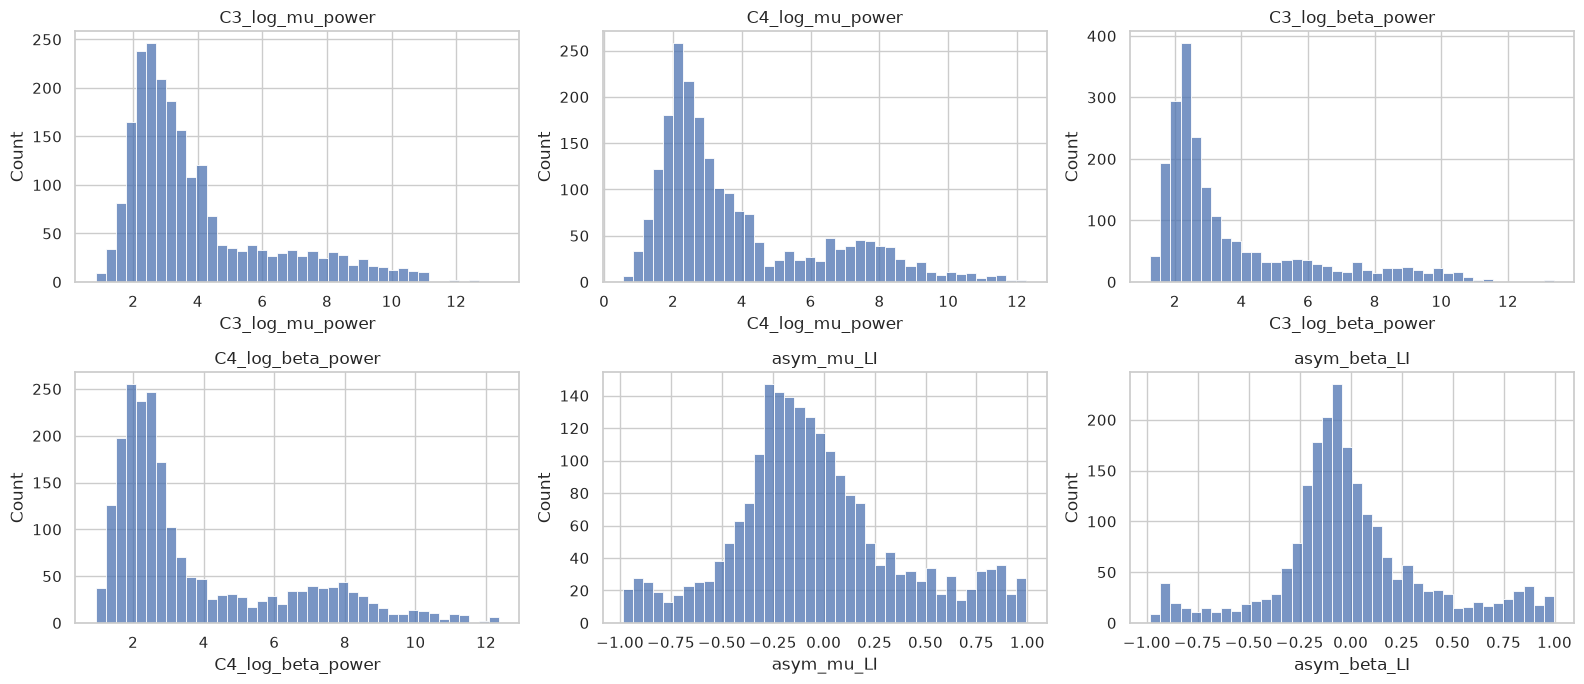

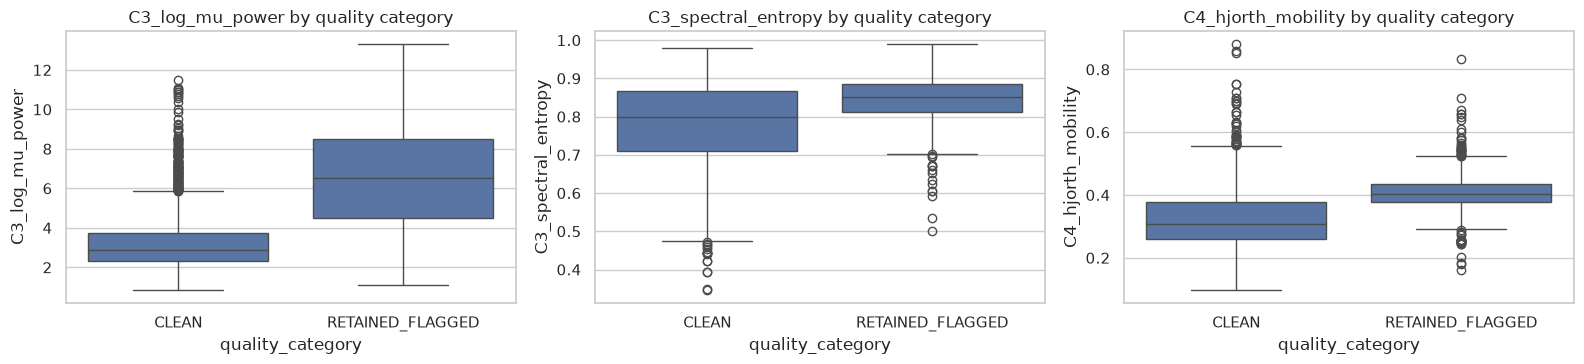

In [33]:
if features_df is not None:
    cats = qc_report.loc[proc_rows, "quality_category"].reset_index(drop=True)
    show_cols = [f"{c}_log_mu_power" for c in ("C3", "C4")] + [f"{c}_log_beta_power" for c in ("C3", "C4")] + ["asym_mu_LI", "asym_beta_LI"]
    fig, axes = plt.subplots(2, 3, figsize=(16, 7))
    for ax, c in zip(axes.ravel(), show_cols):
        sns.histplot(features_df[c], bins=40, ax=ax); ax.set_title(c)
    show(fig, "09_feature_distributions")
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    for ax, c in zip(axes, ["C3_log_mu_power", "C3_spectral_entropy", "C4_hjorth_mobility"]):
        sns.boxplot(x=cats, y=features_df[c], ax=ax, order=[o for o in ["CLEAN", "RETAINED_FLAGGED"] if o in set(cats)]); ax.set_title(f"{c} by quality category")
    show(fig, "09_feature_by_quality")

---
## Section 10 — Dataset construction

One row per **preprocessed, non-excluded recording**. Identifiers (`file_id`, `filename`) live in a separate `trial_meta` table; the feature matrix is built **only** from the declared feature columns, with an explicit guard against ID-like columns.

* **User-confirmed numeric file order** → `y` is attached through the generated filename mapping built from numeric file-ID order and the first N label rows (2160 here; the final 240 excess rows are excluded from the working copy). Trailing excess labels are ignored and audited.
* If the ordered mapping fails validation (missing/invalid paired labels or too few labels), **no `y` is created** and the unlabeled feature dataset is produced.

In [34]:
trial_meta = None
FORBIDDEN_IN_X = {"file_id", "filename", "row_index", "label", "y", "split", "block", "xf_pos", "quality_category", "quality_flags"}
if features_df is not None:
    trial_meta = qc_report.loc[proc_rows, ["file_id", "filename", "row_index", "quality_category", "quality_flags"]].reset_index(drop=True)
    trial_meta["xf_pos"] = np.arange(len(trial_meta))
    assert len(trial_meta) == len(features_df) and trial_meta.file_id.is_unique
    assert not (set(FEATURE_COLS_S9) & FORBIDDEN_IN_X), "ID/label-like column among features"
    if LABELS_VERIFIED:
        lab = mapping_df.set_index("filename")["label"]
        trial_meta["label"] = trial_meta.filename.map(lab).astype("object")
        nolab = trial_meta.label.isna()
        for r in trial_meta[nolab].itertuples():
            log_exclusion(r.file_id, r.filename, "LABEL", "no verified label for this recording")
        keep = ~nolab.to_numpy()
        trial_meta = trial_meta[keep].reset_index(drop=True); features_df = features_df[keep].reset_index(drop=True)
        trial_meta["y"] = trial_meta.label.map({"Left": 0, "Right": 1}).astype(int)
        print(f"LABELED dataset: {len(trial_meta)} trials | class counts: {trial_meta.label.value_counts().to_dict()}")
        assert set(trial_meta.label.unique()) <= VALID_LABELS
    else:
        trial_meta["label"] = None; trial_meta["y"] = np.nan
        print(f"UNLABELED dataset: {len(trial_meta)} trials (no y created)")
        print("To enable supervised training, fix the labels.csv rows paired to the sorted EEG files and re-run.")
    display(trial_meta.quality_category.value_counts().to_frame("trials"))
    display(trial_meta.head())
else:
    print("SKIPPED: no feature table.")

LABELED dataset: 2160 trials | class counts: {'Left': 1082, 'Right': 1078}


,trials
quality_category,
CLEAN,1694
RETAINED_FLAGGED,466


,file_id,filename,row_index,quality_category,quality_flags,xf_pos,label,y
0,1,cellula_MI_data_1.csv,0,RETAINED_FLAGGED,REPEATS_MINOR,0,Left,0
1,2,cellula_MI_data_2.csv,1,CLEAN,,1,Right,1
2,3,cellula_MI_data_3.csv,2,RETAINED_FLAGGED,REPEATS_MINOR,2,Left,0
3,4,cellula_MI_data_4.csv,3,RETAINED_FLAGGED,REPEATS_MINOR,3,Left,0
4,5,cellula_MI_data_5.csv,4,RETAINED_FLAGGED,REPEATS_MINOR,4,Left,0


---
## Section 11 — Train / validation / test splitting

### 11.1 Are neighbouring files related? (investigation, no assumptions)
Three label-free tests:
1. **Boundary continuity.** For consecutive IDs *k*, *k+1*: |first sample of *k+1* − last sample of *k*| (in units of the typical sample-to-sample step) versus the same quantity for **random non-neighbour pairs**. A ratio ≪ 1 means neighbours join up smoothly, i.e. files look like consecutive pieces of one continuous recording.
2. **DC-level similarity** between neighbours vs random pairs (drift structure).
3. **Autocorrelation of features across file IDs**: how many files must separate two recordings before their feature values decorrelate. This lag sets the **embargo** and the **block size**.

Whatever the result, a **blocked split with an embargo** is used — a random recording-level split is never used. The tests only decide *how wide* blocks and gaps must be.

,channel,boundary_jump_neighbours,boundary_jump_random,continuity_ratio,dc_diff_neighbours,dc_diff_random,dc_ratio
0,FZ,0.976,44.540,0.022,0.124,44.752,0.003
1,C3,0.702,48.933,0.014,0.092,49.318,0.002
2,CZ,0.841,27.306,0.031,0.071,27.374,0.003
3,C4,0.900,32.652,0.028,0.088,32.494,0.003


Time column: first value per file — min 3457.147, median 565352.597, max 1679824.099; median (next file start − this file end) = 0.0025 s
  → Time carries information across files.


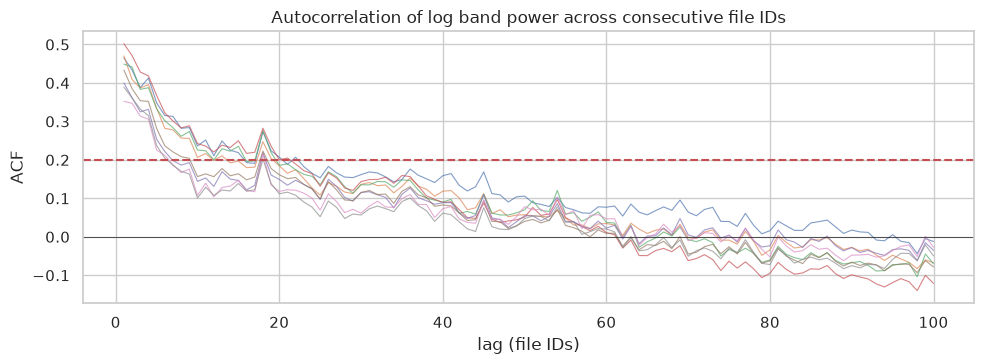

median lag-1 ACF = 0.44; median decorrelation lag (ACF<0.2) = 11 files; neighbours dependent: True
→ EMBARGO = 11 file IDs, BLOCK_SIZE = 44 file IDs


In [35]:
def neighbour_continuity(qc, n_random=6000):
    v = qc.structure_ok.to_numpy(); ids = qc.file_id.to_numpy()
    adj = np.flatnonzero((np.diff(ids) == 1) & v[:-1] & v[1:]); vi = np.flatnonzero(v)
    rng = seeded(10); i = rng.choice(vi, n_random); j = rng.choice(vi, n_random); m = np.abs(ids[i] - ids[j]) >= 100; i, j = i[m], j[m]
    rows = []
    for ch in CH:
        S = np.nanmedian(qc[f"{ch}_step"]); first, last, mean = (qc[f"{ch}_{k}"].to_numpy() for k in ("first", "last", "mean"))
        nb, rn = np.abs(first[adj + 1] - last[adj]) / S, np.abs(first[j] - last[i]) / S
        nbm, rnm = np.abs(mean[adj + 1] - mean[adj]) / S, np.abs(mean[j] - mean[i]) / S
        rows.append(dict(channel=ch, boundary_jump_neighbours=np.nanmedian(nb), boundary_jump_random=np.nanmedian(rn),
                         continuity_ratio=np.nanmedian(nb) / np.nanmedian(rn), dc_diff_neighbours=np.nanmedian(nbm),
                         dc_diff_random=np.nanmedian(rnm), dc_ratio=np.nanmedian(nbm) / np.nanmedian(rnm)))
    gap = qc.t_first.to_numpy()[adj + 1] - qc.t_last.to_numpy()[adj]
    return pd.DataFrame(rows), gap

def id_autocorr(values, ids, max_lag=100):
    s = pd.Series(np.asarray(values), index=np.asarray(ids)).reindex(range(int(np.min(ids)), int(np.max(ids)) + 1))
    return np.array([s.autocorr(l) for l in range(1, max_lag + 1)])

NEIGHBOUR_DEPENDENT, EMBARGO, BLOCK_SIZE, DECOR_LAG = None, None, None, None
if features_df is not None:
    cont, gap = neighbour_continuity(qc)
    display(cont.round(3))
    print(f"Time column: first value per file — min {qc.t_first.min():.3f}, median {qc.t_first.median():.3f}, max {qc.t_first.max():.3f}; "
          f"median (next file start − this file end) = {np.nanmedian(gap):.4f} s")
    print("  → " + ("Time restarts near the same value in every file (no absolute time ordering available)." if (qc.t_first.max() - qc.t_first.min()) < 5 * qc.duration_s.median()
                    else "Time carries information across files."))
    series = [f"{c}_log_{b}_power" for c in CH for b in ("mu", "beta")]
    acfs = {s: id_autocorr(features_df[s], trial_meta.file_id, 100) for s in series}
    lags = np.arange(1, 101)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for s, a in acfs.items(): ax.plot(lags, a, lw=0.8, alpha=.7)
    ax.axhline(CFG.ACF_THRESHOLD, c="r", ls="--"); ax.axhline(0, c="k", lw=.5); ax.set(title="Autocorrelation of log band power across consecutive file IDs", xlabel="lag (file IDs)", ylabel="ACF")
    show(fig, "11_acf_across_ids")
    dl = [int(next((l for l, v in zip(lags, a) if np.isfinite(v) and v < CFG.ACF_THRESHOLD), lags[-1])) for a in acfs.values()]
    DECOR_LAG = int(np.median(dl)); lag1 = float(np.nanmedian([a[0] for a in acfs.values()]))
    NEIGHBOUR_DEPENDENT = bool(cont.continuity_ratio.median() < 0.5 or lag1 > 0.5)
    print(f"median lag-1 ACF = {lag1:.2f}; median decorrelation lag (ACF<{CFG.ACF_THRESHOLD}) = {DECOR_LAG} files; neighbours dependent: {NEIGHBOUR_DEPENDENT}")
    EMBARGO = CFG.EMBARGO if CFG.EMBARGO is not None else int(np.clip(DECOR_LAG, 1, CFG.EMBARGO_MAX))
    BLOCK_SIZE = CFG.BLOCK_SIZE if CFG.BLOCK_SIZE is not None else int(max(CFG.BLOCK_SIZE_MIN, 4 * EMBARGO))
    BLOCK_SIZE = int(max(5, min(BLOCK_SIZE, len(trial_meta) // 10)))          # ensure ≥10 blocks on small datasets
    print(f"→ EMBARGO = {EMBARGO} file IDs, BLOCK_SIZE = {BLOCK_SIZE} file IDs")
    register("What one CSV represents (trial / continuous)", "undetermined" if not NEIGHBOUR_DEPENDENT else "neighbouring files are statistically dependent",
             "INFERRED", f"continuity ratio (median) {cont.continuity_ratio.median():.2f}; lag-1 ACF {lag1:.2f}")
    if NEIGHBOUR_DEPENDENT:
        ISSUES.append("Neighbouring files are dependent (continuity / autocorrelation) → only blocked splits with embargo are valid")

### 11.2 Blocked split with embargo
* Recordings are grouped into **contiguous blocks of file IDs**; whole blocks are assigned to train / validation / test with a seeded shuffle (quota 70/15/15 by recordings).
* At every boundary between blocks of different splits, files within `EMBARGO` IDs of the boundary are dropped from the **lower-priority** side (test > validation > train). Dropped files are **logged**, not silently lost.
* **Stratification** (only if labels are verified): 300 seeded block assignments are scored by the largest deviation of any split's class share from the overall share, and the best is kept. Both classes must be present in every split.
* The test set is created here and then **not touched** until the final evaluation.

**Important interpretation:** exploratory 9-file repeat/DC patterns are not evidence to reorder labels. The confirmed mapping remains numeric file ID 1..N ↔ label row 1..N. Because subject/session metadata are unavailable, blocked splits and an embargo are retained as a conservative safeguard; the notebook does not claim that true subject/session grouping has been verified.


,recordings,blocks,right_share
split,,,
EMBARGO,275,21,0.498
test,352,8,0.500
train,1203,34,0.499
val,330,8,0.500


stratification score (max class-share deviation): 0.0019


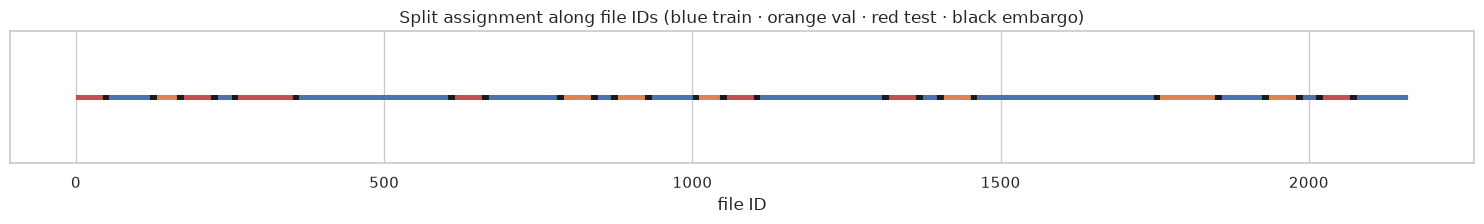

In [36]:
def make_block_split(file_ids, y, fractions, block_size, embargo, seed, n_tries=300):
    ids = np.asarray(file_ids); block = (ids - ids.min()) // block_size
    ub, inv = np.unique(block, return_inverse=True); sizes = np.bincount(inv); total = len(ids)
    quota = {"test": fractions[2] * total, "val": fractions[1] * total}
    rng = np.random.default_rng(seed); best, best_score = None, np.inf
    for _ in range(n_tries if y is not None else 1):
        assign = np.empty(len(ub), dtype=object); filled = dict(test=0, val=0)
        for b in rng.permutation(len(ub)):
            if filled["test"] < quota["test"]: assign[b] = "test"; filled["test"] += sizes[b]
            elif filled["val"] < quota["val"]: assign[b] = "val"; filled["val"] += sizes[b]
            else: assign[b] = "train"
        split = assign[inv]; score = 0.0
        if y is not None:
            present = [s for s in ("train", "val", "test") if (split == s).any()]
            score = max(abs(y[split == s].mean() - y.mean()) for s in present)
            if any(len(np.unique(y[split == s])) < 2 for s in present): score += 10
        if best is None or score < best_score: best, best_score = split.copy(), score
    sp = best.copy(); prio = {"train": 0, "val": 1, "test": 2}; order = np.argsort(ids); sid, ssp = ids[order], sp[order]
    drop = np.zeros(len(ids), bool)
    for a in range(len(sid)):
        b = a + 1
        while b < len(sid) and sid[b] - sid[a] <= embargo:
            if ssp[a] != ssp[b]: drop[order[a if prio[ssp[a]] < prio[ssp[b]] else b]] = True
            b += 1
    sp[drop] = "EMBARGO"
    return pd.DataFrame({"file_id": ids, "block": block, "split": sp}), best_score

SPLIT_DF = None
if features_df is not None:
    y_for_split = trial_meta.y.to_numpy().astype(int) if LABELS_VERIFIED else None
    SPLIT_DF, split_score = make_block_split(trial_meta.file_id.to_numpy(), y_for_split, CFG.SPLIT_FRACTIONS, BLOCK_SIZE, EMBARGO, CFG.RANDOM_STATE)
    trial_meta = trial_meta.merge(SPLIT_DF, on="file_id", how="left"); assert trial_meta.split.notna().all()
    for r in trial_meta[trial_meta.split == "EMBARGO"].itertuples():
        log_exclusion(r.file_id, r.filename, "SPLIT", f"embargo gap ({EMBARGO} IDs) at split boundary")
    summ = trial_meta.groupby("split").agg(recordings=("file_id", "size"), blocks=("block", "nunique"))
    if LABELS_VERIFIED: summ = summ.join(trial_meta.groupby("split").y.agg(right_share="mean"))
    display(summ.round(3)); print("stratification score (max class-share deviation):", None if y_for_split is None else round(split_score, 4))
    fig, ax = plt.subplots(figsize=(15, 2.4)); cmap = {"train": "C0", "val": "C1", "test": "C3", "EMBARGO": "k"}
    ax.scatter(trial_meta.file_id, np.zeros(len(trial_meta)), c=trial_meta.split.map(cmap), s=12, marker="|")
    ax.set(yticks=[], title="Split assignment along file IDs (blue train · orange val · red test · black embargo)", xlabel="file ID"); show(fig, "11_split_layout")

### 11.3 Train-only fitting: feature pruning and scaling
Everything that *learns* from data is fitted on **training rows only**, then applied unchanged to validation and test:
1. drop features with zero variance in train;
2. **correlation pruning**: for any pair with |Spearman ρ| ≥ `CORR_PRUNE` (train rows), drop the lower-priority twin (priority: scale-free/log/relative/shape features before scale-dependent absolute ones). Each removal is logged with its partner and ρ;
3. **RobustScaler** (median/IQR) — chosen because amplitudes are heavy-tailed and some retained recordings are flagged.

No supervised feature selection is performed.

In [37]:
def _priority(c):
    keys = ("asym_", "_log_", "_rel_", "hjorth_mobility", "hjorth_complexity", "spectral_entropy", "peak_freq", "skewness", "kurtosis")
    return 0 if any(k in c for k in keys) else 1

def select_features(Xtr: pd.DataFrame, cols, thr):
    """Fit on TRAIN rows only → (selected columns in original order, log of removals)."""
    log, cols = [], list(cols)
    zero = [c for c in cols if Xtr[c].std() == 0 or Xtr[c].nunique() <= 1]
    log += [(c, "zero variance in train", None, None) for c in zero]
    cols = [c for c in cols if c not in zero]
    corr = Xtr[cols].rank().corr(); keep = []
    for c in sorted(cols, key=lambda c: (_priority(c), cols.index(c))):
        partner = next((k for k in keep if abs(corr.loc[c, k]) >= thr), None)
        if partner is None: keep.append(c)
        else: log.append((c, "correlated with a higher-priority feature", partner, float(corr.loc[c, partner])))
    return [c for c in cols if c in keep], log

SELECTED, PRUNE_LOG, SCALER = None, None, None
SPLIT_DATA = {}
if features_df is not None:
    tr = (trial_meta.split == "train").to_numpy()
    SELECTED, PRUNE_LOG = select_features(features_df.loc[tr], FEATURE_COLS_S9, CFG.CORR_PRUNE)
    SCALER = RobustScaler().fit(features_df.loc[tr, SELECTED].to_numpy(float))
    for s in ("train", "val", "test"):
        m = (trial_meta.split == s).to_numpy()
        Xs = SCALER.transform(features_df.loc[m, SELECTED].to_numpy(float)).astype(np.float32)
        assert np.isfinite(Xs).all(), f"non-finite after scaling in {s}"
        SPLIT_DATA[s] = dict(X=Xs, meta=trial_meta[m].reset_index(drop=True), X_unscaled=features_df.loc[m, SELECTED].reset_index(drop=True),
                             y=(trial_meta.loc[m, "y"].to_numpy().astype(int) if LABELS_VERIFIED else None))
    print(f"Features: {len(FEATURE_COLS_S9)} → {len(SELECTED)} after train-only pruning (threshold |ρ| ≥ {CFG.CORR_PRUNE})")
    display(pd.DataFrame(PRUNE_LOG, columns=["removed", "reason", "kept_partner", "rho"]).round(3).head(40))
    display(pd.DataFrame({s: [d["X"].shape[0], d["X"].shape[1]] for s, d in SPLIT_DATA.items()}, index=["rows", "features"]))

Features: 90 → 64 after train-only pruning (threshold |ρ| ≥ 0.95)


,removed,reason,kept_partner,rho
0,asym_mu_logratio,correlated with a higher-priority feature,asym_mu_LI,-1.000
1,asym_beta_logratio,correlated with a higher-priority feature,asym_beta_LI,-1.000
2,FZ_variance,correlated with a higher-priority feature,FZ_std,1.000
3,FZ_rms,correlated with a higher-priority feature,FZ_std,1.000
4,FZ_ptp,correlated with a higher-priority feature,FZ_std,0.950
5,FZ_theta_power,correlated with a higher-priority feature,FZ_log_theta_power,1.000
6,FZ_mu_power,correlated with a higher-priority feature,FZ_log_mu_power,1.000
7,FZ_beta_power,correlated with a higher-priority feature,FZ_log_beta_power,1.000
8,C3_variance,correlated with a higher-priority feature,C3_std,1.000
9,C3_rms,correlated with a higher-priority feature,C3_std,1.000


,train,val,test
rows,1203,330,352
features,64,64,64


### 11.4 Label alignment — user-confirmed numeric file order

The user confirmed that `labels.csv` rows correspond to EEG files in ascending numeric `file_id` order. The notebook pairs file IDs 1..N with the first N label rows, excludes trailing excess labels from the working copy, and preserves the original label file. This is a documented dataset-order rule, not an inference from EEG signal similarity. The generated mapping is validated one-to-one before any `y` is attached.


In [38]:
ALIGNMENT_TEST_USED_TEST = False
ALIGNMENT_RESULT = "user_confirmed_numeric_file_order" if LABELS_VERIFIED else None
print("Label alignment method:", ALIGNMENT_RESULT or "mapping validation failed")
print("Mapping: EEG file IDs 1..N ↔ labels.csv rows 1..N; trailing labels excluded.")
print("No label-to-file relationship was inferred from signal similarity.")


Label alignment method: user_confirmed_numeric_file_order
Mapping: EEG file IDs 1..N ↔ labels.csv rows 1..N; trailing labels excluded.
No label-to-file relationship was inferred from signal similarity.


### 11.5 Feature-importance exploration (labels verified only; train fit, validation evaluation)
Exploratory only — **not** used to select features. Test data are not used.

In [39]:
if features_df is not None and LABELS_VERIFIED:
    rf = RandomForestClassifier(n_estimators=300, random_state=CFG.RANDOM_STATE, n_jobs=-1).fit(SPLIT_DATA["train"]["X"], SPLIT_DATA["train"]["y"])
    pi = permutation_importance(rf, SPLIT_DATA["val"]["X"], SPLIT_DATA["val"]["y"], n_repeats=10, random_state=CFG.RANDOM_STATE, scoring="roc_auc")
    imp = pd.DataFrame({"feature": SELECTED, "perm_importance_val_auc": pi.importances_mean, "std": pi.importances_std}).sort_values("perm_importance_val_auc", ascending=False)
    display(imp.head(15).round(4)); print("validation AUC of this exploratory forest:", round(float(__import__("sklearn.metrics", fromlist=["roc_auc_score"]).roc_auc_score(SPLIT_DATA["val"]["y"], rf.predict_proba(SPLIT_DATA["val"]["X"])[:, 1])), 3))
else:
    print("SKIPPED: requires verified labels.")

,feature,perm_importance_val_auc,std
32,CZ_skewness,0.0080,0.0035
34,CZ_hjorth_mobility,0.0073,0.0027
24,C3_log_mu_power,0.0046,0.0043
47,C4_skewness,0.0044,0.0042
0,FZ_mean,0.0044,0.0037
28,C3_spectral_entropy,0.0040,0.0022
9,FZ_log_mu_power,0.0035,0.0017
51,C4_total_power,0.0028,0.0024
43,CZ_spectral_entropy,0.0027,0.0023
17,C3_skewness,0.0023,0.0032


validation AUC of this exploratory forest: 0.502


---
## Section 12 — Final model-ready dataset (saved outputs)

```text
<OUT_DIR>/
├── 00_config/        preprocessing_config.json · evidence_registry.csv · environment.json
├── 01_audit/         file_inventory.csv · qc_metrics.csv · quality_report.csv · excluded_recordings.csv · sampling_rate_report.json · repeat_dose_response.csv
├── 02_preprocessed/  preprocessed_signals.npz            (band-passed + edge-cropped recordings, float32)
├── 03_features/      features_all.csv · features_unlabeled.csv · feature_metadata.csv
├── 04_labels/        verified_labels.csv   (ONLY if a verified mapping exists)
├── 05_splits/        X_{train,val,test}.csv|.npy · y_{train,val,test}.csv|.npy (ONLY if labels verified) · ids_{…}.csv · split_assignment.csv · scaler.joblib · selected_features.json
├── 06_reports/       validation_checklist.csv · dataset_summary.json · REPORT.md
└── cache/ · figures/
```
`X_*` are the **scaled, selected** features (train-fitted); `ids_*` carry `file_id`/`filename` **separately** so IDs can never leak into `X`.

In [40]:
import joblib
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    if isinstance(o, Path): return str(o)
    return str(o)

# ---- 00_config -------------------------------------------------------------------------------------------
CONFIG_OUT = dict(
    sampling_rate=dict(value_hz=FS_WORK, status=FS_STATUS, evidence=FS_EVIDENCE),
    bandpass_hz=list(CFG.BANDPASS_HZ), filter=f"Butterworth order {CFG.FILTER_ORDER}, zero-phase sosfiltfilt",
    detrend="linear (per channel, whole recording)", notch=dict(hz=NOTCH_HZ, evidence=NOTCH_EVIDENCE), edge_trim_s=CFG.EDGE_TRIM_S,
    per_recording_zscore=CFG.PER_RECORDING_ZSCORE, event_baseline_correction="not applied (event timing unknown)", artifact_handling="flag-only; no repair",
    bands_hz=CFG.BANDS, total_band_hz=CFG.TOTAL_BAND, welch=dict(nperseg=CFG.NPERSEG, overlap=0.5, window="hann"),
    repeat_handling=dict(exclusion_limit=None, primary_policy="flag only; repeated samples never exclude recordings or delete/modify source files", tolerance_log_power=CFG.REPEAT_TOLERANCE, method="dose-response simulation is diagnostic/sensitivity analysis only"),
    quality=dict(amp_modz=CFG.AMP_MODZ, flat_run_min=CFG.FLAT_RUN_MIN, rate_dev_tol=CFG.RATE_DEV_TOL),
    split=dict(strategy="contiguous file-ID blocks + embargo", block_size=BLOCK_SIZE, embargo=EMBARGO, fractions=CFG.SPLIT_FRACTIONS, seed=CFG.RANDOM_STATE,
               stratified=bool(LABELS_VERIFIED), neighbours_dependent=NEIGHBOUR_DEPENDENT, decorrelation_lag=DECOR_LAG),
    corr_prune=CFG.CORR_PRUNE, scaler="RobustScaler (fit on train only)", labels_verified=bool(LABELS_VERIFIED),
    mapping_source=CFG.MAPPING_SOURCE, data_root=str(CFG.DATA_ROOT), random_state=CFG.RANDOM_STATE)
(DIRS["config"] / "preprocessing_config.json").write_text(json.dumps(CONFIG_OUT, indent=2, default=jsonable))
pd.DataFrame(META).to_csv(DIRS["config"] / "evidence_registry.csv", index=False)
(DIRS["config"] / "environment.json").write_text(json.dumps(dict(python=sys.version, platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__,
                                                                  scipy=__import__("scipy").__version__, sklearn=sklearn.__version__), indent=2))

# ---- 01_audit --------------------------------------------------------------------------------------------
inv = files_df.copy(); inv["path"] = inv.path.map(lambda p: str(Path(p).relative_to(CFG.DATA_ROOT)) if str(p).startswith(str(CFG.DATA_ROOT)) else p)
inv.to_csv(DIRS["audit"] / "file_inventory.csv", index=False)
qc.to_csv(DIRS["audit"] / "qc_metrics.csv", index=False)
qc_report.to_csv(DIRS["audit"] / "quality_report.csv", index=False)
excluded_df = pd.DataFrame(EXCLUSIONS, columns=["file_id", "filename", "stage", "reason"]).sort_values(["stage", "file_id"]) if EXCLUSIONS else pd.DataFrame(columns=["file_id", "filename", "stage", "reason"])
excluded_df.to_csv(DIRS["audit"] / "excluded_recordings.csv", index=False)
(DIRS["audit"] / "sampling_rate_report.json").write_text(json.dumps(dict(
    median_rate_hz=fs_med, iqr=[q25, q75], bootstrap_ci95=[ci_lo, ci_hi], nearest_nominal=nominal, share_within_1pct=within1, share_within_2pct=within2,
    working_rate=FS_WORK, status=FS_STATUS, evidence=FS_EVIDENCE), indent=2, default=jsonable))
if "dose" in globals(): dose.to_csv(DIRS["audit"] / "repeat_dose_response.csv", index=False)
print("Excluded/dropped recordings by stage:"); display(excluded_df.groupby("stage").size().to_frame("recordings") if len(excluded_df) else pd.DataFrame({"result": ["none"]}))

Excluded/dropped recordings by stage:


,recordings
stage,
SPLIT,275


In [41]:
SAVED = []
if features_df is not None:
    # ---- 02_preprocessed ----
    np.savez_compressed(DIRS["preprocessed"] / "preprocessed_signals.npz", X=XF, file_ids=qc.file_id.to_numpy()[proc_rows], filenames=qc.filename.to_numpy()[proc_rows].astype(str),
                        channel_order=np.array(CH), fs_hz=FS_WORK, fs_status=FS_STATUS, bandpass_hz=np.array(CFG.BANDPASS_HZ), notch_hz=np.nan if NOTCH_HZ is None else NOTCH_HZ, edge_trim_s=CFG.EDGE_TRIM_S)
    # ---- 03_features ----
    allf = pd.concat([trial_meta.drop(columns=["xf_pos"]).reset_index(drop=True), features_df.reset_index(drop=True)], axis=1)
    allf.to_csv(DIRS["features"] / "features_all.csv", index=False)
    unl = pd.concat([trial_meta[["file_id", "filename", "quality_category", "quality_flags", "split"]].reset_index(drop=True), features_df[SELECTED].reset_index(drop=True)], axis=1)
    unl.to_csv(DIRS["features"] / "features_unlabeled.csv", index=False)
    fm = FEATURE_META.copy(); fm["status"] = np.where(fm.name.isin(SELECTED), "selected", "removed")
    why = {n: r for n, r in PRUNING_LOG}; why.update({c: f"{r} ({p}, rho={rho:.3f})" if p else r for c, r, p, rho in PRUNE_LOG})
    fm["removal_reason"] = fm.name.map(why).fillna(""); fm.to_csv(DIRS["features"] / "feature_metadata.csv", index=False)
    # ---- 04_labels ----
    if LABELS_VERIFIED:
        mapping_df.to_csv(DIRS["labels"] / "ordered_filename_label_mapping.csv", index=False)
        trial_meta[["file_id", "filename", "label", "y"]].to_csv(DIRS["labels"] / "verified_labels.csv", index=False)
    else:
        (DIRS["labels"] / "README_labels_unverified.txt").write_text("The user-confirmed numeric file-order mapping could not be validated. No y was created.\nCheck that labels.csv has at least one valid Left/Right row per discovered EEG file, then re-run.\n")
    if labels_excess_df is not None and len(labels_excess_df):
        labels_excess_df.to_csv(DIRS["audit"] / "ignored_excess_label_rows.csv", index=False)
    (DIRS["audit"] / "label_alignment_audit.json").write_text(json.dumps(mapping_report, indent=2, default=jsonable))
    # ---- 05_splits ----
    SPLIT_DF_OUT = trial_meta[["file_id", "filename", "block", "split"]]; SPLIT_DF_OUT.to_csv(DIRS["splits"] / "split_assignment.csv", index=False)
    for s, d in SPLIT_DATA.items():
        np.save(DIRS["splits"] / f"X_{s}.npy", d["X"]); pd.DataFrame(d["X"], columns=SELECTED).to_csv(DIRS["splits"] / f"X_{s}.csv", index=False)
        d["meta"][["file_id", "filename", "block"]].to_csv(DIRS["splits"] / f"ids_{s}.csv", index=False)
        if LABELS_VERIFIED:
            np.save(DIRS["splits"] / f"y_{s}.npy", d["y"]); pd.DataFrame({"y": d["y"], "label": np.where(d["y"] == 1, "Right", "Left")}).to_csv(DIRS["splits"] / f"y_{s}.csv", index=False)
    joblib.dump(SCALER, DIRS["splits"] / "scaler.joblib")
    (DIRS["splits"] / "selected_features.json").write_text(json.dumps(dict(selected=SELECTED, n_selected=len(SELECTED), label_encoding={"Left": 0, "Right": 1}, scaler="RobustScaler",
                                                                          fitted_on="train split only", removed=[dict(feature=c, reason=r, partner=p, rho=rho) for c, r, p, rho in PRUNE_LOG]), indent=2, default=jsonable))
    # Preserve the exact working labels and the original excess rows separately.
    if LABELS_VERIFIED:
        labels_used_df.to_csv(DIRS["labels"] / "labels_used_first_N_rows.csv", index=False)
        if labels_excess_df is not None and len(labels_excess_df):
            labels_excess_df.to_csv(DIRS["labels"] / "excluded_trailing_labels.csv", index=False)

    # Save edge-cropped raw EEG arrays for deep-learning workflows, using the SAME split IDs.
    final_bundle = {}
    for s, d in SPLIT_DATA.items():
        xf_positions = d["meta"]["xf_pos"].to_numpy(dtype=int)
        eeg_split = XF[xf_positions].astype(np.float32)
        np.save(DIRS["splits"] / f"eeg_X_{s}.npy", eeg_split)
        final_bundle[f"eeg_X_{s}"] = eeg_split
        final_bundle[f"features_X_{s}"] = d["X"].astype(np.float32)
        final_bundle[f"file_ids_{s}"] = d["meta"]["file_id"].to_numpy(dtype=np.int64)
        final_bundle[f"filenames_{s}"] = d["meta"]["filename"].to_numpy(dtype=str)
        if LABELS_VERIFIED:
            final_bundle[f"y_{s}"] = d["y"].astype(np.int64)

    if LABELS_VERIFIED:
        np.savez_compressed(DIRS["splits"] / "final_training_dataset.npz", **final_bundle)
        (DIRS["reports"] / "TRAINING_DATA_README.txt").write_text(
            "Supervised BCI MI dataset\\n"
            "Labels: Left=0, Right=1\\n"
            "Mapping: numeric EEG file ID 1..N maps to labels.csv row 1..N, confirmed by the user.\\n"
            "The original labels.csv is unchanged; trailing excess rows are saved separately.\\n"
            "eeg_X_*: edge-cropped preprocessed EEG arrays (trials, samples, channels).\\n"
            "features_X_*: selected and RobustScaled engineered features; scaler fitted on train only.\\n"
            "y_*: labels aligned to the same rows.\\n"
            "Splits are blocked by file-ID blocks with an embargo; no subject/session IDs were supplied.\\n"
            "Sampling frequency is data-inferred unless authoritative metadata is supplied.\\n",
            encoding="utf-8"
        )

    SAVED = sorted(str(p.relative_to(CFG.OUT_DIR)) for p in CFG.OUT_DIR.rglob("*") if p.is_file() and "cache" not in p.parts and "figures" not in p.parts)
    print(f"Saved {len(SAVED)} files under {CFG.OUT_DIR}"); print("\n".join("  " + s for s in SAVED))
else:
    print("SKIPPED: nothing to save beyond the audit files above.")

Saved 60 files under /home/iroh/Documents/task7/Task7/bci_prepared
  00_config/environment.json
  00_config/evidence_registry.csv
  00_config/preprocessing_config.json
  01_audit/excluded_recordings.csv
  01_audit/file_inventory.csv
  01_audit/ignored_excess_label_rows.csv
  01_audit/label_alignment_audit.json
  01_audit/qc_metrics.csv
  01_audit/quality_report.csv
  01_audit/repeat_dose_response.csv
  01_audit/sampling_rate_report.json
  02_preprocessed/X_preprocessed.npy
  02_preprocessed/file_ids.npy
  02_preprocessed/preprocess_signature.json
  02_preprocessed/preprocessed_meta.json
  02_preprocessed/preprocessed_signals.npz
  02_preprocessed/y.npy
  03_features/__pycache__/bci_preprocess.cpython-312.pyc
  03_features/bci_preprocess.py
  03_features/csp_svm_baseline.joblib
  03_features/csp_svm_baseline_meta.json
  03_features/eegnet.pt
  03_features/eegnet_meta.json
  03_features/feature_metadata.csv
  03_features/features_all.csv
  03_features/features_unlabeled.csv
  04_labels/e

### 12.1 How to load the datasets (this cell reads back from disk)
```python
X_train = pd.read_csv(SPLITS/"X_train.csv")        # scaled, selected features (train-fitted RobustScaler)
y_train = pd.read_csv(SPLITS/"y_train.csv")["y"]   # 0 = Left, 1 = Right   (exists ONLY if labels were verified)
ids_train = pd.read_csv(SPLITS/"ids_train.csv")    # file_id / filename / block — never part of X
```
The same pattern applies to `val` and `test`. `.npy` versions are float32 arrays with identical row order. The validation set is for model selection; **use the test set once**, at the very end.

For deep-learning models, load `eeg_X_train.npy`, `eeg_X_val.npy`, and `eeg_X_test.npy` (shape: trials × samples × 4 channels), with the matching `y_*.npy` labels. For classical ML, use the scaled feature matrices `X_*.npy` or CSV files.


In [42]:
if features_df is not None:
    SPL = DIRS["splits"]
    loaded = {s: dict(X=pd.read_csv(SPL / f"X_{s}.csv"), ids=pd.read_csv(SPL / f"ids_{s}.csv"),
                      y=(pd.read_csv(SPL / f"y_{s}.csv")["y"] if (SPL / f"y_{s}.csv").exists() else None)) for s in ("train", "val", "test")}
    display(pd.DataFrame({s: dict(X_shape=d["X"].shape, y=("none (labels unverified)" if d["y"] is None else d["y"].shape),
                                  right_share=(None if d["y"] is None else round(float(d["y"].mean()), 3))) for s, d in loaded.items()}).T)

,X_shape,y,right_share
train,"(1203, 64)","(1203,)",0.499
val,"(330, 64)","(330,)",0.5
test,"(352, 64)","(352,)",0.5


---
## Section 13 — Final validation checklist and verdict
Automated checks read the **saved** files where possible, so they validate what you will actually load.

In [43]:
CHECKS = []
def check(name, passed, detail="", na=False):
    CHECKS.append(dict(check=name, status="N/A" if na else ("PASS" if passed else "FAIL"), detail=detail))

# 1 raw data untouched
fp_now = pd.concat([fingerprint(files_df.path), fingerprint([CFG.LABEL_PATH]) if CFG.LABEL_PATH.exists() else None])
check("Raw CSVs and labels.csv unchanged (size + mtime)", fp_now.reset_index(drop=True).equals(RAW_FP.reset_index(drop=True)), f"{len(fp_now)} input files fingerprinted at start and end")

# Repeated-sample indicators must never be configured as exclusion reasons.
repeat_exclusion_flags = {"REPEATS_ABOVE_LIMIT", "REPEATS_MINOR"}
check("Repeated samples are flag-only (never an exclusion flag)", repeat_exclusion_flags.isdisjoint(EXCLUDING_FLAGS) and REPEAT_EXCLUDE_FRAC is None and CFG.EXCLUDE_HIGH_REPEAT is False, f"EXCLUDING_FLAGS={sorted(EXCLUDING_FLAGS)}; repeat limit={REPEAT_EXCLUDE_FRAC}")

if features_df is not None:
    L = {s: np.load(DIRS["splits"] / f"X_{s}.npy") for s in ("train", "val", "test")}
    ids_ = {s: pd.read_csv(DIRS["splits"] / f"ids_{s}.csv") for s in L}
    sel_saved = json.loads((DIRS["splits"] / "selected_features.json").read_text())["selected"]
    # 2 finite
    check("No missing/infinite values in final feature arrays", all(np.isfinite(a).all() for a in L.values()), {s: a.shape for s, a in L.items()})
    # 3 dimensions
    check("Consistent feature dimensions across splits and metadata", len({a.shape[1] for a in L.values()}) == 1 and L["train"].shape[1] == len(sel_saved) == len(SELECTED),
          f"{len(sel_saved)} features")
    check("Rows in each split equal ids in each split", all(len(L[s]) == len(ids_[s]) for s in L))
    # 4 duplicates & id leakage
    all_ids = pd.concat([ids_[s].file_id for s in L]); check("No duplicated trial IDs across splits", all_ids.is_unique, f"{len(all_ids)} ids")
    check("No ID/filename/label-like columns in X", not (set(sel_saved) & FORBIDDEN_IN_X))
    # 5 leakage: disjoint + embargo distance
    sets = {s: set(ids_[s].file_id) for s in L}
    disjoint = not (sets["train"] & sets["val"] or sets["train"] & sets["test"] or sets["val"] & sets["test"])
    mind = min(np.abs(np.subtract.outer(np.array(sorted(sets[a])), np.array(sorted(sets[b])))).min() for a, b in (("train", "val"), ("train", "test"), ("val", "test")) if sets[a] and sets[b])
    check("Splits disjoint and separated by > embargo (file-ID distance)", disjoint and mind > EMBARGO, f"min cross-split ID distance = {mind}, embargo = {EMBARGO}")
    blocks = {s: set(trial_meta[trial_meta.split == s].block) for s in L}
    check("Whole blocks (no block shared between splits)", not (blocks["train"] & blocks["val"] or blocks["train"] & blocks["test"] or blocks["val"] & blocks["test"]))
    # 6 fit on train only: recompute from scratch and compare with saved objects
    trm = (trial_meta.split == "train").to_numpy()
    sel_re, _ = select_features(features_df.loc[trm], FEATURE_COLS_S9, CFG.CORR_PRUNE)
    sc_re = RobustScaler().fit(features_df.loc[trm, sel_re].to_numpy(float)); sc_saved = joblib.load(DIRS["splits"] / "scaler.joblib")
    check("Feature selection reproduced from TRAIN rows only", sel_re == sel_saved)
    check("Scaler statistics equal those recomputed from TRAIN rows only", np.allclose(sc_re.center_, sc_saved.center_) and np.allclose(sc_re.scale_, sc_saved.scale_))
    allsc = RobustScaler().fit(features_df[SELECTED].to_numpy(float))
    check("Scaler differs from an all-data scaler (shows test rows were not used)", not np.allclose(allsc.center_, sc_saved.center_), "informational")
    check("Label alignment follows user-confirmed numeric file order; no signal-based inference", (ALIGNMENT_RESULT == "user_confirmed_numeric_file_order") and ALIGNMENT_TEST_USED_TEST is False if LABELS_VERIFIED else (ALIGNMENT_RESULT is None and ALIGNMENT_TEST_USED_TEST is False))
    # 7 labels
    if LABELS_VERIFIED:
        yy = {s: np.load(DIRS["splits"] / f"y_{s}.npy") for s in L}
        look = mapping_df.set_index("filename")["label"].map({"Left": 0, "Right": 1})
        ok_lab = all((ids_[s].filename.map(look).to_numpy() == yy[s]).all() for s in L)
        check("Labels match the generated supervisor-confirmed filename→label mapping", ok_lab)
        sh = {s: float(yy[s].mean()) for s in yy}; overall = float(np.concatenate(list(yy.values())).mean())
        check("Both classes in every split; class shares within ±0.10 of overall", all(len(np.unique(yy[s])) == 2 and abs(sh[s] - overall) <= 0.10 for s in yy), f"right-share per split {sh}")
    else:
        for n in ("Labels match the generated supervisor-confirmed filename→label mapping", "Class distribution reasonable in every split"):
            check(n, True, "labels unverified → no y exists", na=True)
    # 8 reproducibility
    again_df, _ = make_block_split(trial_meta.file_id.to_numpy(), (trial_meta.y.to_numpy().astype(int) if LABELS_VERIFIED else None), CFG.SPLIT_FRACTIONS, BLOCK_SIZE, EMBARGO, CFG.RANDOM_STATE)
    check("Split assignment reproducible with the same seed", bool((again_df.split.to_numpy() == trial_meta.split.to_numpy()).all()))
    check("Feature extraction deterministic (re-extraction identical)", bool(FEATURE_REPRODUCIBLE))
    # 9 accounting
    n_split_rows = sum(len(v) for v in sets.values()); n_emb = int((trial_meta.split == "EMBARGO").sum())
    exc_unique = excluded_df[excluded_df.stage.isin(["QC", "PREPROCESS", "LABEL"])].file_id.nunique()
    check("Every recording accounted for (in a split, embargoed, or excluded with reason)", n_split_rows + n_emb + exc_unique == len(files_df), f"{n_split_rows} + {n_emb} + {exc_unique} = {n_split_rows + n_emb + exc_unique} vs {len(files_df)} files")
    check("Sampling-rate status and notch decision stored in the saved config", "sampling_rate" in json.loads((DIRS["config"] / "preprocessing_config.json").read_text()))
else:
    check("Feature pipeline executed", False, "no sampling rate / no recordings")

checks_df = pd.DataFrame(CHECKS); checks_df.to_csv(DIRS["reports"] / "validation_checklist.csv", index=False)
display(checks_df)

,check,status,detail
0,Raw CSVs and labels.csv unchanged (size + mtime),PASS,2161 input files fingerprinted at start and end
1,Repeated samples are flag-only (never an exclu...,PASS,"EXCLUDING_FLAGS=['PREPROCESS_ERROR', 'STRUCTUR..."
2,No missing/infinite values in final feature ar...,PASS,"{'train': (1203, 64), 'val': (330, 64), 'test'..."
3,Consistent feature dimensions across splits an...,PASS,64 features
4,Rows in each split equal ids in each split,PASS,
5,No duplicated trial IDs across splits,PASS,1885 ids
6,No ID/filename/label-like columns in X,PASS,
7,Splits disjoint and separated by > embargo (fi...,PASS,"min cross-split ID distance = 12, embargo = 11"
8,Whole blocks (no block shared between splits),PASS,
9,Feature selection reproduced from TRAIN rows only,PASS,


In [44]:
# ----------------------------- verdict -----------------------------------------------------------------
failed = checks_df[checks_df.status == "FAIL"].check.tolist()
blockers, caveats = [], []
if not PIPELINE_OK or features_df is None: blockers.append("No working sampling rate → no preprocessing/features")
if not LABELS_VERIFIED: blockers.append("User-confirmed numeric file-order label mapping failed validation → no y, no supervised training")
if failed: blockers.append("Failed automated checks: " + "; ".join(failed))
if FS_STATUS != "CONFIRMED": caveats.append(f"sampling rate is {FS_STATUS} ({FS_WORK} Hz) — confirm with the dataset owner; §7.4 quantifies the effect of a ±2 % error")
if NEIGHBOUR_DEPENDENT: caveats.append("neighbouring files are dependent → blocked splits/embargo are mandatory for any future CV as well")
if features_df is not None and (qc_report.quality_category == "RETAINED_FLAGGED").any():
    caveats.append(f"{int((qc_report.quality_category == 'RETAINED_FLAGGED').sum())} recordings are retained with flags — run model comparisons with and without them (column quality_category in ids/features files)")
caveats.append("subject/session IDs and cue timing are unavailable; blocked file-ID splits are conservative but true session-level independence is not verified")
caveats.append(f"sampling frequency is inferred from timestamps ({FS_WORK} Hz working value), not confirmed by authoritative acquisition metadata")
n_repeated = int((qc_report.rep_frac > 0).sum()) if qc_report is not None else 0
caveats.append(f"{n_repeated} recordings contain consecutive full-row repeated samples; they are RETAINED_FLAGGED and remain in the prepared dataset (flag-only policy).")

if failed or not PIPELINE_OK or features_df is None: VERDICT = "3. NOT READY"
elif LABELS_VERIFIED: VERDICT = "1. READY FOR BASELINE SUPERVISED TRAINING (WITH CAVEATS)"
else: VERDICT = "2. PARTIALLY READY — preprocessed, quality-controlled, leakage-safe UNLABELED features + split layout; supervised training blocked"

print("=" * 100); print("FINAL VERDICT:", VERDICT); print("=" * 100)
print("\nBlockers:"); [print("  •", b) for b in (blockers or ["none"])]
print("\nCaveats:");  [print("  •", c) for c in caveats]
print("\nUnresolved issues logged during the run:"); [print("  •", i) for i in (ISSUES or ["none"])]
show_registry()

FINAL VERDICT: 1. READY FOR BASELINE SUPERVISED TRAINING (WITH CAVEATS)

Blockers:
  • none

Caveats:
  • sampling rate is INFERRED (250.0 Hz) — confirm with the dataset owner; §7.4 quantifies the effect of a ±2 % error
  • neighbouring files are dependent → blocked splits/embargo are mandatory for any future CV as well
  • 466 recordings are retained with flags — run model comparisons with and without them (column quality_category in ids/features files)
  • subject/session IDs and cue timing are unavailable; blocked file-ID splits are conservative but true session-level independence is not verified
  • sampling frequency is inferred from timestamps (250.0 Hz working value), not confirmed by authoritative acquisition metadata
  • 461 recordings contain consecutive full-row repeated samples; they are RETAINED_FLAGGED and remain in the prepared dataset (flag-only policy).

Unresolved issues logged during the run:
  • Sampling frequency is INFERRED (250.0 Hz). Ask the dataset owner to con

,item,value,status,evidence
0,Channel order,"FZ, C3, CZ, C4",CONFIRMED,column names in every file are validated in th...
1,Subject / session IDs,None,UNKNOWN,none supplied; none invented
2,Signal units / reference,None,UNKNOWN,none supplied
3,Label ↔ file mapping,2160/2160 EEG files mapped,CONFIRMED,User confirmed in chat (2026-11-15): labels.cs...
4,Samples per recording,2500,CONFIRMED,2160/2160 files have exactly 2500 rows
5,Sampling frequency,250.0,INFERRED,median (N−1)/duration = 250.27 Hz (95% CI 250....
6,What one CSV represents (trial / continuous),neighbouring files are statistically dependent,INFERRED,continuity ratio (median) 0.02; lag-1 ACF 0.44


In [45]:
# ----------------------------- dataset_summary.json + REPORT.md --------------------------------------------
cat_counts = qc_report.quality_category.value_counts().to_dict()
split_counts = trial_meta.split.value_counts().to_dict() if trial_meta is not None else {}
summary = dict(verdict=VERDICT, generated=time.strftime("%Y-%m-%d %H:%M:%S"), data_root=str(CFG.DATA_ROOT), n_recordings=len(files_df), n_valid_structure=N_OK,
               quality_categories=cat_counts, sampling_rate=dict(hz=FS_WORK, status=FS_STATUS, evidence=FS_EVIDENCE), notch=dict(hz=NOTCH_HZ, evidence=NOTCH_EVIDENCE),
               repeat_exclusion_limit=None, repeat_policy="flag only; repeated samples never exclude recordings or delete/modify source files", labels_verified=bool(LABELS_VERIFIED), n_features_total=0 if features_df is None else len(FEATURE_COLS_S9),
               n_features_selected=0 if SELECTED is None else len(SELECTED), splits=split_counts, embargo=EMBARGO, block_size=BLOCK_SIZE,
               label_alignment_method=ALIGNMENT_RESULT, label_rows_used=0 if labels_used_df is None else len(labels_used_df), label_rows_ignored=0 if labels_excess_df is None else len(labels_excess_df), blockers=blockers, caveats=caveats, issues=ISSUES, checks_passed=int((checks_df.status == "PASS").sum()),
               checks_failed=int((checks_df.status == "FAIL").sum()), checks_na=int((checks_df.status == "N/A").sum()))
(DIRS["reports"] / "dataset_summary.json").write_text(json.dumps(summary, indent=2, default=jsonable))

report = f"""# BCI MI data-preparation report (auto-generated by the notebook run)

**Verdict:** {VERDICT}

## What this run executed (on the data under `{CFG.DATA_ROOT}`)
* Files discovered: {len(files_df)} · structure-valid: {N_OK} · quality categories: {cat_counts}
* Sampling rate: **{FS_WORK} Hz — {FS_STATUS}** ({FS_EVIDENCE})
* Notch filter: {NOTCH_HZ} — {NOTCH_EVIDENCE}
* Primary repeat policy: **flag only** — recordings with `rep_frac > 0` are retained with QC flags; simulation is diagnostic only
* Preprocessing: linear detrend → optional notch → Butterworth {CFG.BANDPASS_HZ} Hz (order {CFG.FILTER_ORDER}, zero-phase) → trim {CFG.EDGE_TRIM_S}s
* Features: {0 if features_df is None else len(FEATURE_COLS_S9)} extracted → {0 if SELECTED is None else len(SELECTED)} after train-only pruning
* Split: contiguous blocks of {BLOCK_SIZE} IDs, embargo {EMBARGO}; sizes {split_counts}
* Labels verified: **{LABELS_VERIFIED}** · alignment: **{ALIGNMENT_RESULT}** · first N rows used: **{0 if labels_used_df is None else len(labels_used_df)}** · trailing excess rows ignored: **{0 if labels_excess_df is None else len(labels_excess_df)}**
* Automated checks: {summary['checks_passed']} pass · {summary['checks_failed']} fail · {summary['checks_na']} n/a

## Code branches executed in THIS run
| Branch | Executed? |
|---|---|
| Preprocessing / features / splitting | {bool(features_df is not None)} |
| Labeled-dataset branch (stratified block search, y files, importance) | {bool(LABELS_VERIFIED)} |
| User-confirmed numeric file-order mapping | {bool(LABELS_VERIFIED)} |
| Label inference from signal similarity | False (intentionally disabled) |
| Notch filter applied | {NOTCH_HZ is not None} |

Branches marked False were **not exercised on your data**; they were only smoke-tested on a synthetic dataset by the author.

## Data-retention policy
* Repeated-sample records are retained and flagged; they are not removed from the prepared dataset.
* Embargoed recordings are omitted from the current splits for leakage control but their source CSVs remain untouched.
* Source files are never deleted by this notebook.

## Blockers
{chr(10).join('* ' + b for b in (blockers or ['none']))}

## Caveats
{chr(10).join('* ' + c for c in caveats)}

## Loading
`X_train = pd.read_csv('05_splits/X_train.csv')`; `y_train = pd.read_csv('05_splits/y_train.csv')['y']` (only if labels verified); `ids_train.csv` holds file_id/filename separately.
"""
(DIRS["reports"] / "REPORT.md").write_text(report, encoding="utf-8")
print("Wrote dataset_summary.json and REPORT.md →", DIRS["reports"])

Wrote dataset_summary.json and REPORT.md → /home/iroh/Documents/task7/Task7/bci_prepared/06_reports


## Final output check\nRun this cell after Section 13 to verify the saved training bundle. It checks the files produced by this notebook; it does not replace the validation checklist.

In [46]:
# Verify the final saved training bundle (no raw source files are modified).
bundle_path = DIRS["splits"] / "final_training_dataset.npz"

if LABELS_VERIFIED and bundle_path.exists():
    with np.load(bundle_path) as final_data:
        print("FINAL TRAINING DATASET")
        print("=" * 55)
        for split_name in ("train", "val", "test"):
            eeg = final_data[f"eeg_X_{split_name}"]
            feat = final_data[f"features_X_{split_name}"]
            y = final_data[f"y_{split_name}"]
            ids = final_data[f"file_ids_{split_name}"]
            print(
                f"{split_name:>5}: EEG={eeg.shape}, features={feat.shape}, "
                f"labels={y.shape}, IDs={ids.shape}, "
                f"classes={{0: {int((y == 0).sum())}, 1: {int((y == 1).sum())}}}"
            )
            assert len(eeg) == len(feat) == len(y) == len(ids)
            assert np.isfinite(eeg).all() and np.isfinite(feat).all()
            assert set(np.unique(y)).issubset({0, 1})
    print("\\nSaved bundle:", bundle_path)
    print("Label encoding: Left=0, Right=1")
    print("READY: use features_X_* for classical ML, or eeg_X_* for deep-learning models.")
else:
    print("Final supervised bundle was not created. Check LABELS_VERIFIED and the validation checklist above.")


FINAL TRAINING DATASET
train: EEG=(1203, 2250, 4), features=(1203, 64), labels=(1203,), IDs=(1203,), classes={0: 603, 1: 600}
  val: EEG=(330, 2250, 4), features=(330, 64), labels=(330,), IDs=(330,), classes={0: 165, 1: 165}
 test: EEG=(352, 2250, 4), features=(352, 64), labels=(352,), IDs=(352,), classes={0: 176, 1: 176}
\nSaved bundle: /home/iroh/Documents/task7/Task7/bci_prepared/05_splits/final_training_dataset.npz
Label encoding: Left=0, Right=1
READY: use features_X_* for classical ML, or eeg_X_* for deep-learning models.
